In [1]:
# --- setup -----------------------------------------------------------------------------------------------
from pathlib import Path
import sqlite3, json
import pandas as pd
import matplotlib.pyplot as plt

# project root = the folder that contains configs/kg.yaml (works from notebooks/ or from the root)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "kg.yaml").exists())
DB = ROOT / "data" / "kg" / "kg.sqlite"

# read-only connection: the running pipeline keeps writing, we only read
con = sqlite3.connect(f"file:{DB}?mode=ro", uri=True)

def q(sql, params=()):
    """Run a query and return a DataFrame."""
    return pd.read_sql_query(sql, con, params=params)

pd.set_option("display.max_colwidth", 120)
print("database:", DB, f"({DB.stat().st_size / 1e6:.1f} MB)")
print("tables:", ", ".join(q("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name")["name"]))

database: /Users/macbookpro/Documents/financial_rag/data/kg/kg.sqlite (28.0 MB)
tables: alerts, check_jobs, clause_edits, companies, company_roles, coverage, doc_profiles, document_directions, document_versions, documents, edges, findings, llm_calls, llm_quota, locations, nodes, proposals, runs, sqlite_sequence, step_outputs, task_events, tasks, triage, user_decisions, user_roles, users


nodes: 4,252 in 11 types   ·   edges: 5,924 in 12 types


,type,n
0,ProvisionVersion,1350
1,Provision,1207
2,Clause,700
3,Obligation,556
4,ExtractionUnit,374
5,AmendingAct,23
6,InternalDoc,17
7,ExternalAct,14
8,EntityType,5
9,Act,4


,type,n
0,VERSION_OF,1350
1,HAS_PROVISION,1204
2,COVERED_BY,775
3,HAS_CLAUSE,700
4,APPLIES_TO,697
5,IMPOSES,566
6,AMENDED_BY,277
7,REFERS_TO,151
8,UPDATES,146
9,SUPERSEDES,33


,src_type,edge_type,dst_type,n
0,ProvisionVersion,VERSION_OF,Provision,1350
1,Act,HAS_PROVISION,Provision,1204
2,Obligation,COVERED_BY,Clause,775
3,InternalDoc,HAS_CLAUSE,Clause,700
4,Obligation,APPLIES_TO,EntityType,697
5,ProvisionVersion,IMPOSES,Obligation,566
6,ProvisionVersion,AMENDED_BY,AmendingAct,277
7,ProvisionVersion,UPDATES,ProvisionVersion,146
8,Provision,REFERS_TO,Provision,114
9,Obligation,SUPERSEDES,Obligation,33


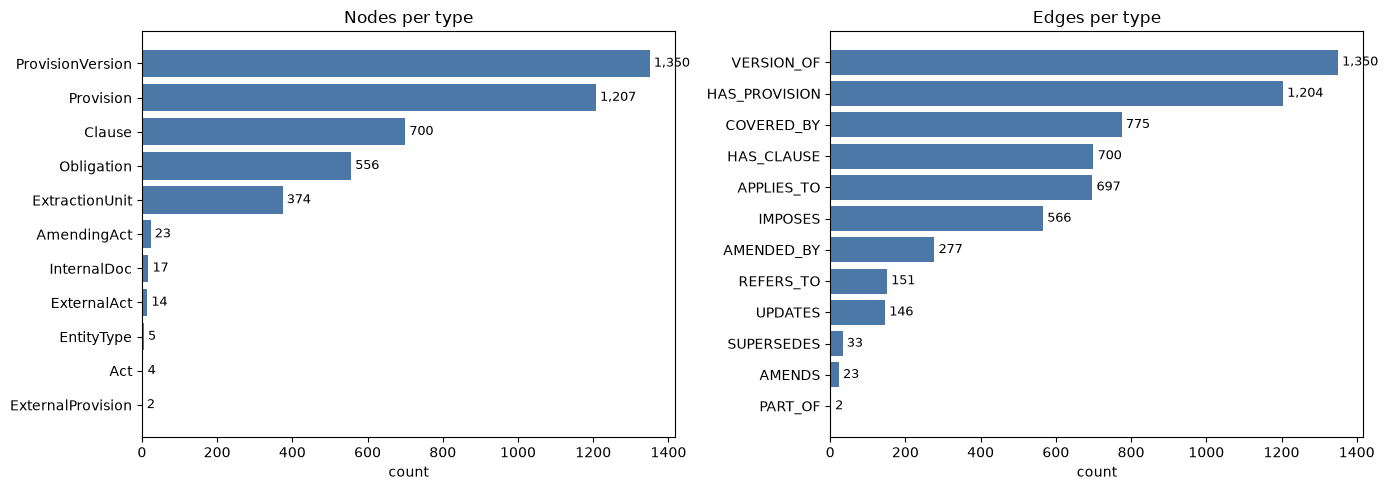

In [2]:
# --- nodes per type and edges per type --------------------------------------------------------------------
nodes = q("SELECT type, COUNT(*) AS n FROM nodes GROUP BY type ORDER BY n DESC")
edges = q("SELECT type, COUNT(*) AS n FROM edges GROUP BY type ORDER BY n DESC")

# which node types each edge type connects (e.g. Obligation -COVERED_BY-> Clause)
links = q("""
    SELECT s.type AS src_type, e.type AS edge_type, d.type AS dst_type, COUNT(*) AS n
    FROM edges e
    LEFT JOIN nodes s ON s.id = e.src
    LEFT JOIN nodes d ON d.id = e.dst
    GROUP BY 1, 2, 3 ORDER BY n DESC
""")

print(f"nodes: {nodes['n'].sum():,} in {len(nodes)} types   ·   edges: {edges['n'].sum():,} in {len(edges)} types")
display(nodes, edges, links)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, df, title in ((ax[0], nodes, "Nodes per type"), (ax[1], edges, "Edges per type")):
    bars = a.barh(df["type"], df["n"], color="#4C78A8")
    a.invert_yaxis()
    a.set_title(title)
    a.bar_label(bars, labels=[f"{v:,}" for v in df["n"]], padding=3, fontsize=9)
    a.set_xlabel("count")
plt.tight_layout()
plt.show()

4,252 nodes, 5,902 edges, 383 connected parts


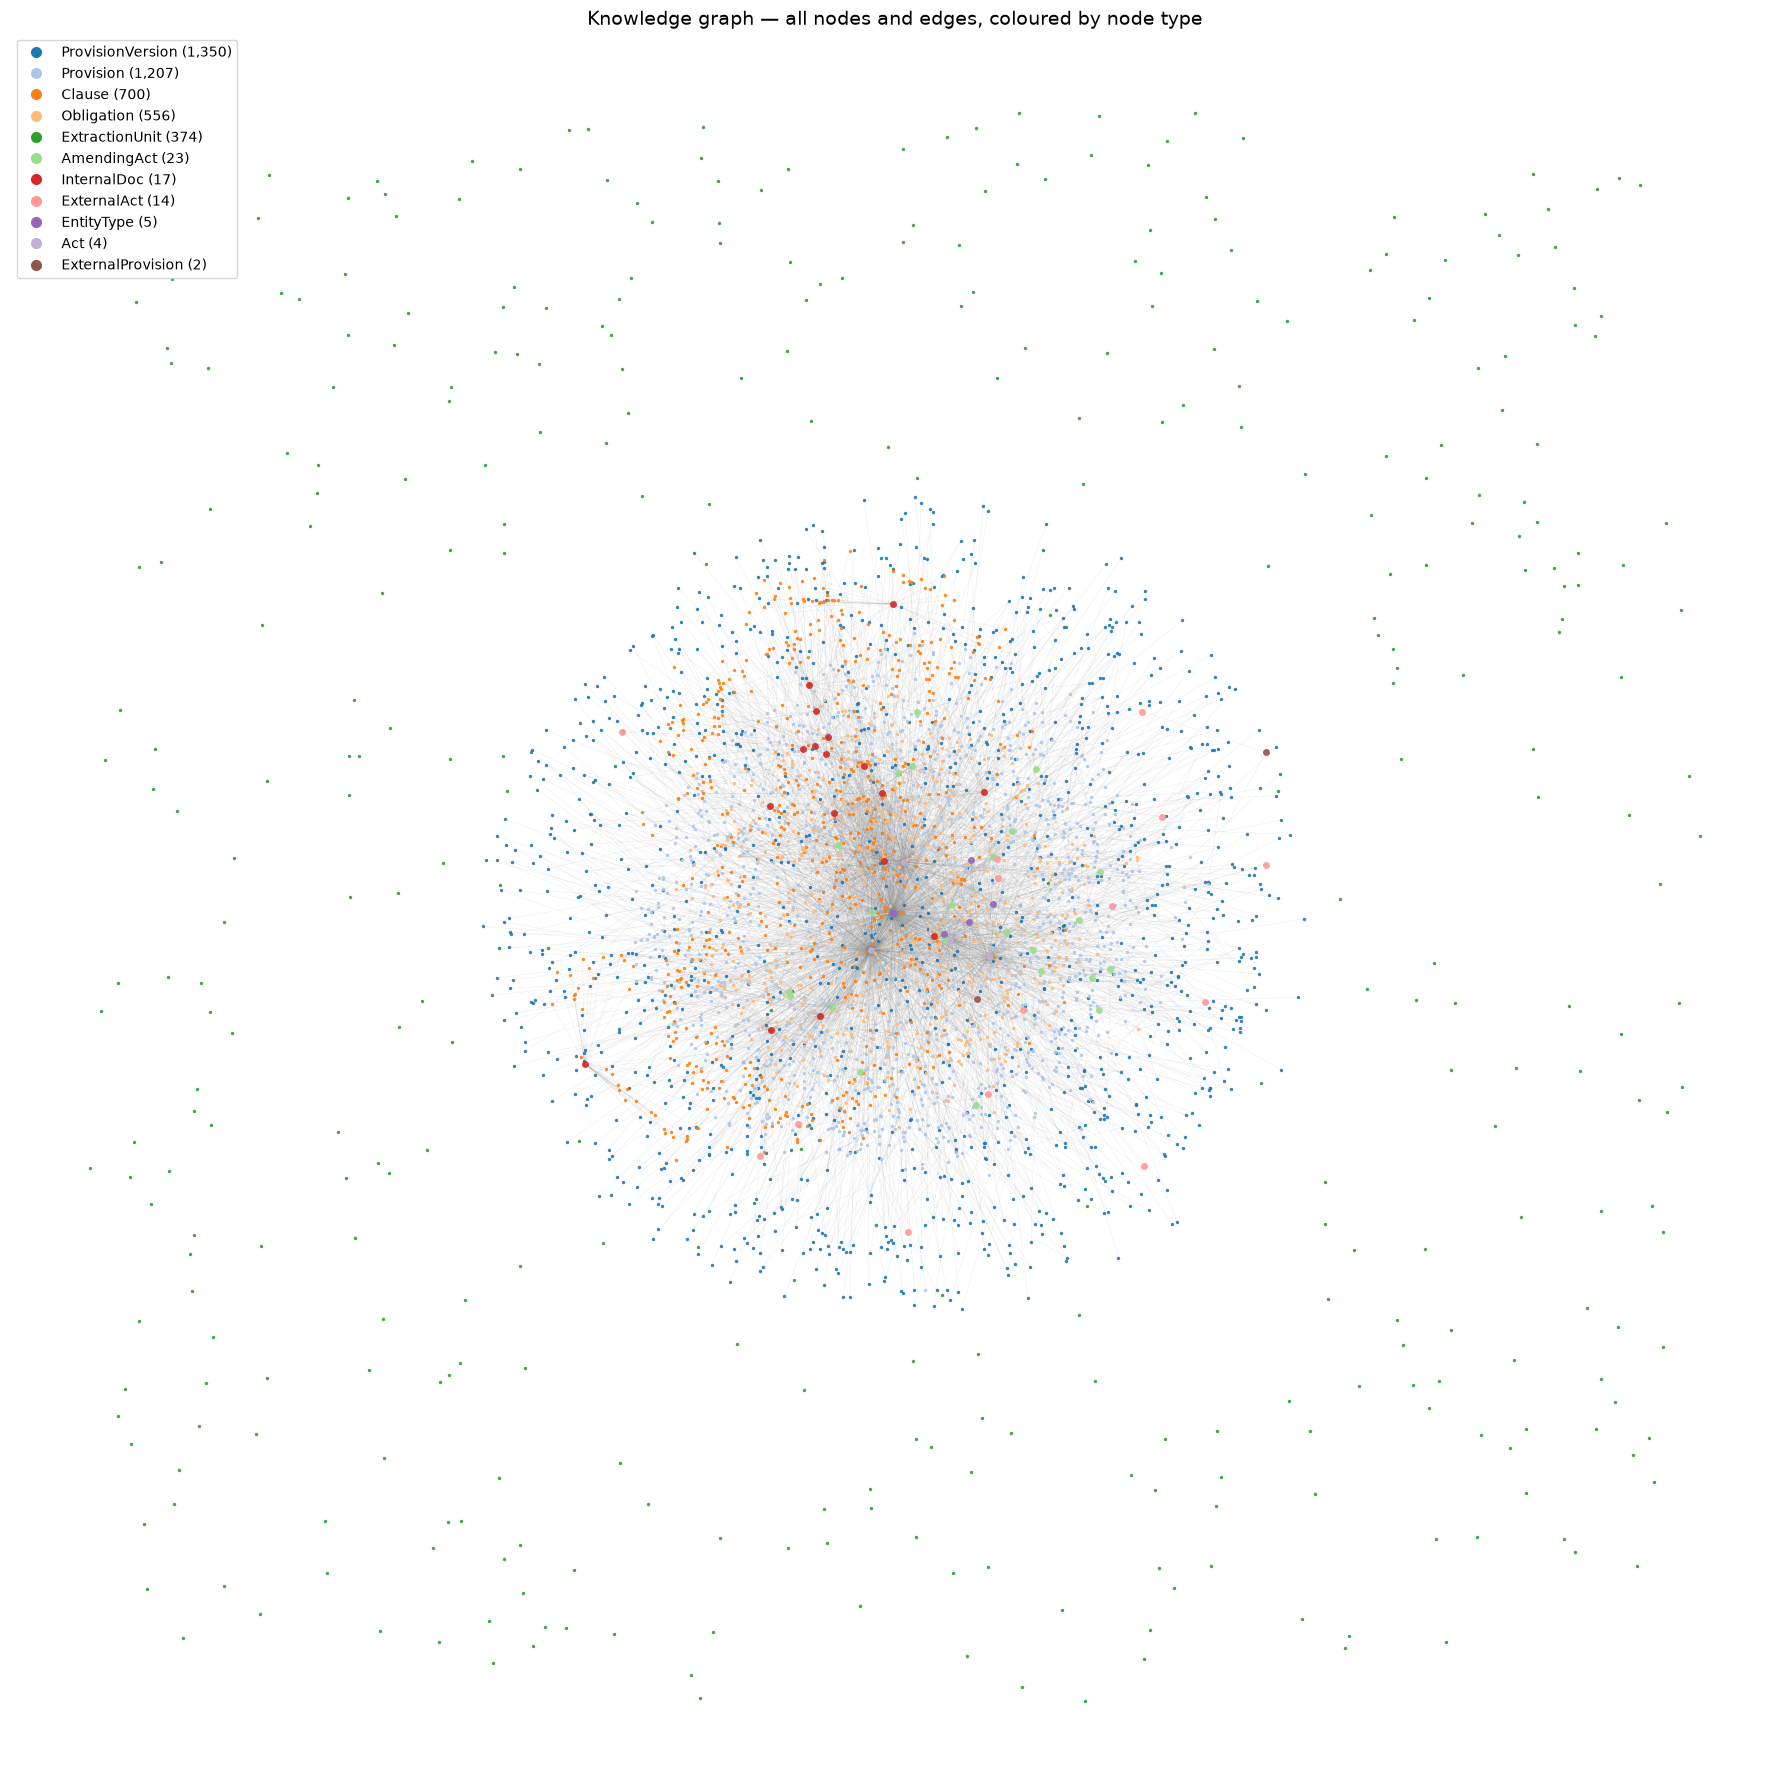

In [3]:
# --- the whole graph ----------------------------------------------------------------------------------------
import networkx as nx
from matplotlib.lines import Line2D

nd = q("SELECT id, type FROM nodes")
ed = q("SELECT src, dst, type FROM edges")

G = nx.Graph()                                   # undirected, for the layout only
G.add_nodes_from((r.id, {"type": r.type}) for r in nd.itertuples())
# edges whose end is not a node (e.g. a reference to an act outside the corpus) are left out
known = set(nd["id"])
G.add_edges_from((r.src, r.dst, {"type": r.type}) for r in ed.itertuples() if r.src in known and r.dst in known)
print(f"{G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges, "
      f"{nx.number_connected_components(G)} connected parts")

# one colour per node type
types = nd["type"].value_counts().index.tolist()
palette = plt.get_cmap("tab20").colors
color_of = {t: palette[i % len(palette)] for i, t in enumerate(types)}

pos = nx.spring_layout(G, k=0.6 / max(G.number_of_nodes(), 1) ** 0.5, iterations=60, seed=7)

fig, ax = plt.subplots(figsize=(18, 18))
nx.draw_networkx_edges(G, pos, ax=ax, width=0.2, alpha=0.25, edge_color="#888888")
for t in types:
    ids = [n for n, d in G.nodes(data=True) if d["type"] == t]
    nx.draw_networkx_nodes(G, pos, nodelist=ids, ax=ax, node_size=6 if len(ids) > 200 else 25,
                           node_color=[color_of[t]], alpha=0.9, linewidths=0)
ax.legend(handles=[Line2D([0], [0], marker="o", linestyle="", markersize=8, markerfacecolor=color_of[t],
                          markeredgewidth=0, label=f"{t} ({(nd['type'] == t).sum():,})") for t in types],
          loc="upper left", fontsize=10, frameon=True)
ax.set_title("Knowledge graph — all nodes and edges, coloured by node type", fontsize=14)
ax.axis("off")
plt.tight_layout()
plt.show()

In [39]:
# --- the graph by unique relationships (plotly) ---------------------------------------------------------------
import math
import networkx as nx
import plotly.graph_objects as go

node_counts = q("SELECT type, COUNT(*) AS n FROM nodes GROUP BY type")
links = q("""
    SELECT COALESCE(s.type, '(outside)') AS src_type, e.type AS edge_type,
           COALESCE(d.type, '(outside)') AS dst_type, COUNT(*) AS n
    FROM edges e LEFT JOIN nodes s ON s.id = e.src LEFT JOIN nodes d ON d.id = e.dst
    GROUP BY 1, 2, 3 ORDER BY n DESC
""")
count_of = dict(zip(node_counts["type"], node_counts["n"]))
types = sorted(set(links["src_type"]) | set(links["dst_type"]) | set(count_of), key=lambda t: -count_of.get(t, 0))

# layout of the node types (a small graph: one node per type)
T = nx.Graph()
T.add_nodes_from(types)
T.add_edges_from((r.src_type, r.dst_type) for r in links.itertuples() if r.src_type != r.dst_type)
pos = nx.kamada_kawai_layout(T) if T.number_of_edges() else nx.circular_layout(T)

def curve(p0, p1, bend, n=30):
    """Points of a quadratic curve from p0 to p1; ``bend`` separates parallel relationships."""
    (x0, y0), (x1, y1) = p0, p1
    mx, my = (x0 + x1) / 2, (y0 + y1) / 2
    dx, dy = x1 - x0, y1 - y0
    cx, cy = mx - dy * bend, my + dx * bend
    ts = [i / n for i in range(n + 1)]
    xs = [(1 - t) ** 2 * x0 + 2 * (1 - t) * t * cx + t ** 2 * x1 for t in ts]
    ys = [(1 - t) ** 2 * y0 + 2 * (1 - t) * t * cy + t ** 2 * y1 for t in ts]
    return xs, ys

def loop(p, k, r=0.07):
    """A small loop next to a node, for relationships between nodes of the same type."""
    x, y = p
    a0 = math.pi / 2 + k * 0.9
    ts = [a0 + 2 * math.pi * i / 40 for i in range(41)]
    cx, cy = x + r * math.cos(a0), y + r * math.sin(a0)
    return [cx + r * math.cos(t) for t in ts], [cy + r * math.sin(t) for t in ts]

edge_colors = {}
palette = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#72B7B2", "#B279A2", "#FF9DA6", "#9D755D",
           "#BAB0AC", "#EECA3B", "#2F4B7C", "#A05195"]
for i, et in enumerate(links["edge_type"].unique()):
    edge_colors[et] = palette[i % len(palette)]

fig = go.Figure()
seen_pairs, max_n = {}, links["n"].max()
for r in links.itertuples():
    pair = tuple(sorted((r.src_type, r.dst_type)))
    k = seen_pairs.get(pair, 0)
    seen_pairs[pair] = k + 1
    if r.src_type == r.dst_type:
        xs, ys = loop(pos[r.src_type], k)
    else:
        sign = 1 if (r.src_type, r.dst_type) == pair else -1
        xs, ys = curve(pos[r.src_type], pos[r.dst_type], bend=sign * (0.12 + 0.12 * k))
    width = 1 + 7 * math.sqrt(r.n / max_n)
    label = f"{r.src_type} —{r.edge_type}→ {r.dst_type}<br>{r.n:,} edges"
    fig.add_trace(go.Scatter(x=xs, y=ys, mode="lines", line=dict(width=width, color=edge_colors[r.edge_type]),
                             opacity=0.75, hoverinfo="skip", legendgroup=r.edge_type, name=r.edge_type,
                             showlegend=r.edge_type not in {t.name for t in fig.data}))
    # arrow head at the target end + a hover point in the middle
    m = len(xs) // 2
    fig.add_annotation(x=xs[-1], y=ys[-1], ax=xs[-4], ay=ys[-4], xref="x", yref="y", axref="x", ayref="y",
                       showarrow=True, arrowhead=3, arrowsize=1.2, arrowwidth=max(1, width / 2),
                       arrowcolor=edge_colors[r.edge_type], standoff=14)
    fig.add_trace(go.Scatter(x=[xs[m]], y=[ys[m]], mode="markers+text", text=[r.edge_type],
                             textfont=dict(size=9, color=edge_colors[r.edge_type]), textposition="top center",
                             marker=dict(size=7, color=edge_colors[r.edge_type]), hovertext=[label],
                             hoverinfo="text", legendgroup=r.edge_type, showlegend=False))

# the node types
xs = [pos[t][0] for t in types]
ys = [pos[t][1] for t in types]
sizes = [18 + 40 * math.sqrt(count_of.get(t, 0) / max(count_of.values())) for t in types]
fig.add_trace(go.Scatter(
    x=xs, y=ys, mode="markers+text", text=[f"<b>{t}</b><br>{count_of.get(t, 0):,}" for t in types],
    textposition="middle center", textfont=dict(size=10, color="#111"),
    marker=dict(size=sizes, color="#F2F2F2", line=dict(width=2, color="#555")),
    hovertext=[f"{t}: {count_of.get(t, 0):,} nodes" for t in types], hoverinfo="text", name="node types"))

fig.update_layout(title="Knowledge graph — node types and their relationships (width = number of edges)",
                  showlegend=True, legend_title_text="edge type", height=850, plot_bgcolor="white",
                  xaxis=dict(visible=False), yaxis=dict(visible=False, scaleanchor="x"),
                  margin=dict(l=10, r=10, t=60, b=10))
fig.show()

In [5]:
# --- helpers: nodes of one type as a table + a profile of every attribute --------------------------------
def nodes_df(node_type: str) -> pd.DataFrame:
    """All nodes of a type: id, valid_from, valid_to + every attribute of props as its own column."""
    raw = q("SELECT id, valid_from, valid_to, props FROM nodes WHERE type = ?", (node_type,))
    props = pd.json_normalize(raw["props"].map(json.loads).tolist(), max_level=0)
    return pd.concat([raw.drop(columns="props"), props], axis=1)

def _hashable(v):
    """Lists / dicts become JSON text so they can be counted."""
    return json.dumps(v, ensure_ascii=False, sort_keys=True) if isinstance(v, (list, dict)) else v

def profile(df: pd.DataFrame, top: int = 5, max_text: int = 80) -> pd.DataFrame:
    """One row per attribute: filled / empty, number of unique values, value type, the most common values."""
    rows = []
    for col in df.columns:
        s = df[col].map(_hashable)
        filled = s.notna() & (s.astype(str) != "")
        vals = s[filled]
        types = sorted({type(v).__name__ for v in df[col][filled]})
        common = vals.astype(str).value_counts().head(top)
        rows.append({
            "attribute": col,
            "filled": int(filled.sum()),
            "empty": int((~filled).sum()),
            "unique": int(vals.nunique()),
            "type": ", ".join(types),
            "most common (count)": " | ".join(f"{v[:max_text]}{'…' if len(v) > max_text else ''} ({n})"
                                              for v, n in common.items()),
        })
    return pd.DataFrame(rows)

def show_unique(df: pd.DataFrame, cols: list[str]):
    """Full value counts of low-cardinality attributes."""
    for c in cols:
        if c in df:
            print(f"\n── {c}")
            display(df[c].map(_hashable).value_counts(dropna=False).rename("count").to_frame())

In [6]:
# --- Act: one node per regulation -------------------------------------------------------------------------------
acts = nodes_df("Act")
print(f"{len(acts)} acts")
display(profile(acts))
# every attribute of every act (only 4 rows, so show them in full, one act per column)
display(acts.set_index("id").T)

4 acts


,attribute,filled,empty,unique,type,most common (count)
0,id,4,0,4,str,act:2060636 (1) | act:4822603 (1) | act:4964423 (1) | act:5679194 (1)
1,valid_from,0,4,0,,
2,valid_to,0,4,0,,
3,doc_id,4,0,4,str,2060636 (1) | 4822603 (1) | 4964423 (1) | 5679194 (1)
4,url,4,0,4,str,https://matsne.gov.ge/ka/document/view/2060636 (1) | https://matsne.gov.ge/ka/document/view/4822603 (1) | https://ma...
5,number,4,0,4,str,100/04 (1) | 44/04 (1) | 151/04 (1) | 192/04 (1)
6,type,4,0,1,str,საქართველოს ეროვნული ბანკის პრეზიდენტის ბრძანება (4)
7,authority,4,0,1,str,საქართველოს ეროვნული ბანკის პრეზიდენტი (4)
8,adopted,4,0,4,str,2013-10-28 (1) | 2020-03-13 (1) | 2020-08-17 (1) | 2022-12-29 (1)
9,published,4,0,4,str,2013-10-30 (1) | 2020-03-17 (1) | 2020-08-18 (1) | 2022-12-30 (1)


id,act:2060636,act:4822603,act:4964423,act:5679194
valid_from,None,None,None,None
valid_to,None,None,None,None
doc_id,2060636,4822603,4964423,5679194
url,https://matsne.gov.ge/ka/document/view/2060636,https://matsne.gov.ge/ka/document/view/4822603,https://matsne.gov.ge/ka/document/view/4964423,https://matsne.gov.ge/ka/document/view/5679194
number,100/04,44/04,151/04,192/04
type,საქართველოს ეროვნული ბანკის პრეზიდენტის ბრძანება,საქართველოს ეროვნული ბანკის პრეზიდენტის ბრძანება,საქართველოს ეროვნული ბანკის პრეზიდენტის ბრძანება,საქართველოს ეროვნული ბანკის პრეზიდენტის ბრძანება
authority,საქართველოს ეროვნული ბანკის პრეზიდენტი,საქართველოს ეროვნული ბანკის პრეზიდენტი,საქართველოს ეროვნული ბანკის პრეზიდენტი,საქართველოს ეროვნული ბანკის პრეზიდენტი
adopted,2013-10-28,2020-03-13,2020-08-17,2022-12-29
published,2013-10-30,2020-03-17,2020-08-18,2022-12-30
effective_from,NaN,2020-04-15,2021-01-01,2023-01-01


In [7]:
# --- Provision: one node per article / paragraph / sub-point of an act (all its versions share it) -----------
prov = nodes_df("Provision")
print(f"{len(prov):,} provisions")
display(profile(prov))
show_unique(prov, ["act", "level", "placeholder"])

# how many provisions per act and level
display(pd.crosstab(prov["act"], prov["level"], margins=True, margins_name="total"))

# a few examples of one act, in document order
display(prov[prov["act"] == "4964423"].sort_values("order").head(10)[["id", "path", "display", "level", "title"]])

1,207 provisions


,attribute,filled,empty,unique,type,most common (count)
0,id,1207,0,1207,str,prov:2060636/ord1 (1) | prov:2060636/ord2 (1) | prov:2060636/art1 (1) | prov:2060636/art1/p1 (1) | prov:2060636/art1...
1,valid_from,1204,3,17,str,2013-10-30 (518) | 2023-01-01 (308) | 2020-04-15 (129) | 2021-01-01 (120) | 2022-05-03 (47)
2,valid_to,0,1207,0,,
3,act,1207,0,4,str,2060636 (593) | 5679194 (306) | 4964423 (167) | 4822603 (141)
4,path,1207,0,935,str,ord1 (4) | ord2 (4) | art1 (4) | art1/p1 (4) | art1/p2 (4)
5,level,1207,0,4,str,sub (609) | paragraph (472) | article (115) | order_article (11)
6,order,1204,3,591,float,0.0 (4) | 1.0 (4) | 2.0 (4) | 3.0 (4) | 4.0 (4)
7,display,1207,0,935,str,"ბრძანების მუხლი 1 (4) | ბრძანების მუხლი 2 (4) | მუხლი 1 (4) | მუხლი 1, პუნქტი 1 (4) | მუხლი 1, პუნქტი 2 (4)"
8,title,1207,0,1197,str,ზოგადი დებულებები (3) | ტერმინთა განმარტება (3) | ა) არის გამოშვებული და განაღდებული; (2) | გ) არ არის უზრუნველყოფილ...
9,placeholder,143,1064,2,bool,False (140) | True (3)



── act


,count
act,
2060636,593
5679194,306
4964423,167
4822603,141



── level


,count
level,
sub,609
paragraph,472
article,115
order_article,11



── placeholder


,count
placeholder,
NaN,1064
False,140
True,3


level,article,order_article,paragraph,sub,total
act,,,,,
2060636,66,2,219,306,593
4822603,9,3,54,75,141
4964423,14,3,60,90,167
5679194,26,3,139,138,306
total,115,11,472,609,1207


,id,path,display,level,title
897,prov:4964423/ord1,ord1,ბრძანების მუხლი 1,order_article,"დამტკიცდეს მონაცემებზე დაფუძნებული სტატისტიკური, ხელოვნური ინტელექტის და მანქანური სწავლებ"
898,prov:4964423/ord2,ord2,ბრძანების მუხლი 2,order_article,ეს ბრძანება ამოქმედდეს 2021 წლის 1 იანვრიდან.
899,prov:4964423/ord3,ord3,ბრძანების მუხლი 3,order_article,1. ამ ბრძანების ამოქმედების მომენტიდან მისი მოქმედება გავრცელდეს ამ ბრძანების ამოქმედების
900,prov:4964423/art1,art1,მუხლი 1,article,ზოგადი დებულებები
901,prov:4964423/art1/p1,art1/p1,"მუხლი 1, პუნქტი 1",paragraph,"1. ამ დებულების მიზანია მონაცემებზე დაფუძნებული სტატისტიკური, ხელოვნური ინტელექტის"
902,prov:4964423/art1/p2,art1/p2,"მუხლი 1, პუნქტი 2",paragraph,2. ეს დებულება განსაზღვრავს მოდელების აგებისა და გამოყენების პროცესს და მის ძირითად
903,prov:4964423/art1/p3,art1/p3,"მუხლი 1, პუნქტი 3",paragraph,"3. ეს დებულება ვრცელდება იმ მოდელებზე, რომლებზე დაყრდნობითაც მოდელის გამომყენებელ ს"
904,prov:4964423/art1/p4,art1/p4,"მუხლი 1, პუნქტი 4",paragraph,"4. მოდელის გამომყენებელ სუბიექტს უნდა ჰქონდეს მოდელების რისკების მართვის სისტემა, რ"
905,prov:4964423/art2,art2,მუხლი 2,article,ტერმინთა განმარტება
906,prov:4964423/art2/sა,art2/sა,"მუხლი 2, ქვეპუნქტი ა",sub,"ა) მონაცემებზე დაფუძნებული სტატისტიკური, ხელოვნური ინტელექტის და მანქანური სწავლები"


In [8]:
prov['title'].value_counts(dropna=False)

title
ზოგადი დებულებები                                                                        3
ტერმინთა განმარტება                                                                      3
ა) არის გამოშვებული და განაღდებული;                                                      2
გ) არ არის უზრუნველყოფილი და მასზე არ ვრცელდება ინსტრუმენტის გამომშვების ან მასთან       2
ე.ა) გამოთხოვის უფლების გამოყენებისათვის კომერციულმა ბანკმა უნდა მიიღოს წინასწარი თან    2
                                                                                        ..
5. 2019 წლის პირველი იანვრიდან 2022 წლის პირველ იანვრამდე უცხოურ ვალუტაში გაცემული       1
6. ამ დებულების მე-2 მუხლის პირველი პუნქტის „ო“ ქვეპუნქტის მიხედვით საშეღავათო პერი      1
მუხლი 5, პუნქტი 5, ქვეპუნქტი ა (ტექსტი მიუწვდომელია)                                     1
მუხლი 5, პუნქტი 6 (ტექსტი მიუწვდომელია)                                                  1
მუხლი 2, პუნქტი 2, ქვეპუნქტი ბ (ტექსტი მიუწვდომელია)                                

In [9]:
# --- ProvisionVersion: the text of a provision during one period (new version after each amendment) --------
pv = nodes_df("ProvisionVersion")
pv["text_len"] = pv["text"].fillna("").str.len()
pv["in_force_now"] = pv["valid_to"].isna()
print(f"{len(pv):,} provision versions")
display(profile(pv))
show_unique(pv, ["act", "status", "source", "change_type", "level", "in_force_now"])

# versions per provision: how often provisions were amended, per act
per_prov = pv.groupby(["act", "path"]).size().rename("versions").reset_index()
display(pd.crosstab(per_prov["act"], per_prov["versions"], margins=True, margins_name="total")
          .rename_axis(columns="versions per provision"))

# text length per act
display(pv.groupby("act")["text_len"].describe().round(0))

# the full history of one provision: the 44/04 grace-period definition (2(1)(ო))
hist = pv[(pv["act"] == "4822603") & (pv["path"] == "art2/p1/sო")].sort_values("valid_from")
for r in hist.itertuples():
    print(f"\n{r.valid_from} → {r.valid_to or 'now'} · {r.status} · {r.change_type} · notes: {r.amendment_notes}")
    print(r.text)

1,350 provision versions


,attribute,filled,empty,unique,type,most common (count)
0,id,1350,0,1350,str,pv:2060636/ord1@2013-10-30 (1) | pv:2060636/ord2@2013-10-30 (1) | pv:2060636/art1@2013-10-30 (1) | pv:2060636/art1/p...
1,valid_from,1350,0,25,str,2013-10-30 (518) | 2023-01-01 (339) | 2020-04-15 (129) | 2021-01-01 (120) | 2017-12-19 (59)
2,valid_to,146,1204,22,str,2023-01-01 (31) | 2017-12-19 (26) | 2017-08-15 (18) | 2015-03-10 (14) | 2023-07-05 (9)
3,act,1350,0,4,str,2060636 (692) | 5679194 (307) | 4964423 (179) | 4822603 (172)
4,path,1350,0,933,str,art1/p2 (6) | art7/p2 (6) | art5/p5 (6) | ord2 (5) | art1/p4 (5)
5,text,1222,128,1203,str,ინსტრუმენტზე დივიდენდის გაცემა არ უნდა იყოს კომერციული ბანკის საკრედიტო მდგომარე… (3) | რისკის პოზიციები და/ან მათი ...
6,label,1212,138,91,str,2. (118) | 1. (116) | ბ) (100) | ა) (99) | 3. (94)
7,heading,126,1224,115,str,ზოგადი დებულებები (3) | ტერმინთა განმარტება (3) | საკრედიტო რისკის მიხედვით შეწონილი რისკის პოზიციები (2) | სავალუტო...
8,chapter,690,660,19,str,XV (149) | XVII (116) | XIII (76) | II (54) | IV (53)
9,status,1350,0,2,str,active (1327) | repealed (23)



── act


,count
act,
2060636,692
5679194,307
4964423,179
4822603,172



── status


...


── in_force_now


,count
in_force_now,
True,1204
False,146


versions per provision,1,2,3,total
act,,,,
2060636,498,85,8,591
4822603,113,22,5,140
4964423,157,8,2,167
5679194,305,1,0,306
total,1073,116,15,1204


,count,mean,std,min,25%,50%,75%,max
act,,,,,,,,
2060636,692.0,211.0,253.0,0.0,66.0,158.0,278.0,3972.0
4822603,172.0,249.0,168.0,0.0,140.0,212.0,330.0,761.0
4964423,179.0,209.0,203.0,0.0,68.0,159.0,266.0,1204.0
5679194,307.0,199.0,164.0,0.0,80.0,159.0,288.0,1008.0



2020-04-15 → 2022-04-01 · active · added · notes: []
საშეღავათო პერიოდი – პერიოდი, რომლის განმავლობაშიც მსესხებელი/თანამსესხებელი ყოველთვიურად სრულად არ იხდის სესხზე დარიცხულ პროცენტს, საკომისიოს ან/და ძირს და რომლის გადახდასაც საშეღავათო პერიოდის დასრულების შემდეგ დაიწყებს. ამ ქვეპუნქტის მიზნებისთვის საშეღავათო პერიოდად არ ჩაითვლება სესხის ყოველთვიური გადასახდელებისგან განსხვავებული დაფარვის გრაფიკი, თუ აღნიშნული მორგებულია მსესხებლის/თანამსესხებლის მიერ შემოსავლების მიღების პერიოდულობაზე;

2022-04-01 → 2023-07-05 · active · modified · notes: []
საშეღავათო პერიოდი – პერიოდი, რომლის განმავლობაშიც მსესხებელი/თანამსესხებელი ყოველთვიურად სრულად არ იხდის სესხზე დარიცხულ პროცენტს, საკომისიოს ან/და ძირს და რომლის გადახდასაც საშეღავათო პერიოდის დასრულების შემდეგ დაიწყებს. ამ ქვეპუნქტის მიზნებისთვის საშეღავათო პერიოდად არ ჩაითვლება ის პერიოდი, როდესაც ხდება რევოლვირებად საკრედიტო პროდუქტებზე გადახდილ ყოველთვიურ გადასახდელში შემავალი ძირის კვლავ ათვისება ან/და მოქმედებს სესხის ყოველთვიური გადა

In [10]:
pv.head()

,id,valid_from,valid_to,act,path,text,label,heading,chapter,status,...,level,amendment_notes,order,article_title,act_short,display,title,index_text,text_len,in_force_now
0,pv:2060636/ord1@2013-10-30,2013-10-30,NaN,2060636,ord1,დამტკიცდეს კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულება თანდართულ დანართთან ერთად.,,NaN,NaN,active,...,order_article,[],0,დამტკიცდეს კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულება თანდარ,კაპიტალის ადეკვატურობა,ბრძანების მუხლი 1,დამტკიცდეს კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულება თანდარ,კაპიტალის ადეკვატურობა › ბრძანების მუხლი 1. დამტკიცდეს კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახ...,110,True
1,pv:2060636/ord2@2013-10-30,2013-10-30,NaN,2060636,ord2,ეს ბრძანება ამოქმედდეს გამოქვეყნებისთანავე.,,NaN,NaN,active,...,order_article,[],1,ეს ბრძანება ამოქმედდეს გამოქვეყნებისთანავე.,კაპიტალის ადეკვატურობა,ბრძანების მუხლი 2,ეს ბრძანება ამოქმედდეს გამოქვეყნებისთანავე.,კაპიტალის ადეკვატურობა › ბრძანების მუხლი 2. ეს ბრძანება ამოქმედდეს გამოქვეყნებისთანავე.\nეს ბრძანება ამოქმედდეს გამო...,43,True
2,pv:2060636/art1@2013-10-30,2013-10-30,NaN,2060636,art1,,,ზოგადი დებულებები,I,active,...,article,[],2,ზოგადი დებულებები,კაპიტალის ადეკვატურობა,მუხლი 1,ზოგადი დებულებები,კაპიტალის ადეკვატურობა › მუხლი 1. ზოგადი დებულებები,0,True
3,pv:2060636/art1/p1@2013-10-30,2013-10-30,NaN,2060636,art1/p1,ამ დებულების მიზანია ხელი შეუწყოს კომერციული ბანკების გაკოტრების რისკების შემცირებასა და მთლიანი საბანკო სისტემის ფი...,1.,NaN,I,active,...,paragraph,[],3,ზოგადი დებულებები,კაპიტალის ადეკვატურობა,"მუხლი 1, პუნქტი 1",1. ამ დებულების მიზანია ხელი შეუწყოს კომერციული ბანკების გაკოტრების რისკების შემცირ,კაპიტალის ადეკვატურობა › მუხლი 1. ზოგადი დებულებები › პუნქტი 1\n1. ამ დებულების მიზანია ხელი შეუწყოს კომერციული ბანკ...,403,True
4,pv:2060636/art1/p2@2013-10-30,2013-10-30,NaN,2060636,art1/p2,საბანკო საქმიანობის ზედამხედველობის მთავარი ბერკეტია ბანკების კაპიტალის ადეკვატურობის მინიმალური მოთხოვნების დადგენა...,2.,NaN,I,active,...,paragraph,[],4,ზოგადი დებულებები,კაპიტალის ადეკვატურობა,"მუხლი 1, პუნქტი 2",2. საბანკო საქმიანობის ზედამხედველობის მთავარი ბერკეტია ბანკების კაპიტალის ადეკვატუ,კაპიტალის ადეკვატურობა › მუხლი 1. ზოგადი დებულებები › პუნქტი 2\n2. საბანკო საქმიანობის ზედამხედველობის მთავარი ბერკე...,145,True


In [11]:
pv['article_title'].value_counts(dropna=False)

article_title
ტერმინთა განმარტება                                                                           71
ზოგადი დებულებები                                                                             50
ტერმინთა განმარტებები                                                                         37
დამატებით პირველად კაპიტალად კლასიფიკაციის კრიტერიუმები                                       33
მოდელის შიდა ვალიდაცია                                                                        33
                                                                                              ..
ეს ბრძანება ამოქმედდეს 2021 წლის 1 იანვრიდან.                                                  1
1. ამ ბრძანების ამოქმედების მომენტიდან მისი მოქმედება გავრცელდეს ამ ბრძანების ამოქმედების      1
დამტკიცდეს ფიზიკური პირის დაკრედიტების შესახებ დებულება თანდართულ დანართებთან ერთად.           1
ამ ბრძანების ამოქმედებისთანავე ძალადაკარგულად გამოცხადდეს „ფიზიკური პირის დაკრედიტების შეს     1
ეს ბრძანება ამოქ

In [12]:
pv['title'].value_counts(dropna=False)

title
ზოგადი დებულებები                                                                      3
ტერმინთა განმარტება                                                                    3
4.                                                                                     3
2.                                                                                     3
ო) ფიზიკური პირის მიერ დაფინანსებული ინსტრუმენტები, რომლებიც ბუღალტრული აღრიცხვის მ    3
                                                                                      ..
2. ამ მუხლით განსაზღვრული სესხის გამცემი ორგანიზაციის შიდა პოლიტიკა-პროცედურები, ას    1
3. სესხის გამცემი ორგანიზაციის მიერ ამ დებულებით გათვალისწინებული მოთხოვნების არაჯე    1
გარდამავალი დებულებები                                                                 1
3. ამ დებულების მოთხოვნები არ ვრცელდება ამ ბრძანების ამოქმედებამდე, 2019 წლის პირვე    1
6. ამ დებულების მე-2 მუხლის პირველი პუნქტის „ო“ ქვეპუნქტის მიხედვით საშეღავათო პერი    1
Name: count, Le

In [13]:
# --- AmendingAct: one node per amending order ------------------------------------------------------------------
am = nodes_df("AmendingAct")
print(f"{len(am)} amending acts")
display(profile(am))
show_unique(am, ["base_act", "effective_basis", "has_transitional"])

# how many provision versions each amendment created (edges ProvisionVersion -AMENDED_BY-> AmendingAct)
changed = q("SELECT dst AS id, COUNT(*) AS versions_changed FROM edges WHERE type='AMENDED_BY' GROUP BY dst")
am = am.merge(changed, on="id", how="left").fillna({"versions_changed": 0})

# per act, in order: number, dates, how the effective date was found, what it changed
cols = ["base_act", "seq", "number", "date", "published", "effective_from", "effective_basis",
        "has_transitional", "versions_changed", "title"]
display(am.sort_values(["base_act", "seq"])[[c for c in cols if c in am]].reset_index(drop=True))

23 amending acts


,attribute,filled,empty,unique,type,most common (count)
0,id,23,0,23,str,amend:2470749 (1) | amend:2763210 (1) | amend:3778783 (1) | amend:3922106 (1) | amend:4298586 (1)
1,valid_from,23,0,22,str,2023-01-01 (2) | 2014-08-25 (1) | 2015-03-10 (1) | 2017-08-15 (1) | 2017-12-19 (1)
2,valid_to,0,23,0,,
3,doc_id,23,0,23,str,2470749 (1) | 2763210 (1) | 3778783 (1) | 3922106 (1) | 4298586 (1)
4,number,23,0,23,str,81/04 (1) | 27/04 (1) | 120/04 (1) | 175/04 (1) | 187/04 (1)
5,date,23,0,22,str,2022-12-29 (2) | 2014-08-25 (1) | 2015-03-10 (1) | 2017-08-15 (1) | 2017-12-18 (1)
6,published,23,0,22,str,2022-12-30 (2) | 2014-08-25 (1) | 2015-03-10 (1) | 2017-08-15 (1) | 2017-12-19 (1)
7,effective_from,23,0,22,str,2023-01-01 (2) | 2014-08-25 (1) | 2015-03-10 (1) | 2017-08-15 (1) | 2017-12-19 (1)
8,effective_basis,23,0,3,str,on_publication (16) | explicit_date (6) | published_date (1)
9,has_transitional,23,0,2,bool,False (20) | True (3)



── base_act


,count
base_act,
2060636,13
4822603,7
4964423,2
5679194,1



── effective_basis


,count
effective_basis,
on_publication,16
explicit_date,6
published_date,1



── has_transitional


,count
has_transitional,
False,20
True,3


,base_act,seq,number,date,published,effective_from,effective_basis,has_transitional,versions_changed,title
0,2060636,1,81/04,2014-08-25,2014-08-25,2014-08-25,on_publication,False,7,„კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულების დამტკიცების თაობაზე” საქართველოს ეროვნული...
1,2060636,2,27/04,2015-03-10,2015-03-10,2015-03-10,on_publication,False,17,„კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულების დამტკიცების თაობაზე” საქართველოს ეროვნული...
2,2060636,3,120/04,2017-08-15,2017-08-15,2017-08-15,on_publication,False,29,„კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულების დამტკიცების თაობაზე” საქართველოს ეროვნული...
3,2060636,4,175/04,2017-12-18,2017-12-19,2017-12-19,on_publication,False,59,„კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულების დამტკიცების თაობაზე“ საქართველოს ეროვნული...
4,2060636,5,187/04,2018-08-13,2018-08-14,2018-08-14,on_publication,False,2,„კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულების დამტკიცების თაობაზე“ საქართველოს ეროვნული...
5,2060636,6,243/04,2019-12-19,2019-12-20,2019-12-20,on_publication,False,1,„კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულების დამტკიცების თაობაზე” საქართველოს ეროვნული...
6,2060636,7,7/04,2020-01-13,2020-01-14,2020-01-14,on_publication,False,4,„კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულების დამტკიცების თაობაზე” საქართველოს ეროვნული...
7,2060636,8,90/04,2020-04-27,2020-04-28,2020-04-28,on_publication,False,2,„კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულების დამტკიცების თაობაზე” საქართველოს ეროვნული...
8,2060636,9,57/04,2022-05-10,2022-05-11,2022-05-11,on_publication,False,9,„კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულების დამტკიცების თაობაზე” საქართველოს ეროვნული...
9,2060636,10,195/04,2022-12-29,2022-12-30,2023-01-01,explicit_date,True,22,„კომერციული ბანკების კაპიტალის ადეკვატურობის მოთხოვნების შესახებ დებულების დამტკიცების თაობაზე“ საქართველოს ეროვნული...


# OBLIGATIONS ANALYSIS

In [14]:
# --- Obligation: attributes, value distributions and a few examples ----------------------------------------
ob = nodes_df("Obligation")
ob["in_force_now"] = ob["valid_to"].isna()
print(f"{len(ob):,} obligation nodes ({ob['in_force_now'].sum():,} in force now) · acts: {ob['act'].value_counts().to_dict()}")
display(profile(ob))

# the categorical attributes, in full
show_unique(ob, ["act", "deontic", "domain", "severity", "category", "in_force_now", "amendment_number"])

# lists / nested fields: applies_to (entity types) and required_doc (which internal document should hold the duty)
ob["applies_to_str"] = ob["applies_to"].map(lambda v: ", ".join(v) if isinstance(v, list) else v)
ob["req_basis"] = ob["required_doc"].map(lambda d: d.get("basis") if isinstance(d, dict) else None)
ob["req_doc_types"] = ob["required_doc"].map(lambda d: ", ".join(d.get("doc_types") or []) if isinstance(d, dict) else None)
ob["n_citations"] = ob["citations"].map(lambda v: len(v) if isinstance(v, list) else 0)
show_unique(ob, ["applies_to_str", "req_basis"])
display(ob["req_doc_types"].str.split(", ").explode().value_counts().head(20).rename("count").to_frame())

# per act: polarity of the duties and where they come from
display(pd.crosstab(ob["act"], ob["deontic"], margins=True, margins_name="total"))
display(ob.groupby("act")[["n_citations"]].describe().round(1))

# a few complete examples (one per act), with their most useful fields
cols = ["id", "act", "source_path", "deontic", "statement", "subject", "action", "condition", "exceptions",
        "deadline_or_frequency", "applies_to_str", "req_doc_types", "req_basis", "location_hint",
        "amendment_number", "valid_from", "valid_to"]
display(ob.groupby("act").head(2)[[c for c in cols if c in ob]].T)

556 obligation nodes (521 in force now) · acts: {'5679194': 209, '4964423': 147, '4822603': 110, '2060636': 90}


,attribute,filled,empty,unique,type,most common (count)
0,id,556,0,556,str,obl:4964423/art1/p4#1@2021-01-01 (1) | obl:4964423/art3/p1#1@2021-01-01 (1) | obl:4964423/art3/p2#1@2021-01-01 (1) |...
1,valid_from,556,0,12,str,2023-01-01 (215) | 2021-01-01 (102) | 2013-10-30 (90) | 2020-04-15 (72) | 2022-05-03 (40)
2,valid_to,35,521,9,str,2023-01-01 (8) | 2023-07-05 (8) | 2022-05-03 (5) | 2023-07-01 (4) | 2022-08-16 (3)
3,statement,556,0,553,str,"მოდელის აგების, შიდა ვალიდაციის ან/და აუდიტის პროცესის აუთსორსინგის შემთხვევაში,… (2) | სესხის გამცემმა ორგანიზაციამ..."
4,deontic,556,0,3,str,must (468) | must_not (53) | may (35)
5,subject,542,14,83,str,კომერციული ბანკი (191) | მოდელის გამომყენებელი სუბიექტი (80) | სესხის გამცემი ორგანიზაცია (68) | კომერციულმა ბანკმა ...
6,applies_to,556,0,9,list,"[""commercial_bank""] (494) | [""commercial_bank"", ""microbank"", ""microfinance_organization"", ""payment_service_p… (22) |..."
7,action,556,0,503,str,სესხის მაქსიმალური ხანგრძლივობის დაწესება (12) | არ ვრცელდება (5) | არ გასცეს სესხი ან/და არ მიიღოს თავდებობა ან უზრ...
8,condition,352,204,288,str,საკრედიტო რისკის კატეგორიის ინდივიდუალური შეფასებისას (10) | მოდელის გამოყენების რისკის შეფასებისას (5) | გადახდისუნ...
9,exceptions,30,526,26,str,ამ დებულებით განსაზღვრული საგამონაკლისო შემთხვევები (3) | ამ დებულების მოთხოვნების დაცვა (2) | თუ კომერციულ ბანკს სა...



── act


,count
act,
5679194,209
4964423,147
4822603,110
2060636,90



── deontic


...

,count
req_basis,
inferred,254
NaN,239
explicit,63


,count
req_doc_types,
methodology,123
procedure,80
policy,62
validation_report,31
internal_report,21
credit_policy,17
regulatory_report,13
monitoring_report,11
loan_agreement,11


deontic,may,must,must_not,total
act,,,,
2060636,5,74,11,90
4822603,9,70,31,110
4964423,0,147,0,147
5679194,21,177,11,209
total,35,468,53,556


n_citations                                   
              count mean  std  min  25%  50%  75%  max
act                                                   
2060636        90.0  1.0  0.0  1.0  1.0  1.0  1.0  1.0
4822603       110.0  1.0  0.0  1.0  1.0  1.0  1.0  1.0
4964423       147.0  1.0  0.0  1.0  1.0  1.0  1.0  1.0
5679194       209.0  1.0  0.1  1.0  1.0  1.0  1.0  3.0

,0,1,147,148,257,258,466,467
id,obl:4964423/art1/p4#1@2021-01-01,obl:4964423/art3/p1#1@2021-01-01,obl:4822603/art1/p5#1@2020-04-15,obl:4822603/art1/p7#1@2020-04-15,obl:5679194/art1/p2#1@2023-01-01,obl:5679194/art1/p2#2@2023-01-01,obl:2060636/art1/p1#1@2013-10-30,obl:2060636/art1/p3#1@2013-10-30
act,4964423,4964423,4822603,4822603,5679194,5679194,2060636,2060636
source_path,art1/p4,art3/p1,art1/p5,art1/p7,art1/p2,art1/p2,art1/p1,art1/p3
deontic,must,must,must,must,must,must,must,must
statement,"მოდელის გამომყენებელ სუბიექტს უნდა ჰქონდეს მოდელების რისკების მართვის სისტემა, რომელიც უნდა შეესაბამებოდეს სუბიექტის...",მოდელების გამოყენებასთან დაკავშირებული რისკების მართვის პროცედურები უნდა აისახოს მოდელის გამომყენებელი სუბიექტის შიდ...,"ამ მუხლის მე-4 პუნქტითა და მე-9 პუნქტის „ბ“ ქვეპუნქტით განსაზღვრულ შემთხვევებში, როდესაც სესხი მსესხებლის გადახდისუნ...","სესხის რესტრუქტურიზაციის ან/და რეფინანსირების შემთხვევაში, თუ არ ხორციელდება მსესხებლის/თანამსესხებლის გადახდისუნარი...",კომერციულმა ბანკმა უნდა მოახდინოს ფინანსური ინსტრუმენტების ასახვა რისკის გათვალისწინებით.,კომერციულმა ბანკმა უნდა შექმნას ფინანსური ინსტრუმენტების მოსალოდნელი საკრედიტო ზარალის ადეკვატური მოცულობა.,"საქართველოს ეროვნულმა ბანკმა უნდა უზრუნველყოს საბანკო სექტორში ეფექტიანი, გამჭვირვალე და კონკურენტუნარიანი გარემოს ფ...",საქართველოში მოქმედი ყველა კომერციული ბანკმა და უცხოეთის ბანკების ფილიალებმა უნდა შეასრულონ ამ დებულებითდგინებული კა...
subject,მოდელის გამომყენებელი სუბიექტი,მოდელის გამომყენებელი სუბიექტი,სესხის გამცემი ორგანიზაცია,სესხის გამცემი ორგანიზაცია,კომერციული ბანკი,კომერციული ბანკი,საქართველოს ეროვნული ბანკი,საქართველოში მოქმედი ყველა კომერციული ბანკი და უცხოეთის ბანკების ფილიალი
action,უნდა ჰქონდეს მოდელების რისკების მართვის სისტემა,მოდელების გამოყენებასთან დაკავშირებული რისკების მართვის პროცედურების ასახვა შიდა პოლიტიკა-პროცედურებში,სასესხო მოთხოვნა დაკმაყოფილებულად უნდა ჩაითვალოს მხოლოდ უზრუნველყოფის საშუალებ(ებ)ის მიმართ კანონმდებლობით გათვალისწ...,მოთხოვნათა დაკმაყოფილებასთან დაკავშირებული სახელშეკრულებო ვალდებულებები უნდა დარჩეს უცვლელი,ფინანსური ინსტრუმენტების ასახვა რისკის გათვალისწინებით,მოსალოდნელი საკრედიტო ზარალის ადეკვატური მოცულობის შექმნა,"უზრუნველყოს საბანკო სექტორში ეფექტიანი, გამჭვირვალე და კონკურენტუნარიანი გარემოს ფუნქციონირება, მომხმარებელთა და ინვ...",შეასრულონ კაპიტალის ადეკვატურობის მინიმალური მოთხოვნები
condition,"სისტემა უნდა შეესაბამებოდეს სუბიექტის ზომას, ოპერაციების კომპლექსურობას, ორგანიზაციულ სტრუქტურას, ბიზნეს მოდელს, რის...",NaN,"ამ მუხლის მე-4 პუნქტითა და მე-9 პუნქტის „ბ“ ქვეპუნქტით განსაზღვრულ შემთხვევებში, როდესაც სესხი მსესხებლის გადახდისუნ...",თუ სესხის რესტრუქტურიზაციის ან/და რეფინანსირება ხდება მსესხებლის/თანამსესხებლის გადახდისუნარიანობის ანალიზის გარეშე,NaN,NaN,"ისე, რომ საფრთხე არ შეექმნას მისი ძირითადი ამოცანის შესრულებას",NaN
exceptions,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
deadline_or_frequency,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
# --- check: are the obligations' quotes verbatim in the cited provision text? --------------------------------
import re, unicodedata, difflib

QUOTES = str.maketrans({c: '"' for c in "„“”«»‟″"} | {c: "'" for c in "‘’‚‛′"} | {c: "-" for c in "–—‒−"})

def norm(t: str) -> str:
    """Unicode NFC, one kind of quote mark and dash, single spaces, no spaces before punctuation."""
    t = unicodedata.normalize("NFC", t or "").translate(QUOTES).replace("\u00a0", " ")
    t = re.sub(r"\s+", " ", t).strip()
    return re.sub(r"\s+([,.;:!?)])", r"\1", t)

def parts_of(quote: str) -> list[str]:
    """A quote with an ellipsis is several pieces that must appear in order."""
    return [p.strip(" .,;") for p in re.split(r"\.\.\.|…", norm(quote)) if p.strip(" .,;")]

def found_in(quote: str, text: str) -> str | None:
    q, t = norm(quote).strip(' ".'), norm(text)
    if q and q in t:
        return "exact"
    ps = parts_of(quote)
    if len(ps) > 1:
        pos = 0
        for p in ps:
            i = t.find(p, pos)
            if i < 0:
                break
            pos = i + len(p)
        else:
            return "exact_parts"
    # near: a run of words of the text matching >= 90% of the quote's words, in order
    qw, tw = q.split(), t.split()
    if qw and tw:
        sm = difflib.SequenceMatcher(None, qw, tw, autojunk=False)
        if sum(b.size for b in sm.get_matching_blocks()) / len(qw) >= 0.9:
            return "near"
    return None

# the provision versions, and per act / path all versions (to tell "wrong version" from "wrong provision")
pv = nodes_df("ProvisionVersion")
pv_text = dict(zip(pv["id"], pv["text"].fillna("")))
pv_act, pv_path = dict(zip(pv["id"], pv["act"].astype(str))), dict(zip(pv["id"], pv["path"]))
by_path = pv.groupby([pv["act"].astype(str), "path"])["id"].apply(list).to_dict()
act_text = pv.groupby(pv["act"].astype(str))["text"].apply(lambda s: "\n".join(s.fillna(""))).to_dict()

ob = nodes_df("Obligation")
rows = []
for o in ob.itertuples():
    cites = o.citations if isinstance(o.citations, list) else []
    for c in cites:
        if c.get("kind") != "provision":
            continue
        cid, quote = c.get("id"), (c.get("quote") or "").strip()
        r = {"obligation": o.id, "act": str(o.act), "source_path": o.source_path, "cited": cid, "quote": quote,
             "statement": o.statement}
        if not quote:
            r["result"] = "no_quote"
        elif cid not in pv_text:
            r["result"] = "missing_node"
        else:
            res = found_in(quote, pv_text[cid])
            if res is None:
                same = [v for v in by_path.get((pv_act[cid], pv_path[cid]), []) if v != cid]
                if any(found_in(quote, pv_text[v]) in ("exact", "exact_parts") for v in same):
                    res = "other_version"
                elif found_in(quote, act_text.get(pv_act[cid], "")) in ("exact", "exact_parts"):
                    res = "elsewhere_in_act"
                else:
                    res = "not_found"
            r["result"] = res
        rows.append(r)

cq = pd.DataFrame(rows)
order = ["exact", "exact_parts", "near", "other_version", "elsewhere_in_act", "not_found", "missing_node", "no_quote"]
cq["result"] = pd.Categorical(cq["result"], order, ordered=True)

# 1) citations: result per act (counts and shares)
counts = pd.crosstab(cq["act"], cq["result"], margins=True, margins_name="total")
shares = (pd.crosstab(cq["act"], cq["result"], normalize="index") * 100).round(1)
print(f"{len(cq):,} citations of {cq['obligation'].nunique():,} obligations")
display(counts, shares.add_suffix(" %"))

# 2) obligations: is at least one citation verbatim (exact / exact_parts)?
ok = cq.assign(verbatim=cq["result"].isin(["exact", "exact_parts"])).groupby(["act", "obligation"])["verbatim"].any()
summary = ok.groupby("act").agg(obligations="size", with_verbatim_quote="sum")
summary["share %"] = (summary["with_verbatim_quote"] / summary["obligations"] * 100).round(1)
display(summary)

# 3) the failures, to read: quote vs. the text it was supposed to come from
fails = cq[~cq["result"].isin(["exact", "exact_parts"])].copy()
fails["cited_text"] = fails["cited"].map(lambda i: norm(pv_text.get(i, ""))[:300])
pd.set_option("display.max_colwidth", 300)
display(fails.sort_values(["result", "act"])[["result", "act", "source_path", "cited", "quote", "cited_text",
                                               "statement"]])

558 citations of 556 obligations


result,exact,exact_parts,not_found,no_quote,total
act,,,,,
2060636,81,6,0,3,90
4822603,97,8,0,5,110
4964423,136,6,1,4,147
5679194,184,6,1,20,211
total,498,26,2,32,558


result,exact %,exact_parts %,not_found %,no_quote %
act,,,,
2060636,90.0,6.7,0.0,3.3
4822603,88.2,7.3,0.0,4.5
4964423,92.5,4.1,0.7,2.7
5679194,87.2,2.8,0.5,9.5


,obligations,with_verbatim_quote,share %
act,,,
2060636,90,87,96.7
4822603,110,105,95.5
4964423,147,142,96.6
5679194,209,188,90.0


,result,act,source_path,cited,quote,cited_text,statement
118,not_found,4964423,art7/p3,pv:4964423/art7/p3@2022-05-03,დაცვის მესამე ხაზი ასევე უნდა აკმაყოფილებდეს „კომერციული ბანკების კორპორაციული მართვის კოდექსის...“ მოთხოვნებს.,"კომერციული ბანკის შემთხვევაში, დაცვის მესამე ხაზი ასევე უნდა აკმაყოფილებდეს ""კომერციული ბანკების კორპორაციული მართვის კოდექსის დამტკიცების თაობაზე"" საქართველოს ეროვნული ბანკის პრეზიდენტის 2018 წლის 26 სექტემბრის №215/04 ბრძანებით დამტკიცებული კოდექსის მოთხოვნებს.","კომერციული ბანკის შემთხვევაში, დაცვის მესამე ხაზი უნდა აკმაყოფილებდეს „კომერციული ბანკების კორპორაციული მართვის კოდექსის“ მოთხოვნებს."
414,not_found,5679194,art18/p5/sბ,pv:5679194/art18/p5/sბ@2023-01-01,"ბ) განმეორებადი საკრედიტო რისკის ფაქტორებით, თუ მათი მოდელში გათვალისწინება დაკავშირებულია არაგონივრულ ხარჯებთან, ან არ არსებობს შესაბამისი მონაცემები.","განმეორებადი საკრედიტო რისკის ფაქტორებით, თუ მათი მოდელში გათვალისწინება დაკავშირებულია არაგონივრულ ხარჯებთან, ან არ არსებობს შესაბამისი მონაცემები.","მოდელის კორექტირება გამოცდილებაზე დაფუძნებული ექსპერტული შეფასებით უნდა განხორციელდეს მხოლოდ იმ შემთხვევაში, თუ მოდელის კორექტირების საჭიროება გამოწვეულია განმეორებადი საკრედიტო რისკის ფაქტორებით, თუ მათი მოდელში გათვალისწინება დაკავშირებულია არაგონივრულ ხარჯებთან, ან არ არსებობს შესაბამისი მონა..."
486,no_quote,2060636,art7/p2/sბ,pv:2060636/art7/p2/sბ@2013-10-30,,"მოგებასა და ზარალში აქტივების არარეალიზებული გადაფასების შედეგად მიღებული აკუმულირებული მოგების ის ნაწილი (იგულისხმება ისტორიულად აკუმულირებული და არა მხოლოდ მიმდინარე წლის მოგება), რომელიც აღემატება მოგებასა და ზარალში არარეალიზებული გადაფასების შედეგად ასახულ აკუმულირებულ ზარალს (იგულისხმება ი...","მოგებასა და ზარალში აქტივების არარეალიზებული გადაფასების შედეგად მიღებული აკუმულირებული მოგების ის ნაწილი, რომელიც აღემატება არარეალიზებული გადაფასების შედეგად ასახულ აკუმულირებულ ზარალს, უნდა დაიქვითოს ძირითადი პირველადი კაპიტალიდან."
541,no_quote,2060636,art18/p2,pv:2060636/art18/p2@2013-10-30,,"სავალუტო კურსის ცვლილებით გამოწვეული რისკის მიხედვით შეწონვას ექვემდებარება ამ დებულების მე-11 მუხლის პირველი პუნქტის ""ზ""-""ო"" ქვეპუნქტებით განსაზღვრული საბალანსო რისკის პოზიციები საკრედიტო რისკის მიტიგაციის ეფექტის გათვალისწინების შემდეგ, რომლებიც დენომინირებულია რისკის პოზიციის დაფარვის წყაროს ...","იმისათვის, რომ ამ ქვეპუნქტით განსაზღვრული რისკის პოზიციები არ დაექვემდებაროს სავალუტო კურსის ცვლილებით გამოწვეული საკრედიტო რისკის მიხედვით შეწონვას, კომერციულმა ბანკმა უნდა მიიღოს თანხმობა ეროვნული ბანკისგან კონკრეტული სამეწარმეო საქმიანობების ასეთად მიჩნევაზე."
542,no_quote,2060636,art18/p2,pv:2060636/art18/p2@2013-10-30,,"სავალუტო კურსის ცვლილებით გამოწვეული რისკის მიხედვით შეწონვას ექვემდებარება ამ დებულების მე-11 მუხლის პირველი პუნქტის ""ზ""-""ო"" ქვეპუნქტებით განსაზღვრული საბალანსო რისკის პოზიციები საკრედიტო რისკის მიტიგაციის ეფექტის გათვალისწინების შემდეგ, რომლებიც დენომინირებულია რისკის პოზიციის დაფარვის წყაროს ...","მოთხოვნის შემთხვევაში, კომერციულ ბანკს უნდა შეეძლოს, დაუყოვნებლივ წარუდგინოს ეროვნულ ბანკს დეტალური ინფორმაცია ყველა იმ რისკის პოზიციაზე, რომლებიც ამ ქვეპუნქტიდან გამომდინარე არ დაექვემდებარა სავალუტო კურსის ცვლილებით გამოწვეული საკრედიტო რისკის მიხედვით შეწონვას."
149,no_quote,4822603,art1/p8,pv:4822603/art1/p8@2020-04-15,,"თუ სტუდენტური/პროფესიული განათლების სესხზე წარმოდგენილი მსესხებელი/თანამსესხებელი/თავდები/უზრუნველყოფის საშუალების მიმწოდებელი სესხის გამცემ ორგანიზაციას შემდგომში ახალი სესხის გაცემის მოთხოვნით მიმართავს, ამ უკანასკნელის მომსახურების კოეფიციენტის გამოთვლისას გათვალისწინებული უნდა იქნეს სტუდენტუ...","სტუდენტური/პროფესიული განათლების სესხის მომსახურების კოეფიციენტის გამოთვლისას გათვალისწინებული უნდა იქნეს სტუდენტური/პროფესიული განათლების სესხის მოცულობაც, თუ ახალი სესხის დაფარვის ბოლო ვადა სტუდენტური/პროფესიული განათლების სესხის საშეღავათო პერიოდის დასრულების შემდგომ დგება."
181,no_quote,4822603,art5/p6,pv:4822603/art5/p6@2020-04-15,,"როგორც სამეწარმეო, ისე არასამეწარმეო მიზნობრიობით გაცემული სესხების ჯამურმა გადასახდელებმა არ უნდა გადააჭარბოს სესხი

In [16]:
ob.columns

Index(['id', 'valid_from', 'valid_to', 'statement', 'deontic', 'subject',
       'applies_to', 'action', 'condition', 'exceptions',
       'deadline_or_frequency', 'severity', 'category', 'domain',
       'required_doc', 'evidence_type', 'location_hint', 'depends_on',
       'source_path', 'citations', 'act', 'unit', 'unit_date', 'schema',
       'entity_types', 'output_id', 'prompt_version', 'amendment_id',
       'amendment_number', 'effective_from', 'lineage'],
      dtype='str')

In [17]:
# --- CSV: extracted statement vs. the law text it was extracted from -------------------------------------
def s(v) -> str:
    """A text value, or "" for None / NaN."""
    return v.strip() if isinstance(v, str) else ""

pv = nodes_df("ProvisionVersion")
pv["act"] = pv["act"].astype(str)
pv_by_id = pv.set_index("id")

def label(row) -> str:
    return s(row.get("display")) or row["path"]

def pv_line(pid: str) -> str:
    r = pv_by_id.loc[pid]
    return f"[{label(r)}] {s(r.get('label'))} {s(r.get('text'))}".strip()

def unit_path(path: str) -> str:
    """The paragraph (or the article, when it has no paragraphs) that contains a provision."""
    parts = path.split("/")
    return "/".join(parts[:2]) if len(parts) > 1 and parts[1].startswith("p") else parts[0]

def context_at(act: str, path: str, date: str) -> str:
    """The paragraph with all its sub-points, in the wording valid on ``date`` (+ the article title)."""
    if not path:
        return ""
    up = unit_path(path)
    art = path.split("/")[0]
    valid = pv[(pv["act"] == act) & (pv["valid_from"] <= date) & (pv["valid_to"].isna() | (pv["valid_to"] > date))]
    head = valid[valid["path"] == art]
    title = ""
    if len(head):
        h = head.iloc[0]
        title = s(h.get("article_title")) or s(h.get("heading"))
    members = valid[(valid["path"] == up) | valid["path"].str.startswith(up + "/")].copy()
    members["k"] = members["order"].fillna(0)
    lines = [pv_line(i) for i in members.sort_values("k")["id"]]
    return (f"{art.replace('art', 'მუხლი ')}. {title}\n" if title else "") + "\n".join(lines)

# provision versions that impose each obligation (edge ProvisionVersion -IMPOSES-> Obligation)
imp = q("SELECT src, dst FROM edges WHERE type='IMPOSES'").groupby("dst")["src"].apply(list).to_dict()

ob = nodes_df("Obligation")
ob["act"] = ob["act"].astype(str)
rows = []
for o in ob.itertuples():
    cites = o.citations if isinstance(o.citations, list) else []
    srcs = [x for x in imp.get(o.id, []) if x in pv_by_id.index]
    if not srcs:                                            # fall back to the cited provisions
        srcs = [c.get("id") for c in cites if c.get("kind") == "provision" and c.get("id") in pv_by_id.index]
    srcs = list(dict.fromkeys(srcs))
    date = s(o.valid_from)
    src_path = s(o.source_path) or (pv_by_id.loc[srcs[0]]["path"] if srcs else "")
    rows.append({
        "obligation_id": o.id,
        "act": o.act,
        "act_short": s(pv_by_id.loc[srcs[0]].get("act_short")) if srcs else "",
        "source_path": src_path,
        "valid_from": o.valid_from,
        "valid_to": o.valid_to,
        "amendment_number": s(getattr(o, "amendment_number", None)),
        "deontic": s(o.deontic),
        "statement": s(o.statement),
        "source_text": "\n".join(pv_line(x) for x in srcs),
        "context_text": context_at(o.act, src_path, date),
        "quotes": " | ".join(s(c.get("quote")) for c in cites),
    })

out = pd.DataFrame(rows).sort_values(["act", "source_path", "valid_from"])
path = "obligation_vs_source.csv"
out[["obligation_id", "statement", "source_text", "context_text"]].to_csv(path, index=False, encoding="utf-8-sig")         # utf-8-sig: Georgian opens correctly in Excel
print(f"{len(out):,} obligations → {path}")
print("without source text:", (out["source_text"] == "").sum(), "· without context:", (out["context_text"] == "").sum())
display(out.head(3)[["obligation_id", "statement", "source_text", "context_text"]])

556 obligations → obligation_vs_source.csv
without source text: 0 · without context: 0


,obligation_id,statement,source_text,context_text
466,obl:2060636/art1/p1#1@2013-10-30,"საქართველოს ეროვნულმა ბანკმა უნდა უზრუნველყოს საბანკო სექტორში ეფექტიანი, გამჭვირვალე და კონკურენტუნარიანი გარემოს ფუნქციონირება, მომხმარებელთა და ინვესტორთა უფლებების დაცვა ისე, რომ საფრთხე არ შეექმნას მისი ძირითადი ამოცანის შესრულებას.","[მუხლი 1, პუნქტი 1] 1. ამ დებულების მიზანია ხელი შეუწყოს კომერციული ბანკების გაკოტრების რისკების შემცირებასა და მთლიანი საბანკო სისტემის ფინანსურ სტაბილურობას. საქართველოს ეროვნულმა ბანკმა (შემდგომში – ეროვნული ბანკი) უნდა უზრუნველყოს საბანკო სექტორში ეფექტიანი, გამჭვირვალე და კონკურენტუნარიანი ...","მუხლი 1. ზოგადი დებულებები\n[მუხლი 1, პუნქტი 1] 1. ამ დებულების მიზანია ხელი შეუწყოს კომერციული ბანკების გაკოტრების რისკების შემცირებასა და მთლიანი საბანკო სისტემის ფინანსურ სტაბილურობას. საქართველოს ეროვნულმა ბანკმა (შემდგომში – ეროვნული ბანკი) უნდა უზრუნველყოს საბანკო სექტორში ეფექტიანი, გამჭვ..."
467,obl:2060636/art1/p3#1@2013-10-30,საქართველოში მოქმედი ყველა კომერციული ბანკმა და უცხოეთის ბანკების ფილიალებმა უნდა შეასრულონ ამ დებულებითდგინებული კაპიტალის ადეკვატურობის მინიმალური მოთხოვნები.,"[მუხლი 1, პუნქტი 3] 3. ამ დებულებით დგინდება ბანკების კაპიტალის ადეკვატურობის მინიმალური მოთხოვნები, რომელთა შესრულება სავალდებულოა საქართველოში მოქმედი ყველა კომერციული ბანკისა და უცხოეთის ბანკების ფილიალებისათვის.","მუხლი 1. ზოგადი დებულებები\n[მუხლი 1, პუნქტი 3] 3. ამ დებულებით დგინდება ბანკების კაპიტალის ადეკვატურობის მინიმალური მოთხოვნები, რომელთა შესრულება სავალდებულოა საქართველოში მოქმედი ყველა კომერციული ბანკისა და უცხოეთის ბანკების ფილიალებისათვის."
468,obl:2060636/art1/p4#1@2013-10-30,"თუ ამ დებულებაში მოცემული არ არის კონკრეტული საკითხის მარეგულირებელი წესი ან ტერმინის განმარტება, კომერციულმა ბანკმა ეროვნულ ბანკთან შეთანხმებით უნდა იხელმძღვანელოს საბანკო ზედამხედველობის ბაზელის კომიტეტის სტანდარტებით.","[მუხლი 1, პუნქტი 4] 4. ამ დებულებით დადგენილი კაპიტალის ადეკვატურობის მოთხოვნები ეფუძნება სამ „პილარს“, როგორც ეს განსაზღვრულია საერთაშორისოდ აღიარებული „საბანკო ზედამხედველობის ბაზელის კომიტეტის“ კაპიტალის ადეკვატურობის ჩარჩოში. თუ ამ დებულებაში მოცემული არ არის კონკრეტული საკითხის მარეგულირებე...","მუხლი 1. ზოგადი დებულებები\n[მუხლი 1, პუნქტი 4] 4. ამ დებულებით დადგენილი კაპიტალის ადეკვატურობის მოთხოვნები ეფუძნება სამ „პილარს“, როგორც ეს განსაზღვრულია საერთაშორისოდ აღიარებული „საბანკო ზედამხედველობის ბაზელის კომიტეტის“ კაპიტალის ადეკვატურობის ჩარჩოში. თუ ამ დებულებაში მოცემული არ არის კონკ..."


# PERFORMANCE EVALUATION

In [36]:
# --- performance evaluation: findings vs. gold labels ------------------------------------------------------
import sys
sys.path.insert(0, str(ROOT / "src"))
from collections import defaultdict
from kg.config import load_config
from kg.store.sqlite_nx import SQLiteStore
from kg.eval.compliance import load_gold
from kg.eval.matching import match
from kg.eval.v2suites import finding_views_v2

cfg = load_config(str(ROOT / "configs" / "kg.yaml"))
store = SQLiteStore(cfg.path("db"))
gold = load_gold(cfg)                                  # model risk key + D12-D14 key
views = finding_views_v2(store)                        # one view per (finding, clause it points at)

# document versions: family, file, type (confirmed profile), direction; a family's versions share its gold file
vers = q("""SELECT dv.id AS version_id, dv.family_id, d.code, dv.status, p.doc_type, dd.direction
            FROM document_versions dv JOIN documents d ON d.id = dv.family_id
            LEFT JOIN doc_profiles p ON p.doc_version_id = dv.id
            LEFT JOIN document_directions dd ON dd.family_id = dv.family_id""")
vers["file"] = vers["version_id"].map(lambda v: json.loads(q("SELECT props FROM nodes WHERE id=?", (v,))
                                                            ["props"].iloc[0]).get("file", "").split("/")[-1])
gold_files = {g["document_file"] for g in gold}
fam_file = {r.family_id: r.file for r in vers.itertuples() if r.file in gold_files}
vers["gold_file"] = vers["family_id"].map(fam_file)
checked = set(q("SELECT DISTINCT doc_version_id FROM coverage")["doc_version_id"])
vers = vers[vers["version_id"].isin(checked)]
info = vers.set_index("version_id")

# findings: one row per (version, obligation); match every clause view against the gold items of its document
gold_by_file = defaultdict(list)
for g in gold:
    gold_by_file[g["document_file"]].append(g)
fnd = {}
for v in views:
    if v["version_id"] not in info.index or not isinstance(info.loc[v["version_id"], "gold_file"], str):
        continue
    gf = info.loc[v["version_id"], "gold_file"]
    key = (v["version_id"], v["obligation_id"])
    f = fnd.setdefault(key, {"version_id": v["version_id"], "obligation_id": v["obligation_id"], "gold_file": gf,
                             "code": info.loc[v["version_id"], "code"],
                             "doc_type": info.loc[v["version_id"], "doc_type"] or "unknown",
                             "direction": info.loc[v["version_id"], "direction"] or "other",
                             "priority": v["priority"], "coverage": v["action_type"],
                             "relevance": v["issue_chance"], "cause": v["gap_class"], "gold_AB": set(), "gold_C": set()})
    for g in gold_by_file[gf]:
        if match({**v, "doc_file": gf}, g, g["paths"], g["tokens"]):
            (f["gold_AB"] if g["class"] in "AB" else f["gold_C"]).add(g["id"])
F = pd.DataFrame(fnd.values())
F["tp"] = F["gold_AB"].map(bool)

# gold items of the documents that were checked (the recall denominator)
G = pd.DataFrame([{**{k: g[k] for k in ("id", "class", "document", "document_file", "document_section",
                                         "regulation_article")}} for g in gold
                  if g["document_file"] in set(vers["gold_file"].dropna())])
doc_meta = vers.dropna(subset=["gold_file"]).drop_duplicates("gold_file").set_index("gold_file")
G["code"] = G["document_file"].map(doc_meta["code"])
G["doc_type"] = G["document_file"].map(doc_meta["doc_type"]).fillna("unknown")
G["direction"] = G["document_file"].map(doc_meta["direction"]).fillna("other")
found_AB = set().union(*F["gold_AB"]) if len(F) else set()
flagged_C = set().union(*F["gold_C"]) if len(F) else set()
G["found"] = G.apply(lambda r: (r["id"] in found_AB) if r["class"] in "AB" else (r["id"] in flagged_C), axis=1)
GAB = G[G["class"].isin(["A", "B"])]

print(f"checked documents with a gold key: {sorted(G['code'].unique())}")
print(f"findings: {len(F):,} · correct: {F['tp'].sum():,} · gold A/B gaps: {len(GAB)} · found: {GAB['found'].sum()}")

checked documents with a gold key: ['AR-P3-2021', 'EG-01', 'IA-2022-03', 'MR-2022-Q1', 'MTH-RM-022', 'NBG-APP-2021-02', 'POL-CR-021', 'POL-RM-014', 'REG-RM-003', 'VR-2021-07']
findings: 987 · correct: 243 · gold A/B gaps: 108 · found: 90


In [37]:
# --- tables -------------------------------------------------------------------------------------------------
LEVELS = {"priority": ["critical", "high", "medium", "low", "none"],
          "coverage": ["contradicts", "none", "partial"],
          "relevance": ["relevant", "possibly", "unknown"]}

def per_level(col: str) -> pd.DataFrame:
    """Precision of the findings of each level + the gold gaps they find (share of all gold A/B gaps)."""
    rows = []
    for lv, grp in F.groupby(col):
        found = set().union(*grp["gold_AB"]) if len(grp) else set()
        rows.append({col: lv, "findings": len(grp), "correct": int(grp["tp"].sum()),
                     "precision": grp["tp"].mean(), "gold_gaps_found": len(found),
                     "recall_share": len(found) / len(GAB) if len(GAB) else None})
    df = pd.DataFrame(rows).set_index(col)
    df = df.reindex([l for l in LEVELS.get(col, sorted(df.index)) if l in df.index])
    tot = {"findings": len(F), "correct": int(F["tp"].sum()), "precision": F["tp"].mean(),
           "gold_gaps_found": len(found_AB), "recall_share": len(found_AB) / len(GAB) if len(GAB) else None}
    return pd.concat([df, pd.DataFrame([tot], index=["TOTAL"])])

def cumulative(col: str) -> pd.DataFrame:
    """Keep the findings down to a level (critical; critical+high; ...): precision and recall of what is kept."""
    rows, kept = [], []
    for lv in LEVELS[col]:
        kept.append(lv)
        grp = F[F[col].isin(kept)]
        if not len(grp):
            continue
        found = set().union(*grp["gold_AB"])
        rows.append({"kept": " + ".join(kept), "findings": len(grp), "precision": grp["tp"].mean(),
                     "recall": len(found) / len(GAB) if len(GAB) else None})
    return pd.DataFrame(rows)

def per_group(col: str) -> pd.DataFrame:
    """Proper precision AND recall per document type / document / direction (both sides have the attribute)."""
    rows = []
    for lv in sorted(set(F[col]) | set(G[col])):
        f, g = F[F[col] == lv], GAB[GAB[col] == lv]
        c = G[(G[col] == lv) & (G["class"] == "C")]
        rows.append({col: lv, "findings": len(f), "correct": int(f["tp"].sum()),
                     "precision": f["tp"].mean() if len(f) else None,
                     "gold_gaps": len(g), "found": int(g["found"].sum()),
                     "recall": g["found"].mean() if len(g) else None,
                     "C_items": len(c), "C_false_alarms": int(c["found"].sum())})
    df = pd.DataFrame(rows).set_index(col)
    tot = {"findings": len(F), "correct": int(F["tp"].sum()), "precision": F["tp"].mean(), "gold_gaps": len(GAB),
           "found": int(GAB["found"].sum()), "recall": GAB["found"].mean(),
           "C_items": int((G["class"] == "C").sum()), "C_false_alarms": int(G[G["class"] == "C"]["found"].sum())}
    return pd.concat([df, pd.DataFrame([tot], index=["TOTAL"])])

fmt = {"precision": "{:.1%}", "recall": "{:.1%}", "recall_share": "{:.1%}"}
for col in ("priority", "coverage", "relevance"):
    print(f"\n=== by {col}: precision per level, and the share of gold gaps each level finds")
    display(per_level(col).style.format(fmt, na_rep="—"))
    print(f"cumulative by {col}:")
    display(cumulative(col).style.format(fmt, na_rep="—"))
for col in ("doc_type", "code", "direction"):
    print(f"\n=== by {col}: precision and recall")
    display(per_group(col).style.format(fmt, na_rep="—"))
print("\n=== recall by gold class (A = caused by an amendment, B = pre-existing):")
display(GAB.groupby("class")["found"].agg(["size", "sum", "mean"]).rename(
    columns={"size": "gold_gaps", "sum": "found", "mean": "recall"}).style.format({"recall": "{:.1%}"}))


=== by priority: precision per level, and the share of gold gaps each level finds


,findings,correct,precision,gold_gaps_found,recall_share
critical,55,43,78.2%,33,30.6%
high,72,33,45.8%,30,27.8%
medium,361,86,23.8%,55,50.9%
low,242,45,18.6%,23,21.3%
none,257,36,14.0%,12,11.1%
TOTAL,987,243,24.6%,90,83.3%


cumulative by priority:


,kept,findings,precision,recall
0,critical,55,78.2%,30.6%
1,critical + high,127,59.8%,54.6%
2,critical + high + medium,488,33.2%,70.4%
3,critical + high + medium + low,730,28.4%,73.1%
4,critical + high + medium + low + none,987,24.6%,83.3%



=== by coverage: precision per level, and the share of gold gaps each level finds


...

,findings,correct,precision,gold_gaps,found,recall,C_items,C_false_alarms
AR-P3-2021,254,33,13.0%,15,11,73.3%,4,3
EG-01,64,14,21.9%,8,8,100.0%,1,0
IA-2022-03,104,40,38.5%,8,8,100.0%,1,1
MR-2022-Q1,58,28,48.3%,13,13,100.0%,1,1
MTH-RM-022,163,29,17.8%,13,11,84.6%,4,2
NBG-APP-2021-02,93,9,9.7%,8,7,87.5%,1,0
POL-CR-021,65,26,40.0%,15,13,86.7%,4,2
POL-RM-014,90,29,32.2%,11,8,72.7%,4,2
REG-RM-003,36,10,27.8%,5,2,40.0%,0,0
VR-2021-07,60,25,41.7%,12,9,75.0%,1,1



=== by direction: precision and recall


,findings,correct,precision,gold_gaps,found,recall,C_items,C_false_alarms
capital_adequacy,254,33,13.0%,15,11,73.3%,4,3
expected_credit_loss,163,29,17.8%,13,11,84.6%,4,2
model_risk,505,155,30.7%,65,55,84.6%,9,5
retail_lending,65,26,40.0%,15,13,86.7%,4,2
TOTAL,987,243,24.6%,108,90,83.3%,21,12



=== recall by gold class (A = caused by an amendment, B = pre-existing):


,gold_gaps,found,recall
class,,,
A,50,43,86.0%
B,58,47,81.0%


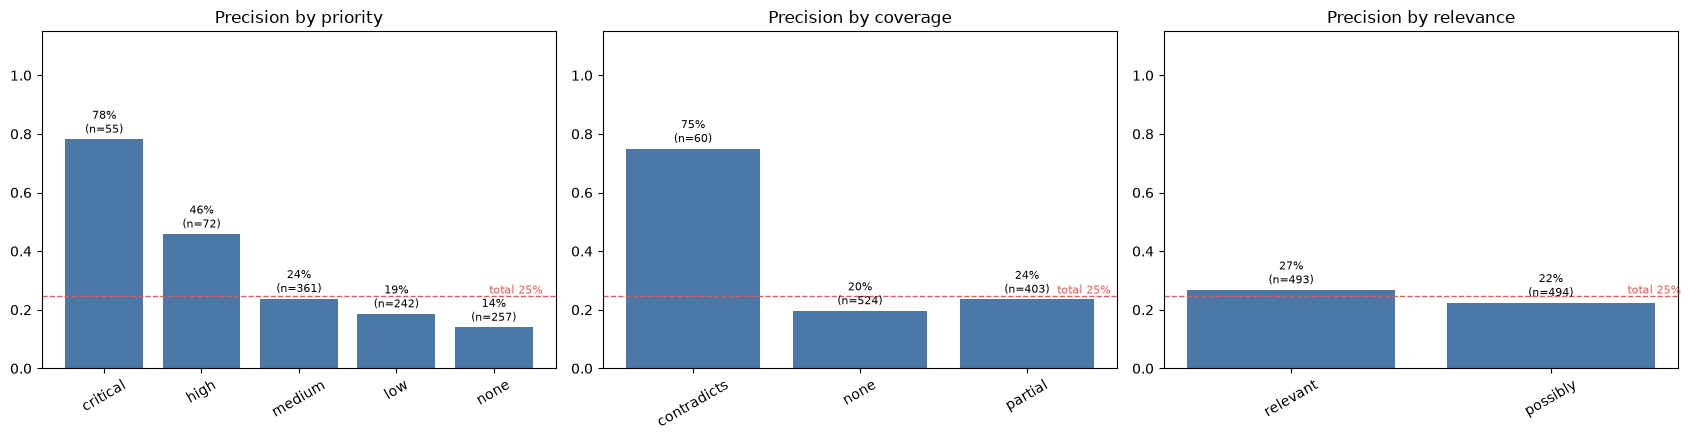

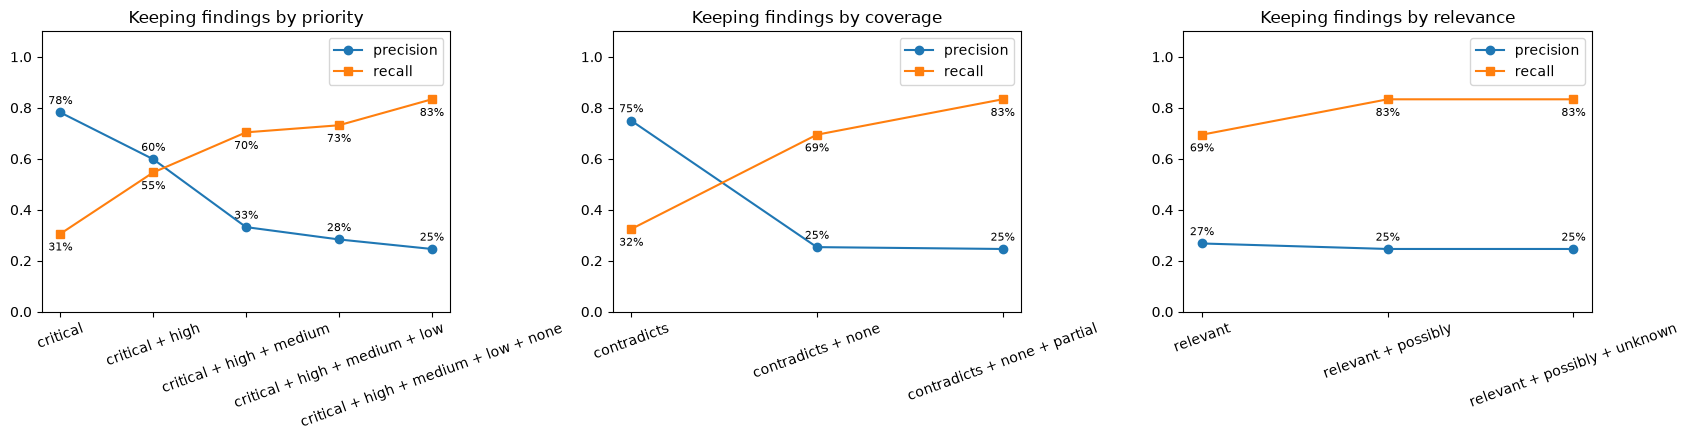

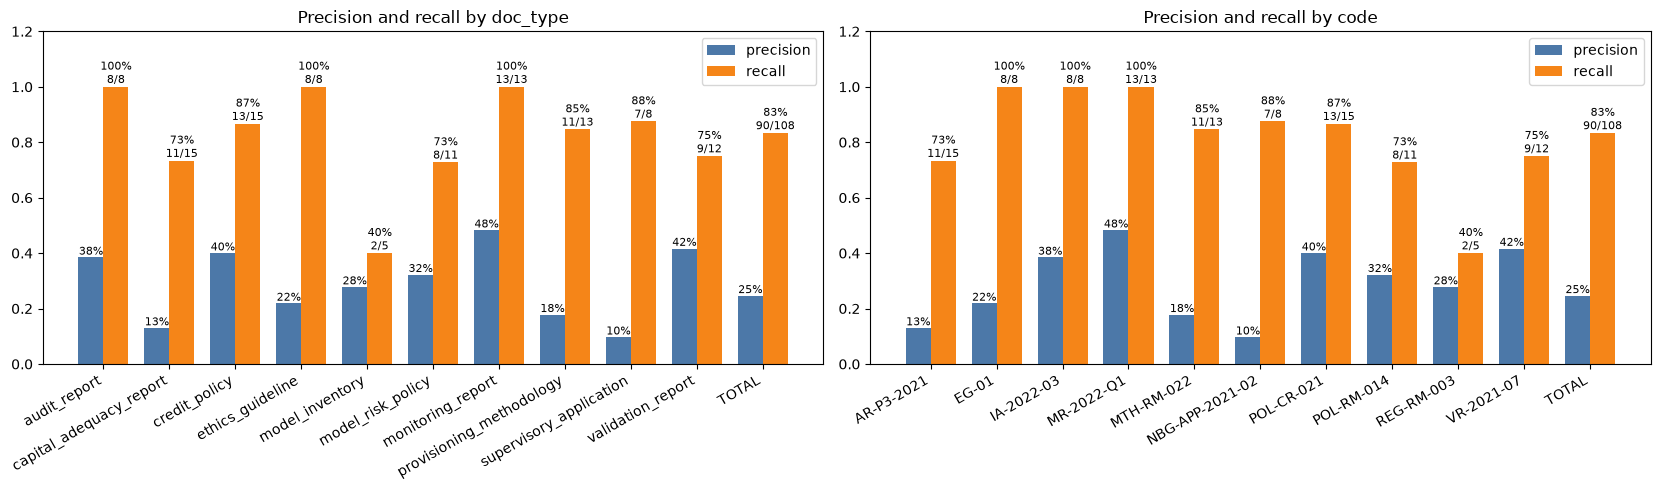

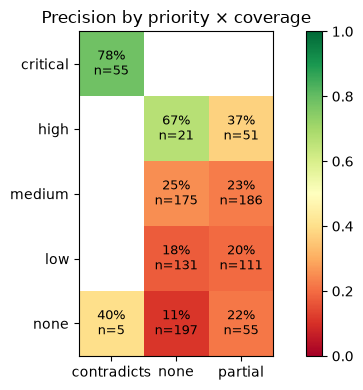

In [38]:
# --- charts -------------------------------------------------------------------------------------------------
def bars(ax, df, title, val="precision", n="findings"):
    d = df.drop(index="TOTAL", errors="ignore")
    b = ax.bar(d.index.astype(str), d[val].fillna(0), color="#4C78A8")
    ax.bar_label(b, labels=[f"{v:.0%}\n(n={int(k)})" if pd.notna(v) else "—" for v, k in zip(d[val], d[n])],
                 fontsize=8, padding=2)
    tot = df.loc["TOTAL", val] if "TOTAL" in df.index else None
    if tot is not None and pd.notna(tot):
        ax.axhline(tot, ls="--", color="#E45756", lw=1)
        ax.text(len(d) - 0.5, tot, f" total {tot:.0%}", color="#E45756", va="bottom", ha="right", fontsize=8)
    ax.set_ylim(0, 1.15); ax.set_title(title); ax.tick_params(axis="x", rotation=30)

# 1) precision per priority / coverage / relevance level
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ("priority", "coverage", "relevance")):
    bars(ax, per_level(col), f"Precision by {col}")
plt.tight_layout(); plt.show()

# 2) the precision / recall trade-off when keeping only the top levels
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ("priority", "coverage", "relevance")):
    c = cumulative(col)
    ax.plot(c["kept"], c["precision"], marker="o", label="precision")
    ax.plot(c["kept"], c["recall"], marker="s", label="recall")
    for x, p, r in zip(c["kept"], c["precision"], c["recall"]):
        ax.annotate(f"{p:.0%}", (x, p), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)
        ax.annotate(f"{r:.0%}", (x, r), textcoords="offset points", xytext=(0, -12), ha="center", fontsize=8)
    ax.set_ylim(0, 1.1); ax.set_title(f"Keeping findings by {col}"); ax.legend(); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

# 3) precision and recall per document type and per document
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for ax, col in zip(axes, ("doc_type", "code")):
    d = per_group(col)
    x = range(len(d))
    w = 0.38
    b1 = ax.bar([i - w / 2 for i in x], d["precision"].fillna(0), w, label="precision", color="#4C78A8")
    b2 = ax.bar([i + w / 2 for i in x], d["recall"].fillna(0), w, label="recall", color="#F58518")
    ax.bar_label(b1, labels=[f"{v:.0%}" if pd.notna(v) else "—" for v in d["precision"]], fontsize=8)
    ax.bar_label(b2, labels=[f"{v:.0%}\n{int(f)}/{int(g)}" if pd.notna(v) else "—"
                             for v, f, g in zip(d["recall"], d["found"], d["gold_gaps"])], fontsize=8)
    ax.set_xticks(list(x)); ax.set_xticklabels(d.index.astype(str), rotation=30, ha="right")
    ax.set_ylim(0, 1.2); ax.set_title(f"Precision and recall by {col}"); ax.legend()
plt.tight_layout(); plt.show()

# 4) heat map: precision by priority × coverage (number of findings in each cell)
pv_ = F.pivot_table(index="priority", columns="coverage", values="tp", aggfunc=["mean", "size"])
prec, cnt = pv_["mean"], pv_["size"]
prec = prec.reindex([l for l in LEVELS["priority"] if l in prec.index])
cnt = cnt.reindex(prec.index)
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(prec.values.astype(float), cmap="RdYlGn", vmin=0, vmax=1)
ax.set_xticks(range(len(prec.columns))); ax.set_xticklabels(prec.columns)
ax.set_yticks(range(len(prec.index))); ax.set_yticklabels(prec.index)
for i in range(prec.shape[0]):
    for j in range(prec.shape[1]):
        v, n = prec.values[i, j], cnt.values[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.0%}\nn={int(n)}", ha="center", va="center", fontsize=9)
ax.set_title("Precision by priority × coverage"); fig.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout(); plt.show()

In [24]:
# --- wrong "contradicts" findings: what the system said vs. what the gold key says ----------------------------
from kg.eval.matching import article_overlap
import numpy as np

wrong = F[(F["coverage"] == "contradicts") & (~F["tp"])].copy()
print(f"contradicts findings: {(F['coverage'] == 'contradicts').sum()} · wrong (no gold gap matched): {len(wrong)}")

cov = q("SELECT doc_version_id, obligation_id, rationale, missing, cause FROM coverage")
cov_by = {(r.doc_version_id, r.obligation_id): r for r in cov.itertuples()}
edges_c = q("SELECT src, dst, props FROM edges WHERE type='COVERED_BY'")
edges_c["p"] = edges_c["props"].map(json.loads)

def clause_text(cid: str) -> tuple[str, str]:
    n = store.get_node(cid)
    p = (n or {}).get("props", {})
    return p.get("section_no") or "", (p.get("text") or "")[:400]

rows = []
for f in wrong.itertuples():
    ob = store.get_node(f.obligation_id)["props"]
    c = cov_by.get((f.version_id, f.obligation_id))
    # the clauses the judge said contradict (role contradicts, or partial when the verdict was contradicts)
    es = edges_c[(edges_c["src"] == f.obligation_id) &
                 edges_c["p"].map(lambda p: p.get("doc_version") == f.version_id)]
    cl = []
    for e in es.itertuples():
        sec, txt = clause_text(e.dst)
        cl.append(f"§{sec} [{e.p.get('role')}] {txt}" + (f"\n   why: {e.p.get('why')}" if e.p.get("why") else ""))
    # gold items of this document on the same regulation article (any class): near misses / compliant decoys
    near = [f"{g['id']} ({g['class']}, §{g['document_section']}, {g['regulation_article']}): {g['requirement'][:160]}"
            for g in gold_by_file[f.gold_file] if article_overlap(ob.get("source_path"), g["paths"])]
    rows.append({
        "document": f.code, "priority": f.priority, "relevance": f.relevance, "cause": f.cause,
        "source_path": ob.get("source_path"), "obligation": ob.get("statement"),
        "judge_rationale": getattr(c, "rationale", None), "missing": getattr(c, "missing", None),
        "contradicting_clauses": "\n".join(cl) or "—",
        "flags_compliant_decoy (C)": ", ".join(sorted(f.gold_C)) or "",
        "gold_items_on_same_article": "\n".join(near) or "—",
    })

W = pd.DataFrame(rows).sort_values(["document", "priority", "source_path"])
# a quick reading aid: which kind of error is it?
W["kind"] = np.select(
    [W["flags_compliant_decoy (C)"] != "", W["gold_items_on_same_article"] != "—"],
    ["false alarm on compliant text (C)", "gold item on the same article: check section / paragraph"],
    default="no gold item on this article: false alarm or a gap the key does not list")
display(W["kind"].value_counts().rename("count").to_frame())
display(W.groupby(["document", "kind"]).size().unstack(fill_value=0))

pd.set_option("display.max_colwidth", 400)
display(W.style.set_properties(**{"white-space": "pre-wrap", "text-align": "left"}))

W.to_csv(ROOT / "evaluation" / "wrong_contradicts.csv", index=False, encoding="utf-8-sig")
print("saved → evaluation/wrong_contradicts.csv")

contradicts findings: 31 · wrong (no gold gap matched): 5


,count
kind,
no gold item on this article: false alarm or a gap the key does not list,5


kind,no gold item on this article: false alarm or a gap the key does not list
document,
IA-2022-03,2
MTH-RM-022,2
NBG-APP-2021-02,1


,document,priority,relevance,cause,source_path,obligation,judge_rationale,missing,contradicting_clauses,flags_compliant_decoy (C),gold_items_on_same_article,kind
0,IA-2022-03,medium,possibly,B,art6/p6,დაცვის მეორე ხაზი შიდა ვალიდაციის პროცესში უნდა იყენებდეს პროპორციულობის პრინციპს მოდელის მნიშვნელობიდან და სირთულედან გამომდინარე.,"აუდიტის დაკვირვება (F6) მიუთითებს, რომ ვალიდაციის ინტენსივობა ყველა მოდელისთვის ერთნაირია, რაც ეწინააღმდეგება პროპორციულობის პრინციპს, რომელიც მოდელის სირთულეზეა დაფუძნებული.",nan,"§ [contradicts] № | დაკვირვება | რისკის დონე | რეკომენდაცია №: F1 | დაკვირვება: M-007 მოდელის (მესამე მხარე) შიდა ვალიდაცია არ ჩატარებულა; ბანკი დაეყრდნო მომწოდებლის ვალიდაციის ანგარიშს. ამასთან, მომწოდებლის ანგარიში არ შეიცავს მოდელის შეზღუდვებისა და დაშვებების აღწერას. | რისკის დონე: მაღალი | რეკომენდაცია: ჩატარდეს M-007-ის შიდა ვალიდაცია 30.06.2022-მდე. №: F2 | დაკვირვება: მოდელების რეესტრი არ მოიცავს ორ Excel why: აუდიტი ამბობს, რომ კლასიფიკაციის არარსებობა შეესაბამება დებულებას, რაც ეწინააღმდეგება პროპორციულობის პრინციპის გამოყენების მოთხოვნას.",,—,no gold item on this article: false alarm or a gap the key does not list
1,IA-2022-03,medium,possibly,B,art9/p4,"მესამე მხარემ მოდელის გამომყენებელ სუბიექტს უნდა წარუდგინოს მოდელის განვითარების და შიდა ვალიდაციის ეტაპების დეტალური აღწერა, შესაბამისი ტესტების შედეგები, მოდელის შეზღუდვები, დაშვებები და ის გარემოებები, სადაც პროდუქტის გამოყენება პრობლემებს შექმნის.","აუდიტის დასკვნა F1 პირდაპირ ეწინააღმდეგება მოთხოვნას, რადგან მესამე მხარის მიერ მოწოდებული დოკუმენტაცია არ შეიცავს მოდელის შეზღუდვებისა და დაშვებების აღწერას.",nan,"§ [contradicts] № | დაკვირვება | რისკის დონე | რეკომენდაცია №: F1 | დაკვირვება: M-007 მოდელის (მესამე მხარე) შიდა ვალიდაცია არ ჩატარებულა; ბანკი დაეყრდნო მომწოდებლის ვალიდაციის ანგარიშს. ამასთან, მომწოდებლის ანგარიში არ შეიცავს მოდელის შეზღუდვებისა და დაშვებების აღწერას. | რისკის დონე: მაღალი | რეკომენდაცია: ჩატარდეს M-007-ის შიდა ვალიდაცია 30.06.2022-მდე. №: F2 | დაკვირვება: მოდელების რეესტრი არ მოიცავს ორ Excel why: აუდიტი პირდაპირ აცხადებს, რომ მესამე მხარის მიერ მოწოდებული დოკუმენტაცია არ შეიცავს სავალდებულო ელემენტებს (შეზღუდვები და დაშვებები).",,—,no gold item on this article: false alarm or a gap the key does not list
3,MTH-RM-022,none,relevant,B,art12/p5,"ჰომოგენური ჯგუფის საკრედიტო რისკზე გავლენის მქონე ფაქტორების განსაზღვრისას გათვალისწინებული უნდა იყოს საპროგნოზო ინფორმაციის, მათ შორის, მაკროეკონომიკური ფაქტორების ეფექტი.","დოკუმენტის პუნქტი 5.2 ამბობს, რომ განსხვავებული ეკონომიკური სცენარები არ განიხილება, რაც ეწინააღმდეგება ვალდებულებას, რომ საკრედიტო რისკზე გავლენის მქონე ფაქტორების განსაზღვრისას გათვალისწინებული უნდა იყოს მაკროეკონომიკური ფაქტორების ეფექტი.",nan,"§5.2 [contradicts] ინდივიდუალური შეფასებისას გამოიყენება მხოლოდ მსესხებლის წინა პერიოდის გამოცდილება და ფაქტობრივი ფინანსური მონაცემები; განსხვავებული ეკონომიკური სცენარები არ განიხილება. why: დოკუმენტი პირდაპირ კრძალავს განსხვავებული ეკონომიკური სცენარების გამოყენებას, მაშინ როცა ვალდებულება მოითხოვს საპროგნოზო და მაკროეკონომიკური ფაქტორების გათვალისწინებას.",,—,no gold item on this article: false alarm or a gap the key does not list
4,MTH-RM-022,none,relevant,B,art13/p2,"მოსალოდნელი საკრედიტო ზარალის შეფასებისას გამოყენებული მოდელი უნდა ითვალისწინებდეს ყველა შესაბამის შიდა თუ გარე ფაქტორს, რომელსაც გააჩნია კლიენტის გადახდისუნარიანობაზე გავლენის მოხდენის შესაძლებლობა.","დოკუმენტის 5.2 პუნქტი პირდაპირ ეწინააღმდეგება ვალდებულებას, რადგან აზღვიერებს განსხვავებული ეკონომიკური სცენარების გამოყენებას, რაც აუცილებელია ყველა გავლენის მქონე ფაქტორის გათვალისწინებისთვის.",nan,"§5.2 [contradicts] ინდივიდუალური შეფასებისას გამოიყენება მხოლოდ მსესხებლის წინა პერიოდის გამოცდილება და ფაქტობრივი ფინანსური მონაცემები; განსხვავებული ეკონომიკური სცენარები არ განიხილება. why: დოკუმენტი პირდაპირ კრძალავს განსხვავებული ეკონომიკური სცენარების გამოყენებას, რაც ეწინააღმდეგება ყველა შესაბამისი გარე ფაქტორის გათვალისწინების მოთხოვნას. §5.5 [partial] მაკროეკონომიკური სცენარებით განსაზღვრული წინასწარი ინფ

saved → evaluation/wrong_contradicts.csv


## "WRONG CONTRADICTIONS" non-model-risk

In [35]:
# --- contradictions not in the gold set: other directions (retail lending, ECL, capital adequacy) ------------
import sys, textwrap
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from kg.config import load_config
from kg.eval.compliance import load_gold
from kg.eval.matching import match, article_overlap

EXCLUDE_DIRECTIONS = {"model_risk"}           # already reviewed

def txt(v) -> str:
    """A text value, or "" for None / NaN."""
    return v.strip() if isinstance(v, str) else ""

cfg = load_config()
gold = load_gold(cfg)                          # gold_labels + gold_labels_extra (D12-D14 and the reviewed additions)
gold_files = {g["document_file"] for g in gold}

dirs = q("SELECT family_id, direction FROM document_directions")
dirs = dict(zip(dirs.family_id, dirs.direction))
ver_dir = {v: dirs.get(v.split(":", 1)[1].rsplit("@", 1)[0]) for v in q("SELECT id FROM document_versions")["id"]}

def gold_file_of(version_id: str) -> str | None:
    code = version_id.split("/")[-1].split("@")[0]
    return next((f for f in gold_files if code in f or (code == "NBG-APP-2021-02" and "M-002" in f)), None)

nodes = lambda t: {r.id: json.loads(r.props) for r in q("SELECT id, props FROM nodes WHERE type=?", (t,)).itertuples()}
OBL, CL, PV = nodes("Obligation"), nodes("Clause"), nodes("ProvisionVersion")
imposes = q("SELECT src, dst FROM edges WHERE type='IMPOSES'").groupby("dst")["src"].apply(list).to_dict()
cb = q("SELECT src, dst, props FROM edges WHERE type='COVERED_BY'")
cb["p"] = cb["props"].map(json.loads)
cb["ver"] = cb["p"].map(lambda p: p.get("doc_version"))
CB = {k: g for k, g in cb.groupby(["ver", "src"])}
tri = q("SELECT doc_version_id, obligation_id, relevance, reason FROM triage").set_index(["doc_version_id", "obligation_id"])
tsk = q("SELECT doc_version_id, obligation_id, priority FROM tasks").set_index(["doc_version_id", "obligation_id"])
prop = q("SELECT doc_version_id, obligation_id, kind, heading, proposed_text FROM proposals").set_index(
    ["doc_version_id", "obligation_id"])
# one row per (version, obligation): keep the last proposal if there are several
tri = tri[~tri.index.duplicated(keep="last")]
tsk = tsk[~tsk.index.duplicated(keep="last")]
prop = prop[~prop.index.duplicated(keep="last")]

cov = q("SELECT * FROM coverage WHERE verdict='contradicts' AND (invalid IS NULL OR invalid=0)")
cov = cov[cov["doc_version_id"].map(lambda v: ver_dir.get(v) not in EXCLUDE_DIRECTIONS)]

def regulation(oid: str) -> str:
    pvs = sorted(p for p in imposes.get(oid, []) if p in PV)
    if not pvs:
        return ""
    p = PV[pvs[-1]]
    return f"[{p.get('display') or p.get('path')}] {txt(p.get('text'))}"

rows = []
for c in cov.itertuples():
    v, oid = c.doc_version_id, c.obligation_id
    ob, gf = OBL.get(oid, {}), gold_file_of(v)
    e = CB.get((v, oid))
    cited = [] if e is None else [(CL.get(x.dst, {}), x.p) for x in e.itertuples()]
    on_doc = [g for g in gold if g["document_file"] == gf]
    cls = {g["id"]: g["class"] for g in on_doc}
    hits = set()
    for g in on_doc:                                     # the same matching as the precision / recall cells
        secs = [cl.get("section_no") for cl, _ in cited] or [None]
        for sec in secs:
            f = {"doc_file": gf, "section_no": sec, "clause_id": "x" if sec else None, "source_path": ob.get("source_path")}
            if match(f, g, g["paths"], g["tokens"]):
                hits.add(g["id"])
                break
    if any(cls[i] in "AB" for i in hits):
        continue                                          # confirmed by the gold set: not a "wrong" contradiction
    decoys = sorted(i for i in hits if cls[i] == "C")
    near = [g for g in on_doc if article_overlap(ob.get("source_path"), g["paths"])]
    t = tri.loc[(v, oid)] if (v, oid) in tri.index else None
    pr = prop.loc[(v, oid)] if (v, oid) in prop.index else None
    rows.append({
        "document": v.split("/")[-1].split("@")[0], "direction": ver_dir.get(v),
        "priority": tsk.loc[(v, oid), "priority"] if (v, oid) in tsk.index else None,
        "relevance": txt(t["relevance"]) if t is not None else "", "cause": txt(c.cause),
        "source_path": ob.get("source_path"), "obligation": txt(ob.get("statement")),
        "regulation_text": regulation(oid),
        "judge_rationale": txt(c.rationale), "missing": txt(c.missing),
        "contradicting_clauses": "\n".join(f"§{cl.get('section_no') or '—'} [{txt(p.get('role'))}] „{txt(p.get('quote'))}“ — "
                                           f"{txt(p.get('why'))}" for cl, p in cited),
        "clause_full_text": "\n".join(f"§{cl.get('section_no') or '—'} {txt(cl.get('text'))}" for cl, _ in cited),
        "flags_compliant_decoy (C)": ", ".join(decoys),
        "gold_items_on_same_article": "\n".join(f"{g['id']} ({g['class']}, §{txt(g.get('document_section'))}): "
                                                f"{txt(g.get('requirement'))}" for g in near),
        "kind": "decoy hit (C)" if decoys else ("other gold item on this article" if near else "no gold item on this article"),
        "proposal": "" if pr is None else f"{txt(pr['kind'])}: {txt(pr['heading'])} {txt(pr['proposed_text'])}".strip(),
        # to fill in during the review; confirmed rows can be copied into a gold additions file
        "review_correct": "", "what_the_document_says": "", "requirement": "", "verbatim_quote_ka": "", "expected_fix": "",
    })

W = pd.DataFrame(rows).sort_values(["direction", "document", "kind", "source_path"]) if rows else pd.DataFrame()
all_c = cov.assign(direction=cov["doc_version_id"].map(ver_dir)).groupby("direction").size()
print("contradictions per direction:", all_c.to_dict())
print("not confirmed by the gold set:", W.groupby("direction").size().to_dict() if len(W) else {})
if len(W):
    display(W.groupby(["direction", "document", "kind"]).size().rename("n").to_frame())
    display(W[["document", "priority", "relevance", "cause", "source_path", "obligation", "judge_rationale",
               "contradicting_clauses", "kind"]])
    out = ROOT / "evaluation" / "wrong_contradicts_other_directions.csv"
    W.to_csv(out, index=False, encoding="utf-8-sig")
    print(f"saved {len(W)} rows → {out.relative_to(ROOT)}")
    # readable print-out for the review
    for i, r in enumerate(W.itertuples(), 1):
        print(f"\n{'=' * 110}\n#{i}  {r.document} · {r.source_path} · {r.kind} · priority {r.priority} · {r.relevance}")
        for label, val in (("OBLIGATION", r.obligation), ("REGULATION", r.regulation_text),
                           ("WHY CONTRADICTS", r.judge_rationale), ("CITED CLAUSES", r.contradicting_clauses),
                           ("GOLD ON SAME ARTICLE", r.gold_items_on_same_article)):
            if val:
                print(f"--- {label}\n" + textwrap.fill(str(val), 108, replace_whitespace=False))

contradictions per direction: {'capital_adequacy': 5, 'expected_credit_loss': 22, 'retail_lending': 6}
not confirmed by the gold set: {'capital_adequacy': 4, 'expected_credit_loss': 14, 'retail_lending': 1}


,,,n
direction,document,kind,
capital_adequacy,AR-P3-2021,no gold item on this article,4
expected_credit_loss,MTH-RM-022,no gold item on this article,14
retail_lending,POL-CR-021,no gold item on this article,1


,document,priority,relevance,cause,source_path,obligation,judge_rationale,contradicting_clauses,kind
15,AR-P3-2021,NaN,relevant,pre_existing,art23/p4,კომერციულმა ბანკებმა მინიმუმ წელიწადში ერთხელ ეროვნული ბანკს უნდა წარუდგინონ შიდა კაპიტალის ადეკვატურობის შეფასების ...,ბანკის მიერ დადგენილი სიხშირე (სამ წელიწადში ერთხელ) არ აკმაყოფილებს რეგულატორის მოთხოვნას (მინიმუმ წელიწადში ერთხელ).,§5.2 [contradicts] „ICAAP-ის შედეგები ეროვნულ ბანკს წარედგინება სამ წელიწადში ერთხელ“ — ბანკი წარადგენს შედეგებს სამ...,no gold item on this article
16,AR-P3-2021,NaN,possibly,amendment,art30/p1/sლ,ინსტრუმენტის ხელშეკრულება უნდა მოიცავდეს რეკაპიტალიზაციის მიზნით ვალდებულებების ჩამოწერის ან კონვერტაციის პირობებს ე...,"ბანკის დოკუმენტში მითითებულია, რომ ინსტრუმენტი არ შეიცავს რეკაპიტალიზაციის მიზნით ჩამოწერის ან კონვერტაციის პირობებს...",§3.4 [contradicts] „ინსტრუმენტი არ შეიცავს რეკაპიტალიზაციის მიზნით ჩამოწერის ან კონვერტაციის სხვა პირობას“ — დოკუმენ...,no gold item on this article
17,AR-P3-2021,NaN,relevant,pre_existing,art40/p2,"რისკის პოზიცია საცხოვრებელი უძრავი ქონების დამქირავებლის/ლიზინგის მიმღების (მაცხოვრებლის) მიმართ, უნდა შეიწონოს 35%-...","დოკუმენტში მითითებული საცალო სესხების ზოგადი წონა (75%) ეწინააღმდეგება რეგულაციის მოთხოვნას, რომლის მიხედვითაც კონკრ...","§4.1 [contradicts] „ყველა საცალო სესხი, მათ შორის სახელმწიფო პენსიისა და სოციალური დახმარების ჩარიცხვით დაფარვადი სე...",no gold item on this article
18,AR-P3-2021,NaN,relevant,pre_existing,art45/p3,"გადავადებული საგადასახადო აქტივები, რომლებიც არ გამოიქვითა ძირითადი პირველადი კაპიტალიდან, უნდა შეიწონოს 250%-ით.","დოკუმენტში მითითებულია, რომ გადავადებული საგადასახადო აქტივები შედის CET1-ში, რაც ეწინააღმდეგება ვალდებულებას, რომ ა...","§3.3 [contradicts] „გადავადებული საგადასახადო აქტივები (4 200 ათასი ლარი), რომელთა რეალიზება მომავალი მოგებიანობაზეა...",no gold item on this article
0,MTH-RM-022,critical,relevant,pre_existing,art13/p2,მოსალოდნელი საკრედიტო ზარალის შეფასებისას გამოყენებული მოდელი უნდა ითვალისწინებდეს ყველა შესაბამის შიდა თუ გარე ფაქტ...,"დოკუმენტის 5.2 პუნქტი პირდაპირ გამორიცხავს ეკონომიკური სცენარების გამოყენებას ინდივიდუალური შეფასებისას, რაც ეწინააღ...","§5.2 [contradicts] „განსხვავებული ეკონომიკური სცენარები არ განიხილება“ — დოკუმენტი აცხადებს, რომ ინდივიდუალური შეფას...",no gold item on this article
1,MTH-RM-022,critical,relevant,pre_existing,art23/p1/sა,"კომერციულმა ბანკმა უნდა უზრუნველყოს კონტამინაციის პრინციპის დაცვა საცალო და მიკრო პორტფელებისთვის, როდესაც მსესხებლი...","ბანკის მეთოდოლოგია პირდაპირ ეწინააღმდეგება კონტამინაციის პრინციპს, რადგან ადგენს, რომ ერთი ინსტრუმენტის გაუფასურება ...","§2.6 [contradicts] „თუ მსესხებლის ფინანსური ინსტრუმენტი გაუფასურებულია, მე-3 დონეს მიეკუთვნება მხოლოდ ეს ინსტრუმენტი...",no gold item on this article
2,MTH-RM-022,critical,relevant,pre_existing,art25/p3,"შეფასებული უზრუნველყოფის საშუალების რეალური ღირებულების, რეალიზაციის პერიოდისა და რეალიზაციასთან დაკავშირებულ დანახა...","დოკუმენტი ეწინააღმდეგება მოთხოვნას, რადგან ინდივიდუალური შეფასებისას ეკონომიკური სცენარების გამოყენება აკრძალულია, ა...",§5.2 [contradicts] „განსხვავებული ეკონომიკური სცენარები არ განიხილება“ — დოკუმენტი პირდაპირ კრძალავს ეკონომიკური სცე...,no gold item on this article
3,MTH-RM-022,critical,relevant,pre_existing,art3/p2/sბ,კომერციული ბანკის მიერ საკრედიტო რისკის კატეგორიის დადგენისას გამოყენებული ინფორმაცია უნდა შეიცავდეს მსესხებლისთვის ...,"დოკუმენტში პირდაპირ არის მითითებული, რომ საკრედიტო რისკის შეფასებისას მაკროეკონომიკური გარემო არ განიხილება, რაც ეწი...","§2.3 [contradicts] „მაკროეკონომიკური გარემოს გაუარესება ამ შეფასებისას არ განიხილება“ — ბანკი აცხადებს, რომ საკრედიტ...",no gold item on this article
4,MTH-RM-022,critical,relevant,pre_existing,art4/p1/sბ,"ფინანსური ინსტრუმენტი არ უნდა იყოს 30 დღეზე მეტი პერიოდით ვადაგადაცილებული, რათა კლასიფიცირდეს პირველი დონის საკრედი...","ბანკის მეთოდოლოგიით მე-2 დონეზე გადასვლა ხდება 60 დღეზე მეტი ვადაგადაცილებისას, რაც ნიშნავს, რომ 30-დან 60 დღემდე ვა...","§2.2 [contradicts] „მე-2 დონეს ასევე მიეკუთვნება 

saved 19 rows → evaluation/wrong_contradicts_other_directions.csv

#1  AR-P3-2021 · art23/p4 · no gold item on this article · priority nan · relevant
--- OBLIGATION
კომერციულმა ბანკებმა მინიმუმ წელიწადში ერთხელ ეროვნული ბანკს უნდა წარუდგინონ შიდა კაპიტალის ადეკვატურობის
შეფასების პროცესის შედეგები.
--- REGULATION
[მუხლი 23, პუნქტი 4] კომერციულმა ბანკებმა მინიმუმ წელიწადში ერთხელ ეროვნული ბანკს უნდა წარუდგინონ შიდა
კაპიტალის ადეკვატურობის შეფასების პროცესის შედეგები.
--- WHY CONTRADICTS
ბანკის მიერ დადგენილი სიხშირე (სამ წელიწადში ერთხელ) არ აკმაყოფილებს რეგულატორის მოთხოვნას (მინიმუმ
წელიწადში ერთხელ).
--- CITED CLAUSES
§5.2 [contradicts] „ICAAP-ის შედეგები ეროვნულ ბანკს წარედგინება სამ წელიწადში ერთხელ“ — ბანკი წარადგენს
შედეგებს სამ წელიწადში ერთხელ, რაც ნაკლებია მოთხოვნილ მინიმუმ წელიწადში ერთხელზე.

#2  AR-P3-2021 · art30/p1/sლ · no gold item on this article · priority nan · possibly
--- OBLIGATION
ინსტრუმენტის ხელშეკრულება უნდა მოიცავდეს რეკაპიტალიზაციის მიზნით ვალდებულებების ჩამო

In [21]:
# --- performance evaluation: findings vs. gold labels ------------------------------------------------------
import sys, json
import numpy as np
from collections import defaultdict
sys.path.insert(0, str(ROOT / "src"))
from kg.config import load_config
from kg.store.sqlite_nx import SQLiteStore
from kg.eval.compliance import load_gold
from kg.eval.matching import match
from kg.eval.v2suites import finding_views_v2

INCLUDE_REVIEWED = True          # True = answer keys + reviewed additions; False = the original answer keys only

cfg = load_config(str(ROOT / "configs" / "kg.yaml"))
store = SQLiteStore(cfg.path("db"))
GOLD_ALL = load_gold(cfg)                              # model risk key + D12-D14 key + reviewed additions
views = finding_views_v2(store)                        # one view per (finding, clause it points at)

# document versions: family, file, type (confirmed profile), direction; a family's versions share its gold file
vers = q("""SELECT dv.id AS version_id, dv.family_id, d.code, dv.status, p.doc_type, dd.direction
            FROM document_versions dv JOIN documents d ON d.id = dv.family_id
            LEFT JOIN doc_profiles p ON p.doc_version_id = dv.id
            LEFT JOIN document_directions dd ON dd.family_id = dv.family_id""")
vers["file"] = vers["version_id"].map(lambda v: json.loads(q("SELECT props FROM nodes WHERE id=?", (v,))
                                                            ["props"].iloc[0]).get("file", "").split("/")[-1])
gold_files = {g["document_file"] for g in GOLD_ALL}
fam_file = {r.family_id: r.file for r in vers.itertuples() if r.file in gold_files}
vers["gold_file"] = vers["family_id"].map(fam_file)
checked = set(q("SELECT DISTINCT doc_version_id FROM coverage")["doc_version_id"])
vers = vers[vers["version_id"].isin(checked)]
info = vers.set_index("version_id")
doc_meta = vers.dropna(subset=["gold_file"]).drop_duplicates("gold_file").set_index("gold_file")


def build_eval(gold: list[dict]):
    """-> F (one row per finding = version x obligation), G (gold items of checked documents), GAB (gaps only)."""
    gold_by_file = defaultdict(list)
    for g in gold:
        gold_by_file[g["document_file"]].append(g)
    fnd = {}
    for v in views:
        if v["version_id"] not in info.index or not isinstance(info.loc[v["version_id"], "gold_file"], str):
            continue
        gf = info.loc[v["version_id"], "gold_file"]
        key = (v["version_id"], v["obligation_id"])
        f = fnd.setdefault(key, {"version_id": v["version_id"], "obligation_id": v["obligation_id"], "gold_file": gf,
                                 "code": info.loc[v["version_id"], "code"],
                                 "doc_type": info.loc[v["version_id"], "doc_type"] or "unknown",
                                 "direction": info.loc[v["version_id"], "direction"] or "other",
                                 "priority": v["priority"], "coverage": v["action_type"],
                                 "relevance": v["issue_chance"], "cause": v["gap_class"],
                                 "gold_AB": set(), "gold_C": set()})
        for g in gold_by_file[gf]:
            if match({**v, "doc_file": gf}, g, g["paths"], g["tokens"]):
                (f["gold_AB"] if g["class"] in "AB" else f["gold_C"]).add(g["id"])
    F = pd.DataFrame(fnd.values())
    F["tp"] = F["gold_AB"].map(bool)
    G = pd.DataFrame([{k: g.get(k) for k in ("id", "class", "document", "document_file", "document_section",
                                              "regulation_article", "source")}
                      for g in gold if g["document_file"] in set(doc_meta.index)])
    G["reviewed"] = G["source"].notna() & (G["source"] != "")
    G["code"] = G["document_file"].map(doc_meta["code"])
    G["doc_type"] = G["document_file"].map(doc_meta["doc_type"]).fillna("unknown")
    G["direction"] = G["document_file"].map(doc_meta["direction"]).fillna("other")
    found_AB = set().union(*F["gold_AB"]) if len(F) else set()
    flagged_C = set().union(*F["gold_C"]) if len(F) else set()
    G["found"] = G.apply(lambda r: (r["id"] in found_AB) if r["class"] in "AB" else (r["id"] in flagged_C), axis=1)
    return F, G, G[G["class"].isin(["A", "B"])]


GOLD_ORIG = [g for g in GOLD_ALL if not g.get("source")]
RES = {"original keys": build_eval(GOLD_ORIG), "with reviewed additions": build_eval(GOLD_ALL)}
F, G, GAB = RES["with reviewed additions" if INCLUDE_REVIEWED else "original keys"]

print(f"checked documents with a gold key: {sorted(G['code'].unique())}")
for name, (f_, g_, gab_) in RES.items():
    print(f"{name:>25}: findings {len(f_):,} · correct {int(f_['tp'].sum()):,} "
          f"(precision {f_['tp'].mean():.1%}) · gold gaps {len(gab_)} · found {int(gab_['found'].sum())} "
          f"(recall {gab_['found'].mean():.1%})")
print(f"\nshowing below: {'with reviewed additions' if INCLUDE_REVIEWED else 'original keys'}")

checked documents with a gold key: ['EG-01', 'IA-2022-03', 'MR-2022-Q1', 'MTH-RM-022', 'NBG-APP-2021-02', 'POL-CR-021', 'POL-RM-014', 'REG-RM-003', 'VR-2021-07']
            original keys: findings 733 · correct 176 (precision 24.0%) · gold gaps 85 · found 70 (recall 82.4%)
  with reviewed additions: findings 733 · correct 194 (precision 26.5%) · gold gaps 93 · found 78 (recall 83.9%)

showing below: with reviewed additions


In [22]:
# --- tables -------------------------------------------------------------------------------------------------
LEVELS = {"priority": ["critical", "high", "medium", "low", "none"],
          "coverage": ["contradicts", "none", "partial"],
          "relevance": ["relevant", "possibly", "unknown"]}

def per_level(col: str, F=None, GAB=None) -> pd.DataFrame:
    """Precision of the findings of each level + the gold gaps they find (share of all gold A/B gaps)."""
    F = globals()["F"] if F is None else F
    GAB = globals()["GAB"] if GAB is None else GAB
    rows = []
    for lv, grp in F.groupby(col):
        found = set().union(*grp["gold_AB"]) if len(grp) else set()
        rows.append({col: lv, "findings": len(grp), "correct": int(grp["tp"].sum()),
                     "precision": grp["tp"].mean(), "gold_gaps_found": len(found),
                     "recall_share": len(found) / len(GAB) if len(GAB) else None})
    df = pd.DataFrame(rows).set_index(col)
    df = df.reindex([l for l in LEVELS.get(col, sorted(df.index)) if l in df.index])
    all_found = set().union(*F["gold_AB"]) if len(F) else set()
    tot = {"findings": len(F), "correct": int(F["tp"].sum()), "precision": F["tp"].mean(),
           "gold_gaps_found": len(all_found), "recall_share": len(all_found) / len(GAB) if len(GAB) else None}
    return pd.concat([df, pd.DataFrame([tot], index=["TOTAL"])])

def cumulative(col: str) -> pd.DataFrame:
    """Keep the findings down to a level (critical; critical+high; ...): precision and recall of what is kept."""
    rows, kept = [], []
    for lv in LEVELS[col]:
        kept.append(lv)
        grp = F[F[col].isin(kept)]
        if not len(grp):
            continue
        found = set().union(*grp["gold_AB"])
        rows.append({"kept": " + ".join(kept), "findings": len(grp), "precision": grp["tp"].mean(),
                     "recall": len(found) / len(GAB) if len(GAB) else None})
    return pd.DataFrame(rows)

def per_group(col: str) -> pd.DataFrame:
    """Proper precision AND recall per document type / document / direction (both sides have the attribute)."""
    rows = []
    for lv in sorted(set(F[col].dropna()) | set(G[col].dropna())):
        f, g = F[F[col] == lv], GAB[GAB[col] == lv]
        c = G[(G[col] == lv) & (G["class"] == "C")]
        rows.append({col: lv, "findings": len(f), "correct": int(f["tp"].sum()),
                     "precision": f["tp"].mean() if len(f) else None,
                     "gold_gaps": len(g), "found": int(g["found"].sum()),
                     "recall": g["found"].mean() if len(g) else None,
                     "C_items": len(c), "C_false_alarms": int(c["found"].sum())})
    df = pd.DataFrame(rows).set_index(col)
    tot = {"findings": len(F), "correct": int(F["tp"].sum()), "precision": F["tp"].mean(), "gold_gaps": len(GAB),
           "found": int(GAB["found"].sum()), "recall": GAB["found"].mean(),
           "C_items": int((G["class"] == "C").sum()), "C_false_alarms": int(G[G["class"] == "C"]["found"].sum())}
    return pd.concat([df, pd.DataFrame([tot], index=["TOTAL"])])

fmt = {"precision": "{:.1%}", "recall": "{:.1%}", "recall_share": "{:.1%}"}
for col in ("priority", "coverage", "relevance"):
    print(f"\n=== by {col}: precision per level, and the share of gold gaps each level finds")
    display(per_level(col).style.format(fmt, na_rep="—"))
    print(f"cumulative by {col}:")
    display(cumulative(col).style.format(fmt, na_rep="—"))
for col in ("doc_type", "code", "direction"):
    print(f"\n=== by {col}: precision and recall")
    display(per_group(col).style.format(fmt, na_rep="—"))
print("\n=== recall by gold class (A = caused by an amendment, B = pre-existing):")
display(GAB.groupby("class")["found"].agg(["size", "sum", "mean"]).rename(
    columns={"size": "gold_gaps", "sum": "found", "mean": "recall"}).style.format({"recall": "{:.1%}"}))


=== by priority: precision per level, and the share of gold gaps each level finds


,findings,correct,precision,gold_gaps_found,recall_share
critical,41,25,61.0%,22,23.7%
high,135,33,24.4%,32,34.4%
medium,393,97,24.7%,55,59.1%
low,161,36,22.4%,20,21.5%
none,3,3,100.0%,1,1.1%
TOTAL,733,194,26.5%,78,83.9%


cumulative by priority:


,kept,findings,precision,recall
0,critical,41,61.0%,23.7%
1,critical + high,176,33.0%,48.4%
2,critical + high + medium,569,27.2%,80.6%
3,critical + high + medium + low,730,26.2%,83.9%
4,critical + high + medium + low + none,733,26.5%,83.9%



=== by coverage: precision per level, and the share of gold gaps each level finds


...

,findings,correct,precision,gold_gaps,found,recall,C_items,C_false_alarms
EG-01,64,14,21.9%,8,8,100.0%,1,0
IA-2022-03,104,40,38.5%,8,8,100.0%,1,1
MR-2022-Q1,58,28,48.3%,13,13,100.0%,1,1
MTH-RM-022,163,17,10.4%,13,10,76.9%,4,2
NBG-APP-2021-02,93,9,9.7%,8,7,87.5%,1,0
POL-CR-021,65,22,33.8%,15,13,86.7%,4,2
POL-RM-014,90,29,32.2%,11,8,72.7%,4,2
REG-RM-003,36,10,27.8%,5,2,40.0%,0,0
VR-2021-07,60,25,41.7%,12,9,75.0%,1,1
TOTAL,733,194,26.5%,93,78,83.9%,17,9



=== by direction: precision and recall


,findings,correct,precision,gold_gaps,found,recall,C_items,C_false_alarms
expected_credit_loss,163,17,10.4%,13,10,76.9%,4,2
model_risk,505,155,30.7%,65,55,84.6%,9,5
retail_lending,65,22,33.8%,15,13,86.7%,4,2
TOTAL,733,194,26.5%,93,78,83.9%,17,9



=== recall by gold class (A = caused by an amendment, B = pre-existing):


,gold_gaps,found,recall
class,,,
A,43,37,86.0%
B,50,41,82.0%


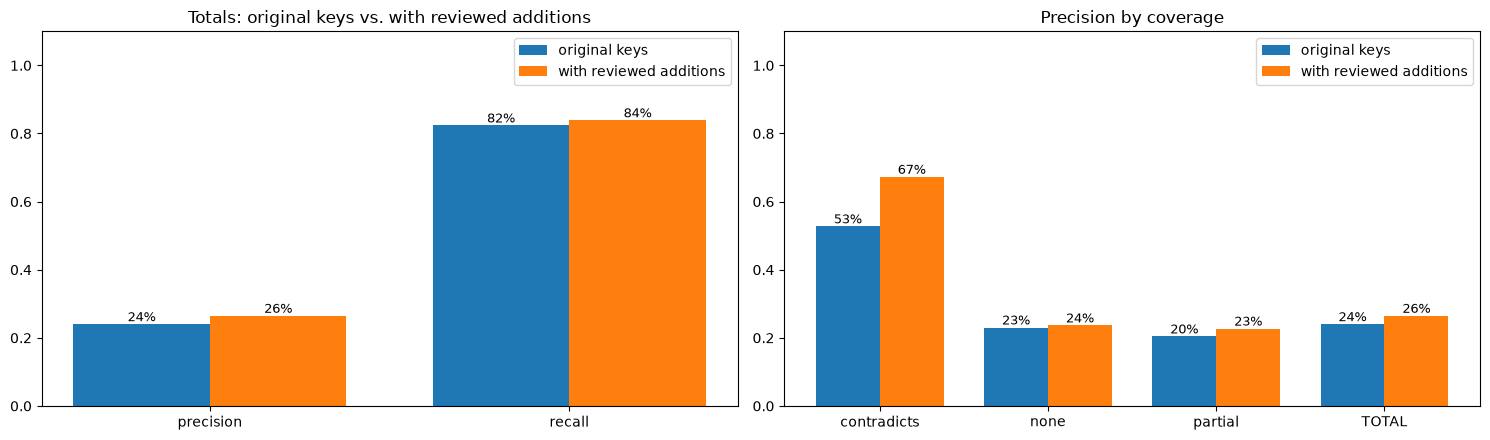

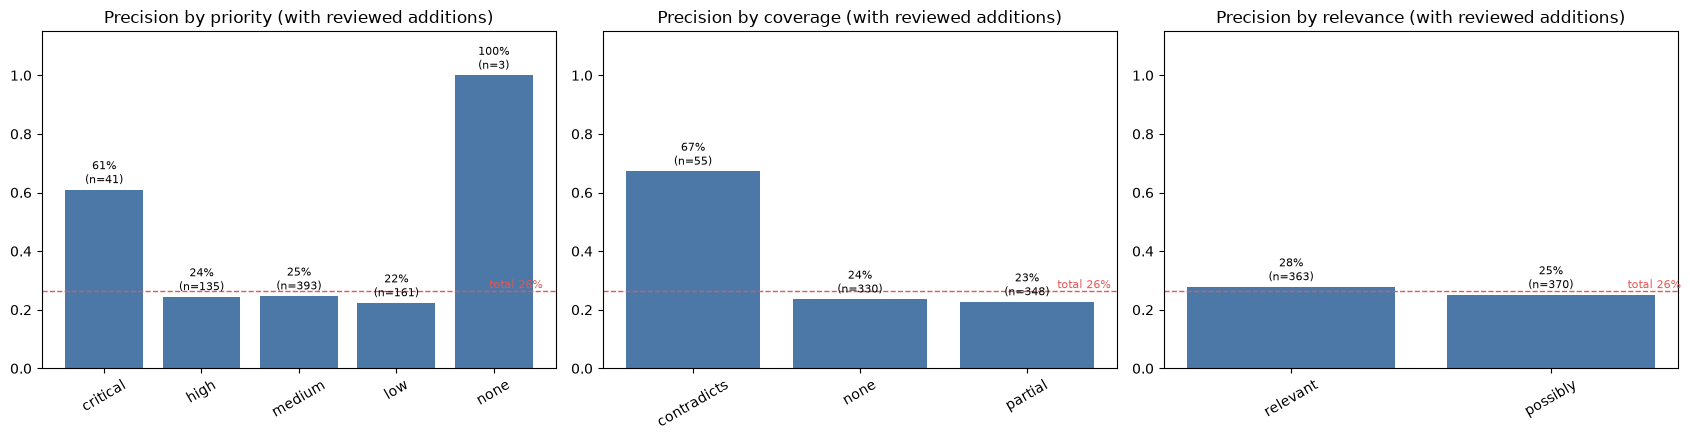

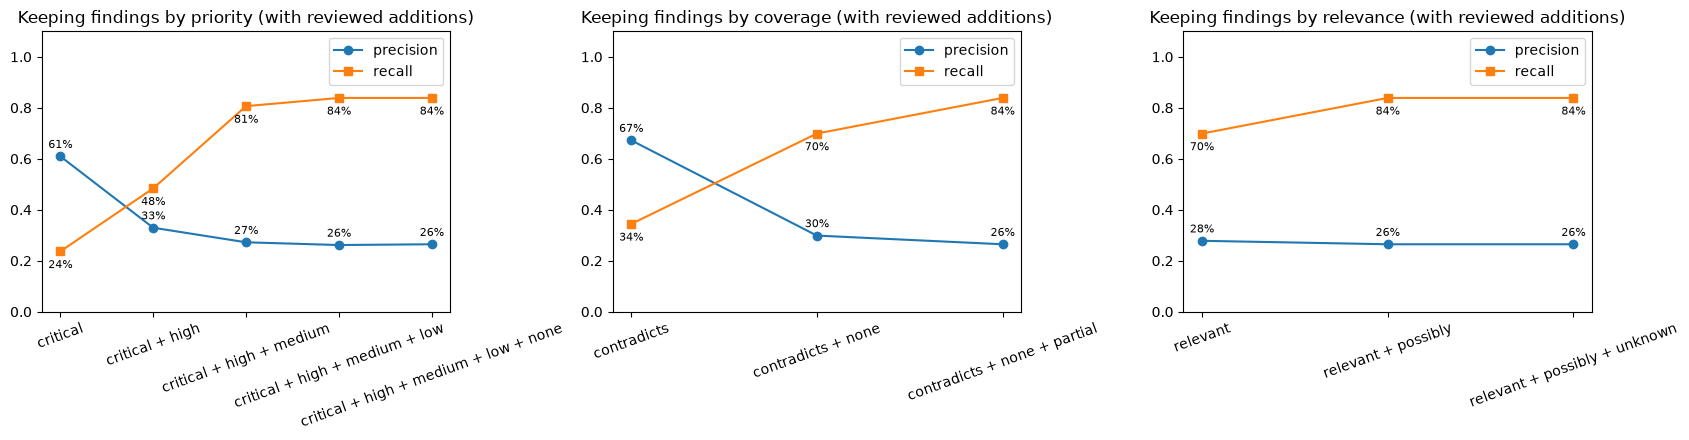

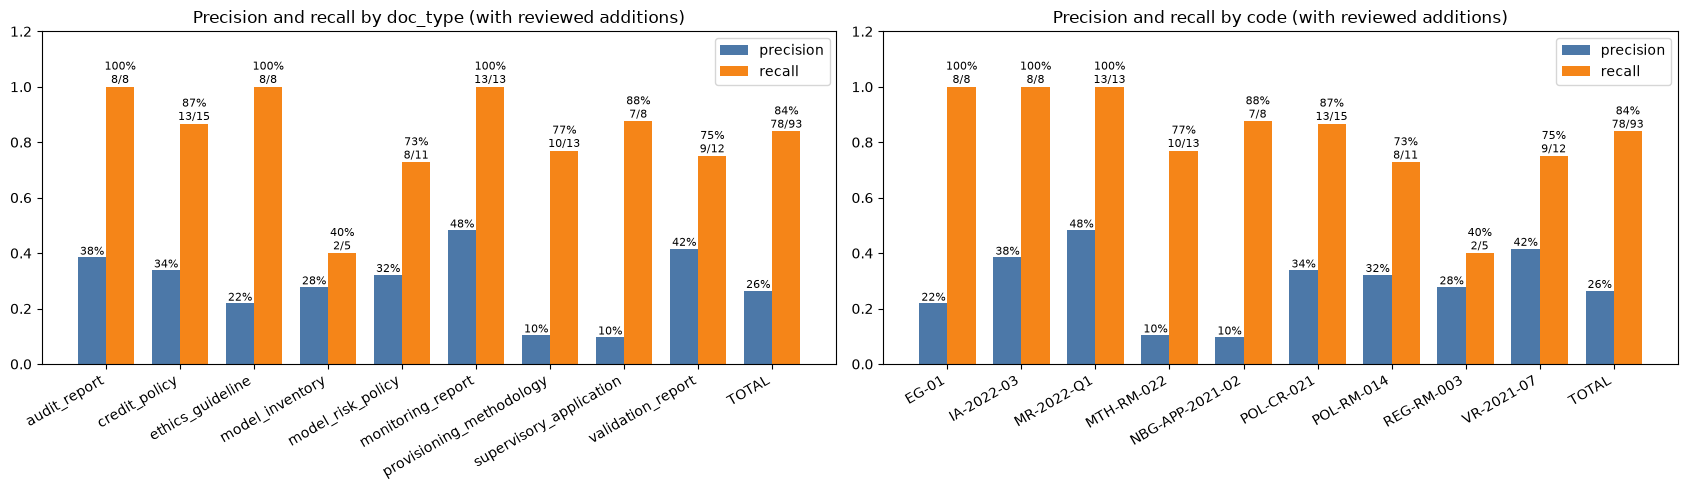

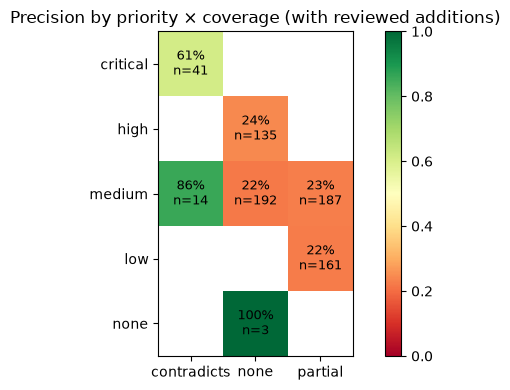

In [23]:
# --- charts -------------------------------------------------------------------------------------------------
def bars(ax, df, title, val="precision", n="findings"):
    d = df.drop(index="TOTAL", errors="ignore")
    b = ax.bar(d.index.astype(str), d[val].fillna(0), color="#4C78A8")
    ax.bar_label(b, labels=[f"{v:.0%}\n(n={int(k)})" if pd.notna(v) else "—" for v, k in zip(d[val], d[n])],
                 fontsize=8, padding=2)
    tot = df.loc["TOTAL", val] if "TOTAL" in df.index else None
    if tot is not None and pd.notna(tot):
        ax.axhline(tot, ls="--", color="#E45756", lw=1)
        ax.text(len(d) - 0.5, tot, f" total {tot:.0%}", color="#E45756", va="bottom", ha="right", fontsize=8)
    ax.set_ylim(0, 1.15); ax.set_title(title); ax.tick_params(axis="x", rotation=30)

label = "with reviewed additions" if INCLUDE_REVIEWED else "original keys"

# 0) original keys vs. with the reviewed additions: total precision / recall, and precision by coverage
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
names = list(RES)
tot = pd.DataFrame({n: {"precision": RES[n][0]["tp"].mean(), "recall": RES[n][2]["found"].mean()} for n in names}).T
xs = np.arange(len(tot.columns)); w = 0.38
for i, n in enumerate(names):
    b = axes[0].bar(xs + (i - 0.5) * w, tot.loc[n], w, label=n)
    axes[0].bar_label(b, labels=[f"{v:.0%}" for v in tot.loc[n]], fontsize=9)
axes[0].set_xticks(xs); axes[0].set_xticklabels(tot.columns); axes[0].set_ylim(0, 1.1)
axes[0].set_title("Totals: original keys vs. with reviewed additions"); axes[0].legend()
cov = pd.DataFrame({n: per_level("coverage", RES[n][0], RES[n][2])["precision"] for n in names})
xs = np.arange(len(cov.index))
for i, n in enumerate(names):
    b = axes[1].bar(xs + (i - 0.5) * w, cov[n].fillna(0), w, label=n)
    axes[1].bar_label(b, labels=[f"{v:.0%}" if pd.notna(v) else "—" for v in cov[n]], fontsize=9)
axes[1].set_xticks(xs); axes[1].set_xticklabels(cov.index); axes[1].set_ylim(0, 1.1)
axes[1].set_title("Precision by coverage"); axes[1].legend()
plt.tight_layout(); plt.show()

# 1) precision per priority / coverage / relevance level
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ("priority", "coverage", "relevance")):
    bars(ax, per_level(col), f"Precision by {col} ({label})")
plt.tight_layout(); plt.show()

# 2) the precision / recall trade-off when keeping only the top levels
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ("priority", "coverage", "relevance")):
    c = cumulative(col)
    ax.plot(c["kept"], c["precision"], marker="o", label="precision")
    ax.plot(c["kept"], c["recall"], marker="s", label="recall")
    for x, p, r in zip(c["kept"], c["precision"], c["recall"]):
        ax.annotate(f"{p:.0%}", (x, p), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)
        ax.annotate(f"{r:.0%}", (x, r), textcoords="offset points", xytext=(0, -12), ha="center", fontsize=8)
    ax.set_ylim(0, 1.1); ax.set_title(f"Keeping findings by {col} ({label})"); ax.legend()
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

# 3) precision and recall per document type and per document
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for ax, col in zip(axes, ("doc_type", "code")):
    d = per_group(col)
    x = np.arange(len(d))
    b1 = ax.bar(x - w / 2, d["precision"].fillna(0), w, label="precision", color="#4C78A8")
    b2 = ax.bar(x + w / 2, d["recall"].fillna(0), w, label="recall", color="#F58518")
    ax.bar_label(b1, labels=[f"{v:.0%}" if pd.notna(v) else "—" for v in d["precision"]], fontsize=8)
    ax.bar_label(b2, labels=[f"{v:.0%}\n{int(f)}/{int(g)}" if pd.notna(v) else "—"
                             for v, f, g in zip(d["recall"], d["found"], d["gold_gaps"])], fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(d.index.astype(str), rotation=30, ha="right")
    ax.set_ylim(0, 1.2); ax.set_title(f"Precision and recall by {col} ({label})"); ax.legend()
plt.tight_layout(); plt.show()

# 4) heat map: precision by priority × coverage (number of findings in each cell)
pv_ = F.pivot_table(index="priority", columns="coverage", values="tp", aggfunc=["mean", "size"])
prec, cnt = pv_["mean"], pv_["size"]
prec = prec.reindex([l for l in LEVELS["priority"] if l in prec.index])
cnt = cnt.reindex(prec.index)
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(prec.values.astype(float), cmap="RdYlGn", vmin=0, vmax=1)
ax.set_xticks(range(len(prec.columns))); ax.set_xticklabels(prec.columns)
ax.set_yticks(range(len(prec.index))); ax.set_yticklabels(prec.index)
for i in range(prec.shape[0]):
    for j in range(prec.shape[1]):
        v, n = prec.values[i, j], cnt.values[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.0%}\nn={int(n)}", ha="center", va="center", fontsize=9)
ax.set_title(f"Precision by priority × coverage ({label})"); fig.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout(); plt.show()

# MISSED GOLDENS

In [25]:
# --- 1. the gold gaps no finding matched --------------------------------------------------------------------
from kg.eval.matching import article_overlap, section_match

GOLD_BY_ID = {g["id"]: g for g in GOLD_ALL}
missed = GAB[~GAB["found"]].copy()
missed["requirement"] = missed["id"].map(lambda i: GOLD_BY_ID[i]["requirement"])
missed["what_the_document_says"] = missed["id"].map(lambda i: GOLD_BY_ID[i]["what_the_document_says"])
print(f"missed gold gaps: {len(missed)} of {len(GAB)} ({len(missed) / len(GAB):.0%})")
display(missed.groupby(["code", "class"]).size().unstack(fill_value=0).assign(
    total=lambda d: d.sum(axis=1)))
display(missed[["id", "code", "class", "document_section", "regulation_article", "requirement"]]
        .sort_values(["code", "id"]).reset_index(drop=True))

missed gold gaps: 15 of 93 (16%)


class,A,B,total
code,,,
MTH-RM-022,1,2,3
NBG-APP-2021-02,0,1,1
POL-CR-021,0,2,2
POL-RM-014,2,1,3
REG-RM-003,1,2,3
VR-2021-07,2,1,3


,id,code,class,document_section,regulation_article,requirement
0,D13-01,MTH-RM-022,A,1.3.,Art. 2 of the Order (repealed),The parallel-reporting requirement under 117/04 was repealed (Art. 2 of Order 192/04 repealed by 166/04); only the 192/04 ECL regime applies.
1,D13-06,MTH-RM-022,B,3.1.,Art. 8(2),"Stage 2 to Stage 1 requires a borrower financial analysis, full compliance with Stage 1 criteria and three consecutive demonstrative payments."
2,D13-08,MTH-RM-022,B,3.4.,Art. 7(11),Restructured status ends only if more than one year has passed since restructuring and the instrument was Stage 1 during the last year.
3,D11-01,NBG-APP-2021-02,B,Section 6,Art. 11 para 2,"The application must include the internal validation results. It also breaks the bank's own policy, 8.2."
4,D12-11,POL-CR-021,B,5.4.,Art. 6(6),"Income counts as received in the loan currency only under the conditions of Art. 6(6) (not exchange-rate sensitive, from the loan-currency country)."
5,D12-13,POL-CR-021,B,7.1.,Art. 7(10),Internal policies must be approved by the lender's statutory governing body.
6,D1-04,POL-RM-014,A,4.3.3,Art. 5 para 5,"The 2022 wording makes failure to confirm that the data quality standards and policies are met grounds for restricting or suspending the model, not only doubts about accuracy."
7,D1-09,POL-RM-014,A,7.2.1,Art. 9 para 1,"The 2023 amendment adds that outsourcing of model building, validation or audit must not hinder the supervisory process."
8,D1-11,POL-RM-014,B,3.5.1–3.5.2,Art. 6 para 4; Art. 4 para 1,Validation must be independent of development and use. The three lines must be independent.
9,D2-01,REG-RM-003,A,Section 1 note; 'next validation' column,Art. 6 para 4¹–4²,"Validation must be risk-based, which needs a model ranking or grouping by risk level."


In [26]:
# --- 2. diagnosis: at which step was each missed gap lost? --------------------------------------------------
obl = q("SELECT id, valid_from, valid_to, props FROM nodes WHERE type='Obligation'")
obl["props"] = obl["props"].map(json.loads)
obl["source_path"] = obl["props"].map(lambda p: p.get("source_path"))
obl["statement"] = obl["props"].map(lambda p: p.get("statement"))
obl["act"] = obl["props"].map(lambda p: str(p.get("act")))

tri = q("SELECT doc_version_id, obligation_id, relevance, reason FROM triage")
covr = q("SELECT doc_version_id, obligation_id, verdict, rationale, missing FROM coverage")
loc = q("SELECT doc_version_id, obligation_id, sections FROM locations") if \
    len(q("SELECT name FROM sqlite_master WHERE name='locations'")) else pd.DataFrame()
edges = q("SELECT src, dst, props FROM edges WHERE type='COVERED_BY'")
edges["p"] = edges["props"].map(json.loads)
sec_of = {r.id: json.loads(r.props).get("section_no") for r in q(
    "SELECT id, props FROM nodes WHERE type='Clause'").itertuples()}
doc_date = {v: json.loads(q("SELECT props FROM nodes WHERE id=?", (v,))["props"].iloc[0]).get("doc_date")
            for v in vers["version_id"]}

STAGES = ["1 no obligation on this article", "2 filtered out (domain / entity / date)", "3 judged irrelevant",
          "4 judged covered fully", "5 judged a gap, but at another section", "6 undecided / no verdict"]

def diagnose(g: dict) -> dict:
    vids = vers[vers["gold_file"] == g["document_file"]]["version_id"].tolist()
    on_art = obl[obl["source_path"].map(lambda sp: article_overlap(sp, g["paths"]))]
    out = {"id": g["id"], "obligations_on_article": len(on_art)}
    if not len(on_art):
        return {**out, "stage": STAGES[0]}
    t = tri[tri["doc_version_id"].isin(vids) & tri["obligation_id"].isin(on_art["id"])]
    if not len(t):
        return {**out, "stage": STAGES[1]}
    out["relevance"] = ", ".join(sorted(t["relevance"].unique()))
    kept = t[t["relevance"].isin(["relevant", "possibly"])]
    if not len(kept):
        return {**out, "stage": STAGES[2]}
    c = covr[covr["doc_version_id"].isin(vids) & covr["obligation_id"].isin(kept["obligation_id"])]
    out["verdicts"] = ", ".join(sorted(c["verdict"].unique())) if len(c) else ""
    gaps = c[c["verdict"].isin(["partial", "contradicts", "none"])]
    if len(gaps):
        e = edges[edges["src"].isin(gaps["obligation_id"]) &
                  edges["p"].map(lambda p: p.get("doc_version") in vids)]
        out["finding_sections"] = ", ".join(sorted({str(sec_of.get(d)) for d in e["dst"]}))
        return {**out, "stage": STAGES[4]}
    if len(c) and (c["verdict"] == "full").any():
        return {**out, "stage": STAGES[3]}
    return {**out, "stage": STAGES[5]}

D = pd.DataFrame([diagnose(GOLD_BY_ID[i]) for i in missed["id"]])
M = missed.merge(D, on="id")
display(M.groupby("stage").size().reindex(STAGES).fillna(0).astype(int).rename("missed gaps").to_frame())
display(pd.crosstab(M["code"], M["stage"]).reindex(columns=[s for s in STAGES if s in set(M["stage"])]))
display(M[["id", "code", "class", "stage", "document_section", "finding_sections", "regulation_article",
           "obligations_on_article", "relevance", "verdicts"]].sort_values(["stage", "code"]).reset_index(drop=True))

,missed gaps
stage,
1 no obligation on this article,1
2 filtered out (domain / entity / date),3
3 judged irrelevant,5
4 judged covered fully,5
"5 judged a gap, but at another section",1
6 undecided / no verdict,0


stage,1 no obligation on this article,2 filtered out (domain / entity / date),3 judged irrelevant,4 judged covered fully,"5 judged a gap, but at another section"
code,,,,,
MTH-RM-022,1,2,0,0,0
NBG-APP-2021-02,0,0,0,1,0
POL-CR-021,0,1,0,1,0
POL-RM-014,0,0,1,2,0
REG-RM-003,0,0,3,0,0
VR-2021-07,0,0,1,1,1


,id,code,class,stage,document_section,finding_sections,regulation_article,obligations_on_article,relevance,verdicts
0,D13-08,MTH-RM-022,B,1 no obligation on this article,3.4.,NaN,Art. 7(11),0,NaN,NaN
1,D13-01,MTH-RM-022,A,2 filtered out (domain / entity / date),1.3.,NaN,Art. 2 of the Order (repealed),7,NaN,NaN
2,D13-06,MTH-RM-022,B,2 filtered out (domain / entity / date),3.1.,NaN,Art. 8(2),4,NaN,NaN
3,D12-11,POL-CR-021,B,2 filtered out (domain / entity / date),5.4.,NaN,Art. 6(6),3,NaN,NaN
4,D1-04,POL-RM-014,A,3 judged irrelevant,4.3.3,NaN,Art. 5 para 5,6,irrelevant,NaN
5,D2-01,REG-RM-003,A,3 judged irrelevant,Section 1 note; 'next validation' column,NaN,Art. 6 para 4¹–4²,13,irrelevant,NaN
6,D2-02,REG-RM-003,B,3 judged irrelevant,Row M-005 – 'contingency plan' column,NaN,Art. 9 para 5,7,irrelevant,NaN
7,D2-05,REG-RM-003,B,3 judged irrelevant,Row M-005 – 'last validation' column,NaN,Art. 6 para 3,4,irrelevant,NaN
8,D5-05,VR-2021-07,A,3 judged irrelevant,1.1,NaN,Art. 6 para 4²,1,irrelevant,NaN
9,D11-01,NBG-APP-2021-02,B,4 judged covered fully,Section 6,NaN,Art. 11 para 2,9,relevant,full


In [27]:
# --- 3. read one missed gap: gold item, the obligations on its article, their relevance and coverage --------
def show_missed(gold_id: str):
    g = GOLD_BY_ID[gold_id]
    vids = vers[vers["gold_file"] == g["document_file"]]["version_id"].tolist()
    print(f"■ {g['id']} · class {g['class']} · {g['document']} §{g['document_section']} · {g['regulation_article']}"
          f" ({g['regulation_version']})")
    print(f"  the document says: {g['what_the_document_says']}")
    print(f"  requirement:       {g['requirement']}")
    print(f"  expected fix:      {g['expected_fix']}")
    print(f"  stage lost:        {M.loc[M['id'] == gold_id, 'stage'].iloc[0]}\n")
    on_art = obl[obl["source_path"].map(lambda sp: article_overlap(sp, g["paths"]))]
    for o in on_art.itertuples():
        t = tri[(tri["obligation_id"] == o.id) & tri["doc_version_id"].isin(vids)]
        c = covr[(covr["obligation_id"] == o.id) & covr["doc_version_id"].isin(vids)]
        e = edges[(edges["src"] == o.id) & edges["p"].map(lambda p: p.get("doc_version") in vids)]
        print(f"  ● {o.id}  ({o.valid_from} → {o.valid_to or 'now'})")
        print(f"    {o.statement}")
        if len(t):
            print(f"    relevance: {t['relevance'].iloc[0]} — {t['reason'].iloc[0]}")
        else:
            print(f"    relevance: — (not in this document's check: filtered by domain / entity / date)")
        if len(c):
            print(f"    coverage:  {c['verdict'].iloc[0]} — {c['rationale'].iloc[0]}")
        for x in e.itertuples():
            print(f"      clause §{sec_of.get(x.dst)} [{x.p.get('role')}] {x.p.get('quote') or ''}"[:300])
        print()

# all missed gaps, or pick one: show_missed("D1-03")
for gid in M.sort_values(["stage", "code"])["id"].head(5):
    show_missed(gid)

■ D13-08 · class B · ECL Methodology (MTH-RM-022) §3.4. · Art. 7(11) (192/04 original (29.12.2022 version, in force at 15.03.2023))
  the document says: Restructured status ends after 6 months, of which in Stage 1.
  requirement:       Restructured status ends only if more than one year has passed since restructuring and the instrument was Stage 1 during the last year.
  expected fix:      Extend the probation to more than 1 year, with Stage 1 throughout the last year.
  stage lost:        1 no obligation on this article

■ D13-01 · class A · ECL Methodology (MTH-RM-022) §1.3. · Art. 2 of the Order (repealed) (192/04 as amended by 166/04 (30.06.2023))
  the document says: Commits to parallel reporting under Order 117/04 until the NBG decides otherwise.
  requirement:       The parallel-reporting requirement under 117/04 was repealed (Art. 2 of Order 192/04 repealed by 166/04); only the 192/04 ECL regime applies.
  expected fix:      Remove the 117/04 parallel-run provision and keep a s

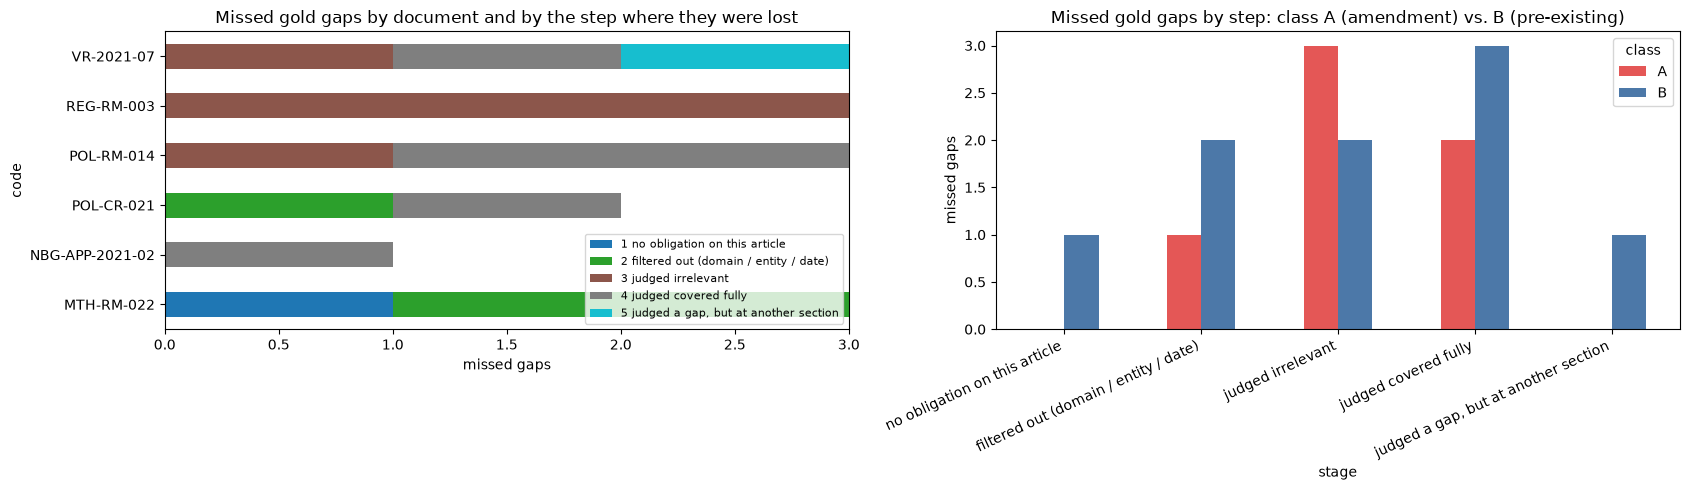

In [28]:
# --- 4. charts: where the missed gaps are lost, per document and per class --------------------------------
present = [s for s in STAGES if s in set(M["stage"])]
fig, axes = plt.subplots(1, 2, figsize=(17, 5))

by_doc = pd.crosstab(M["code"], M["stage"]).reindex(columns=present, fill_value=0)
by_doc.plot(kind="barh", stacked=True, ax=axes[0], colormap="tab10")
axes[0].set_title("Missed gold gaps by document and by the step where they were lost")
axes[0].set_xlabel("missed gaps"); axes[0].legend(fontsize=8, loc="lower right")

by_cls = pd.crosstab(M["stage"], M["class"]).reindex(index=present, fill_value=0)
by_cls.plot(kind="bar", ax=axes[1], color=["#E45756", "#4C78A8"])
axes[1].set_title("Missed gold gaps by step: class A (amendment) vs. B (pre-existing)")
axes[1].set_xticklabels([s.split(" ", 1)[1] for s in present], rotation=25, ha="right")
axes[1].set_ylabel("missed gaps")
plt.tight_layout(); plt.show()

In [29]:
# --- 1. one row per finding (document x obligation) with everything needed to judge its reasoning ------------
import re, random, textwrap
from kg.mapping.docview import load_doc, doc_text
from kg.eval.matching import article_overlap

def s_(v) -> str:
    return v.strip() if isinstance(v, str) else ""

meta = vers.set_index("version_id")
vids = [v for v in meta.index if isinstance(meta.loc[v, "gold_file"], str) or True]   # all checked versions

cov = q("SELECT * FROM coverage WHERE verdict IN ('contradicts','partial','none','full')")
cov = cov[cov["doc_version_id"].isin(vids)]
tri = q("SELECT doc_version_id, obligation_id, relevance, reason FROM triage").set_index(["doc_version_id", "obligation_id"])
props_ = q("SELECT * FROM proposals").set_index(["doc_version_id", "obligation_id"])
tasks_ = q("SELECT doc_version_id, obligation_id, priority, status FROM tasks").set_index(["doc_version_id", "obligation_id"])

obl_nodes = {r.id: json.loads(r.props) for r in q("SELECT id, props FROM nodes WHERE type='Obligation'").itertuples()}
imposes = q("SELECT src, dst FROM edges WHERE type='IMPOSES'").groupby("dst")["src"].apply(list).to_dict()
pv_nodes = {r.id: json.loads(r.props) for r in q("SELECT id, props FROM nodes WHERE type='ProvisionVersion'").itertuples()}
clauses = {r.id: json.loads(r.props) for r in q("SELECT id, props FROM nodes WHERE type='Clause'").itertuples()}
cb = q("SELECT src, dst, props FROM edges WHERE type='COVERED_BY'")
cb["p"] = cb["props"].map(json.loads)
cb["ver"] = cb["p"].map(lambda p: p.get("doc_version"))
cb_by = cb.groupby(["ver", "src"])

# quotes the coverage step dropped as "not verbatim" (logged in the stored step answers)
dropped = defaultdict(int)
for r in q("SELECT subject, errors FROM step_outputs WHERE step='judge' AND errors IS NOT NULL").itertuples():
    ver = r.subject.split(":judge:")[0]
    for oid in re.findall(r"note: (obl:[^:]+:[^:]+?): quote not verbatim", r.errors or ""):
        dropped[(ver, oid)] += 1

doc_cache = {}
def document(v: str) -> tuple[str, set]:
    if v not in doc_cache:
        view = load_doc(store, v)
        secs = {str(u.get("section_no")) for u in view.units if u.get("section_no")}
        doc_cache[v] = (doc_text(view, mapped_only=True), secs)
    return doc_cache[v]

def source_text(oid: str) -> tuple[str, str]:
    pvs = [p for p in imposes.get(oid, []) if p in pv_nodes]
    lab = "; ".join(s_(pv_nodes[p].get("display")) or pv_nodes[p].get("path", "") for p in pvs)
    txt = "\n".join(f"[{s_(pv_nodes[p].get('display')) or pv_nodes[p].get('path')}] {s_(pv_nodes[p].get('text'))}"
                    for p in pvs)
    return lab, txt

finding_key = {(r.version_id, r.obligation_id): r for r in F.itertuples()} if len(F) else {}
gold_by_file = defaultdict(list)
for g in GOLD_BY_ID.values():
    gold_by_file[g["document_file"]].append(g)

rows = []
for c in cov.itertuples():
    v, oid = c.doc_version_id, c.obligation_id
    ob = obl_nodes.get(oid, {})
    m = meta.loc[v]
    lab, src = source_text(oid)
    t = tri.loc[(v, oid)] if (v, oid) in tri.index else None
    pr = props_.loc[(v, oid)] if (v, oid) in props_.index else None
    tk = tasks_.loc[(v, oid)] if (v, oid) in tasks_.index else None
    # linked clauses
    ev, ev_txt, roles = [], [], []
    if (v, oid) in cb_by.groups:
        for e in cb_by.get_group((v, oid)).itertuples():
            cl = clauses.get(e.dst, {})
            roles.append(e.p.get("role"))
            ev.append(f"§{cl.get('section_no') or '—'} [{e.p.get('role')}] „{s_(e.p.get('quote'))}“ — {s_(e.p.get('why'))}")
            ev_txt.append(f"[{e.dst}] §{cl.get('section_no') or '—'} {s_(cl.get('text'))}")
    # gold: matched findings (A/B), and gold items on the same article of this document
    fk = finding_key.get((v, oid))
    matched = sorted(fk.gold_AB) if fk is not None else []
    gf = m["gold_file"] if isinstance(m["gold_file"], str) else None
    near = [g for g in gold_by_file.get(gf, []) if article_overlap(ob.get("source_path"), g["paths"])] if gf else []
    rows.append({
        "finding_id": f"{v}|{oid}", "document": m["code"], "doc_type": m["doc_type"], "direction": m["direction"],
        "version_id": v, "obligation_id": oid, "source_path": ob.get("source_path"),
        "act": s_((pv_nodes.get((imposes.get(oid) or [None])[0]) or {}).get("act_short")) or ob.get("act"),
        "provision": lab, "obligation": s_(ob.get("statement")), "regulation_text": src,
        "relevance": t["relevance"] if t is not None else None, "relevance_reason": s_(t["reason"]) if t is not None else "",
        "verdict": c.verdict, "rationale": s_(c.rationale), "missing": s_(c.missing),
        "priority": tk["priority"] if tk is not None else None, "cause": c.cause,
        "evidence": "\n".join(ev), "evidence_roles": ",".join(sorted(set(r for r in roles if r))),
        "evidence_clause_text": "\n".join(ev_txt), "quotes_dropped": dropped.get((v, oid), 0),
        "proposal_kind": pr["kind"] if pr is not None else None,
        "proposal_heading": s_(pr["heading"]) if pr is not None else "",
        "proposal_text": s_(pr["proposed_text"]) if pr is not None else "",
        "proposal_explanation": s_(pr["explanation"]) if pr is not None else "",
        "proposal_flags": s_(pr["flags"]) if pr is not None else "",
        "gold_matched": bool(matched), "gold_ids": ", ".join(matched),
        "gold_class": ", ".join(sorted({GOLD_BY_ID[i]["class"] for i in matched})),
        "gold_says": "\n".join(GOLD_BY_ID[i]["what_the_document_says"] for i in matched),
        "gold_requirement": "\n".join(GOLD_BY_ID[i]["requirement"] for i in matched),
        "gold_expected_fix": "\n".join(GOLD_BY_ID[i].get("expected_fix", "") for i in matched),
        "gold_on_same_article": "\n".join(f"{g['id']} ({g['class']}, §{g['document_section']}): {g['requirement']}"
                                          for g in near if g["id"] not in matched),
    })
R = pd.DataFrame(rows)
print(f"{len(R):,} findings · verdicts: {R['verdict'].value_counts().to_dict()}")
display(pd.crosstab(R["document"], R["verdict"], margins=True))

839 findings · verdicts: {'partial': 348, 'none': 330, 'full': 106, 'contradicts': 55}


verdict,contradicts,full,none,partial,All
document,,,,,
EG-01,3,2,41,20,66
IA-2022-03,7,6,32,65,110
MR-2022-Q1,10,5,15,33,63
MTH-RM-022,22,12,110,31,175
NBG-APP-2021-02,1,10,30,62,103
POL-CR-021,6,7,28,31,72
POL-RM-014,1,44,25,64,134
REG-RM-003,1,0,27,8,36
VR-2021-07,4,20,22,34,80


In [30]:
# --- 2. automatic checks ----------------------------------------------------------------------------------------
NUM = re.compile(r"(?<![\d.])(\d+(?:[.,]\d+)?)\s*(%|პროცენტ)?")
SEC = re.compile(r"(?:§\s*|პუნქტ\w*\s+|ქვეთავ\w*\s+|თავ\w*\s+|სექცი\w*\s+|section\s+)(\d{1,2}(?:\.\d{1,2}){0,3})\b", re.I)
STOP = {"უნდა", "ბანკი", "ბანკმა", "ბანკის", "კომერციული", "კომერციულმა", "შესაბამისად", "დოკუმენტი", "დოკუმენტში"}

def norm_num(x: str) -> str:
    return x.replace(",", ".").rstrip(".0") if "." in x or "," in x else x

def checks(r) -> dict:
    doc, secs = document(r["version_id"])
    reason = f"{r['rationale']} {r['missing']}"
    pool = " ".join([doc, r["regulation_text"], r["obligation"], r["evidence_clause_text"]])
    pool_nums = {norm_num(n) for n, _ in NUM.findall(pool)}
    # 1. numbers in the reasoning that appear nowhere in the document / regulation / obligation
    sec_refs = {m for m in SEC.findall(reason)}
    nums = {norm_num(n) for n, _ in NUM.findall(reason)} - {norm_num(x) for x in sec_refs}
    nums = {n for n in nums if not (n.isdigit() and int(n) < 4)}            # 1, 2, 3: list items, counts
    ungrounded = sorted(n for n in nums if n not in pool_nums)
    # 2. section numbers named in the reasoning that the document does not have
    unknown_sec = sorted(sr for sr in sec_refs if sr not in secs and sr.rstrip(".") not in secs)
    # 3. consistency of verdict, evidence roles, missing text and proposal
    roles = set(filter(None, r["evidence_roles"].split(",")))
    incons = []
    if r["verdict"] == "full" and not roles & {"full", "partial"}:
        incons.append("full without a supporting clause")
    if r["verdict"] == "contradicts" and not roles & {"contradicts", "partial"}:
        incons.append("contradicts without a cited clause")
    if r["verdict"] == "full" and r["missing"]:
        incons.append("full but something is missing")
    if r["verdict"] in ("partial", "none") and not r["missing"]:
        incons.append("gap without a 'missing' text")
    if r["verdict"] != "full" and not r["proposal_kind"]:
        incons.append("gap without a proposal")
    # 4. "missing" verdicts: how many key terms of the obligation the document does contain (high = suspicious)
    absence_overlap = None
    if r["verdict"] == "none":
        words = {w[:6] for w in re.findall(r"[ა-ჰ]{6,}", r["obligation"]) if w not in STOP}
        if words:
            absence_overlap = round(sum(1 for w in words if w in doc) / len(words), 2)
    flags = (["ungrounded number"] if ungrounded else []) + (["unknown section"] if unknown_sec else []) + \
            (["inconsistent"] if incons else []) + (["quotes dropped"] if r["quotes_dropped"] else []) + \
            (["absence doubtful"] if (absence_overlap or 0) >= 0.7 else [])
    return {"ungrounded_numbers": ", ".join(ungrounded), "unknown_sections": ", ".join(unknown_sec),
            "inconsistencies": "; ".join(incons), "absence_overlap": absence_overlap, "auto_flags": "; ".join(flags)}

R = pd.concat([R.drop(columns=[c for c in ("ungrounded_numbers", "unknown_sections", "inconsistencies",
                                            "absence_overlap", "auto_flags") if c in R]),
               R.apply(checks, axis=1, result_type="expand")], axis=1)

flag_cols = {"ungrounded number": "ungrounded_numbers", "unknown section": "unknown_sections",
             "inconsistent": "inconsistencies", "quotes dropped": "quotes_dropped", "absence doubtful": "absence_overlap"}
summary = pd.DataFrame({f: R.groupby("verdict")["auto_flags"].apply(lambda s: s.str.contains(f).mean())
                        for f in flag_cols}).mul(100).round(1)
summary["any flag %"] = R.groupby("verdict")["auto_flags"].apply(lambda s: (s != "").mean() * 100).round(1)
summary["findings"] = R.groupby("verdict").size()
print("share of findings with each automatic flag (%), per verdict:")
display(summary)
display(pd.crosstab(R["document"], R["auto_flags"] != "", normalize="index").mul(100).round(1)
        .rename(columns={True: "flagged %", False: "clean %"}))
display(R[R["auto_flags"] != ""][["document", "verdict", "source_path", "auto_flags", "ungrounded_numbers",
                                  "unknown_sections", "inconsistencies", "rationale"]].head(30))

share of findings with each automatic flag (%), per verdict:


,ungrounded number,unknown section,inconsistent,quotes dropped,absence doubtful,any flag %,findings
verdict,,,,,,,
contradicts,1.8,0.0,1.8,0.0,0.0,3.6,55
full,0.0,0.0,0.0,0.0,0.0,0.0,106
none,0.0,0.0,22.1,0.0,9.1,29.4,330
partial,0.0,0.0,0.3,0.0,0.0,0.3,348


auto_flags,clean %,flagged %
document,,
EG-01,93.9,6.1
IA-2022-03,81.8,18.2
MR-2022-Q1,84.1,15.9
MTH-RM-022,84.6,15.4
NBG-APP-2021-02,92.2,7.8
POL-CR-021,94.4,5.6
POL-RM-014,91.8,8.2
REG-RM-003,75.0,25.0
VR-2021-07,91.2,8.8


,document,verdict,source_path,auto_flags,ungrounded_numbers,unknown_sections,inconsistencies,rationale
3,POL-RM-014,none,art10/p3,inconsistent,,,gap without a 'missing' text,"დოკუმენტში არ არის ნახსენები 6-თვიანი ვადა, რომლის განმავლობაშიც სუბიექტმა უნდა მიმართოს ეროვნულ ბანკს თანხმობის მისაღებად."
49,POL-RM-014,none,art5/p6,absence doubtful,,,,"დოკუმენტში ნახსენებია გამოტოვებული მნიშვნელობების ანალიზი ტესტირებისას, მაგრამ არ არის განსაზღვრული კონკრეტული მიდგომა ამ მონაცემების მართვისთვის."
65,POL-RM-014,none,art6/p4.1/sბ.ე,absence doubtful,,,,წარმოდგენილ დოკუმენტში არ არის ნახსენები მოდელების ურთიერთდამოკიდებულების შეფასების საჭიროება.
66,POL-RM-014,none,art6/p4.1,absence doubtful,,,,"მიუხედავად იმისა, რომ დოკუმენტი ეხება ვალიდაციას, ის არ შეიცავს კონკრეტულ მითითებას, რომ პროცესი უნდა იყოს რისკზე დაფუძნებული."
68,POL-RM-014,none,art6/p4.1,absence doubtful,,,,"დოკუმენტი ახსენებს მოდელის მატერიალურობას ზოგადად (მაგალითად, მოქმედების სფეროში), მაგრამ არ აკავშირებს მას რანჟირების პროცესთან."
69,POL-RM-014,none,art6/p4.1,absence doubtful,,,,წარმოდგენილ დოკუმენტში არ არის ნახსენები მოდელების რანჟირების ან დაჯგუფების პროცესი და მასში რისკის გათვალისწინების წესი.
70,POL-RM-014,none,art6/p4.1/sა.ა,absence doubtful,,,,"პოლიტიკა არ შეიცავს მატერიალურობის განსაზღვრის პროცედურას, სადაც მოდელის შეცდომის ეკონომიკური შედეგები უნდა იქნეს გათვალისწინებული."
79,POL-RM-014,none,art6/p5/sგ,absence doubtful,,,,"მიუხედავად იმისა, რომ დოკუმენტი ეხება შედეგების ანალიზს, იგი არ განსაზღვრავს ამ პროცესის კონკრეტულ მიზანს შეცდომის წყაროს იდენტიფიცირების შესახებ."
80,POL-RM-014,none,art6/p5/sგ,absence doubtful,,,,"დოკუმენტი აღწერს ვალიდაციის და ტესტირების პროცესებს, მაგრამ არ შეიცავს სპეციფიკურ მოთხოვნას ტესტირების მეთოდისა და ინტერპრეტაციის დოკუმენტირების შესახებ."
100,POL-RM-014,none,art7/p3,absence doubtful,,,,"წარმოდგენილ დოკუმენტში არ არის არცერთი მუხლი, რომელიც დაცვის მესამე ხაზს კორპორაციული მართვის კოდექსის შესაბამისობას ავალდებულებდა."


In [31]:
# --- 3. sample + files for a reviewing model ---------------------------------------------------------------------
N_PER_STRATUM = 25            # per verdict (partial / none / full) and direction
INCLUDE_FLAGGED = True        # also every finding with an automatic flag
SEED = 7

rng = random.Random(SEED)
pick = set(R.loc[R["verdict"] == "contradicts", "finding_id"])                    # every "contradicts"
for (verdict, direction), grp in R[R["verdict"] != "contradicts"].groupby(["verdict", "direction"]):
    ids = sorted(grp["finding_id"])
    pick |= set(rng.sample(ids, min(N_PER_STRATUM, len(ids))))
if INCLUDE_FLAGGED:
    pick |= set(R.loc[R["auto_flags"] != "", "finding_id"])

S = R[R["finding_id"].isin(pick)].copy()
S["document_text"] = S["version_id"].map(lambda v: document(v)[0])
S["in_sample_because"] = np.select(
    [S["verdict"] == "contradicts", S["auto_flags"] != ""], ["all contradicts", "automatic flag"], "random sample")
REVIEW = ["review_hallucination", "review_unsupported_claims", "review_argument_quality",
          "review_proposal_alignment", "review_gold_reason_alignment", "review_verdict_correct", "review_comment"]
for c in REVIEW:
    S[c] = ""
order = (["finding_id", "in_sample_because", "document", "doc_type", "direction", "act", "provision", "source_path",
          "obligation", "regulation_text", "relevance", "relevance_reason", "verdict", "priority", "cause",
          "rationale", "missing", "evidence", "evidence_clause_text", "proposal_kind", "proposal_heading",
          "proposal_text", "proposal_explanation", "proposal_flags", "gold_matched", "gold_ids", "gold_class",
          "gold_says", "gold_requirement", "gold_expected_fix", "gold_on_same_article", "auto_flags",
          "ungrounded_numbers", "unknown_sections", "inconsistencies", "absence_overlap", "quotes_dropped",
          "document_text"] + REVIEW)
S = S[order].sort_values(["in_sample_because", "document", "verdict"])
out_dir = ROOT / "evaluation"
S.to_csv(out_dir / "reasoning_review_sample.csv", index=False, encoding="utf-8-sig")
R.drop(columns=[c for c in ("document_text",) if c in R]).to_csv(out_dir / "reasoning_all.csv", index=False,
                                                                   encoding="utf-8-sig")
print(f"sample: {len(S)} findings → evaluation/reasoning_review_sample.csv")
display(S.groupby(["in_sample_because", "verdict"]).size().unstack(fill_value=0))
print(f"all findings with automatic checks: {len(R):,} → evaluation/reasoning_all.csv")

PROMPT = textwrap.dedent("""
You review the output of a compliance-checking system that compared a bank's internal document with a regulation
of the National Bank of Georgia. Each row is ONE finding: an obligation from the regulation and the system's
assessment of how the document covers it. Texts are in Georgian; answer in English.

Columns you use:
- obligation, regulation_text (the provision the obligation comes from), provision (its article / paragraph)
- verdict (contradicts | partial = partly covered | none = missing | full = fully covered), rationale, missing
- evidence: the document clauses the system cited, as "§section [role] „quote“ — why"; evidence_clause_text: their full text
- document_text: the whole internal document, one clause per line as "[clause id] section text"
- proposal_*: the change the system proposes
- gold_*: if gold_matched is true, an expert answer key describes the same gap (gold_says, gold_requirement, gold_expected_fix)
- auto_flags: problems found by simple automatic checks (hints, not verdicts)

For EVERY row return one JSON object:
{"finding_id": "...",
 "review_hallucination": "none | minor | major"       (claims in rationale / missing / evidence that the document or
                                                         regulation text does not support; a wrong quote is major),
 "review_unsupported_claims": "the unsupported claims, each in a few words, or empty",
 "review_verdict_correct": "yes | partly | no"         (is the verdict right, judged from document_text and regulation_text;
                                                         for 'none' check that the document really does not address it),
 "review_argument_quality": 1-5                        (1 = no real argument, 5 = precise, cites the right clause and
                                                         the decisive difference to the requirement),
 "review_proposal_alignment": 1-5 or null              (does the proposal fix exactly what rationale / missing say,
                                                         without inventing numbers or roles; null if no proposal),
 "review_gold_reason_alignment": 1-5 or null           (only if gold_matched: does the system's reason describe the
                                                         same problem as gold_says / gold_requirement),
 "review_comment": "one sentence"}
Quote the decisive words from document_text or regulation_text in review_comment when you say a claim is unsupported.
Return a JSON list only.
""").strip()
print("\n" + PROMPT)

sample: 332 findings → evaluation/reasoning_review_sample.csv


verdict,contradicts,full,none,partial
in_sample_because,,,,
all contradicts,55,0,0,0
automatic flag,0,0,97,1
random sample,0,44,60,75


all findings with automatic checks: 839 → evaluation/reasoning_all.csv

You review the output of a compliance-checking system that compared a bank's internal document with a regulation
of the National Bank of Georgia. Each row is ONE finding: an obligation from the regulation and the system's
assessment of how the document covers it. Texts are in Georgian; answer in English.

Columns you use:
- obligation, regulation_text (the provision the obligation comes from), provision (its article / paragraph)
- verdict (contradicts | partial = partly covered | none = missing | full = fully covered), rationale, missing
- evidence: the document clauses the system cited, as "§section [role] „quote“ — why"; evidence_clause_text: their full text
- document_text: the whole internal document, one clause per line as "[clause id] section text"
- proposal_*: the change the system proposes
- gold_*: if gold_matched is true, an expert answer key describes the same gap (gold_says, gold_requirement, gold_expe

In [32]:
# --- 2b. plain-text summary to paste into the chat (no document text) ---------------------------------------
from collections import Counter
pd.set_option("display.width", 250, "display.max_colwidth", 120)
def show(title, obj): print(f"\n=== {title} ===\n{obj.to_string() if hasattr(obj, 'to_string') else obj}")

show("findings", f"{len(R):,}  {R['verdict'].value_counts().to_dict()}")
show("document x verdict", pd.crosstab(R["document"], R["verdict"], margins=True))
show("flag share % per verdict", summary)
show("flagged % per document", pd.crosstab(R["document"], R["auto_flags"] != "", normalize="index").mul(100).round(1))
show("flagged % per direction x verdict",
     R.assign(f=R["auto_flags"] != "").pivot_table(index="direction", columns="verdict", values="f", aggfunc="mean").mul(100).round(1))
show("flagged % by gold match (contradicts/partial/none)",
     R[R["verdict"] != "full"].assign(f=R["auto_flags"] != "").groupby(["verdict", "gold_matched"])["f"].agg(["mean", "size"]).round(3))
show("inconsistency types", pd.Series(Counter(x.strip() for s in R["inconsistencies"] for x in s.split(";") if x.strip())))
show("most common ungrounded numbers", pd.Series(Counter(x.strip() for s in R["ungrounded_numbers"] for x in s.split(",") if x.strip())).sort_values(ascending=False).head(20))
show("unknown sections (doc: sections)", R[R["unknown_sections"] != ""].groupby("document")["unknown_sections"].apply(lambda s: sorted(set(", ".join(s).split(", ")))[:15]))
show("quotes dropped: findings with >0, per document", R.groupby("document")["quotes_dropped"].agg(lambda s: f"{(s > 0).sum()} / {len(s)}  (total {s.sum()})"))
show("absence_overlap for 'none' (share of obligation key terms found in the doc)",
     R.loc[R["verdict"] == "none", "absence_overlap"].describe().round(2))
show("absence_overlap >= 0.7 per document",
     R[R["verdict"] == "none"].groupby("document")["absence_overlap"].apply(lambda s: f"{(s >= 0.7).sum()} / {len(s)}"))
show("sample of flagged rows",
     R[R["auto_flags"] != ""].sample(min(25, (R["auto_flags"] != "").sum()), random_state=1)
       [["document", "verdict", "source_path", "auto_flags", "ungrounded_numbers", "unknown_sections", "inconsistencies"]]
       .assign(rationale=R["rationale"].str.slice(0, 200)))


=== findings ===
839  {'partial': 348, 'none': 330, 'full': 106, 'contradicts': 55}

=== document x verdict ===
verdict          contradicts  full  none  partial  All
document                                              
EG-01                      3     2    41       20   66
IA-2022-03                 7     6    32       65  110
MR-2022-Q1                10     5    15       33   63
MTH-RM-022                22    12   110       31  175
NBG-APP-2021-02            1    10    30       62  103
POL-CR-021                 6     7    28       31   72
POL-RM-014                 1    44    25       64  134
REG-RM-003                 1     0    27        8   36
VR-2021-07                 4    20    22       34   80
All                       55   106   330      348  839

=== flag share % per verdict ===
             ungrounded number  unknown section  inconsistent  quotes dropped  absence doubtful  any flag %  findings
verdict                                                                    

In [40]:
# --- 3. sample: contradictions (= critical, capped per document) + the SAME number of random "none" / "partial" per document ---
N_PER_DOC = {"none": 8, "partial": 8}     # random findings per document and verdict (all of them when fewer exist)
N_FULL_PER_DOC = 0                        # optional: a few "full" per document, to look for missed gaps
SEED = 7
SPREAD = True      # contradictions cut: True = keep findings that cite DIFFERENT clauses; False = plain random cut

rng = random.Random(SEED)

# --- every contradiction (= critical), but no document contributes more than the SECOND-largest document does ----
contra = R[R["verdict"] == "contradicts"]
counts = contra.groupby("document").size().sort_values(ascending=False)
CAP_CONTRA = int(counts.iloc[1]) if len(counts) > 1 else int(counts.iloc[0])      # 10 (MR-2022-Q1); MTH-RM-022 has 22

def pick_contradictions(grp, k):
    if not SPREAD:
        return rng.sample(sorted(grp["finding_id"]), k)
    key = grp["evidence"].str.extract(r"§(\S+) \[contradicts\]")[0].fillna("-")
    buckets = {g: rng.sample(sorted(ids), len(ids)) for g, ids in grp.groupby(key)["finding_id"]}
    out = []
    while len(out) < k:                                                           # one finding per cited clause, round by round
        for g in sorted(buckets, key=lambda x: rng.random()):
            if buckets[g] and len(out) < k:
                out.append(buckets[g].pop())
    return out

pick = set()
for doc, grp in contra.groupby("document"):
    pick |= set(grp["finding_id"]) if len(grp) <= CAP_CONTRA else set(pick_contradictions(grp, CAP_CONTRA))
print(f"contradictions: {len(contra)} found, {len(pick)} in the sample (cap per document = {CAP_CONTRA})")

# --- the same number of random "none" / "partial" (and optionally "full") per document: documents count equally ---
for verdict, n in {**N_PER_DOC, "full": N_FULL_PER_DOC}.items():
    for doc, grp in R[R["verdict"] == verdict].groupby("document"):
        ids = sorted(grp["finding_id"])
        pick |= set(rng.sample(ids, min(n, len(ids))))

# --- context for the reviewer: the paragraph the obligation comes from first, then the rest of its article ---------
def _nat(path: str):
    return [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", path) if t]

PV_BY = defaultdict(list)                                                # (act, article) -> [(path, date, text)]
for pid, p in pv_nodes.items():
    m = re.match(r"pv:(\d+)/([^@]+)@(.+)$", pid)
    if m:
        PV_BY[(m.group(1), m.group(2).split("/")[0])].append((m.group(2), m.group(3), s_(p.get("text"))))

def article_context(oid: str, own_limit: int = 3000, rest_limit: int = 2500) -> str:
    ob = obl_nodes.get(oid, {})
    act, path = str(ob.get("act")), ob.get("source_path") or ""
    art = path.split("/")[0]
    para = "/".join(path.split("/")[:2])                                 # artN/pK
    since = ob.get("unit_date") or ob.get("effective_from") or "9999"
    best = {}
    for p, date, text in PV_BY.get((act, art), []):                      # per provision: the version in force at that date
        if p not in best or (date <= since and (best[p][0] > since or date > best[p][0])):
            best[p] = (date, text)
    items = sorted(((p, t) for p, (d, t) in best.items() if t), key=lambda kv: _nat(kv[0]))
    own = [f"[{p}] {t}" for p, t in items if p == para or p.startswith(para + "/")]
    rest = [f"[{p}] {t}" for p, t in items if not (p == para or p.startswith(para + "/"))]
    cut = lambda parts, n: ("\n".join(parts) if len("\n".join(parts)) <= n else "\n".join(parts)[:n] + " …")
    return ("THIS PARAGRAPH:\n" + cut(own, own_limit) + "\n\nREST OF THE ARTICLE:\n" + cut(rest, rest_limit)) if own \
        else cut(rest, own_limit + rest_limit)

# --- assemble and save ---------------------------------------------------------------------------------------------
S = R[R["finding_id"].isin(pick)].copy()
S["article_context"] = S["obligation_id"].map(article_context)
S["document_text"] = S["version_id"].map(lambda v: document(v)[0])
S["in_sample_because"] = np.where(S["verdict"] == "contradicts", "critical (contradicts)", "random per document")
REVIEW = ["review_in_scope", "review_obligation_faithful", "review_hallucination", "review_unsupported_claims",
          "review_verdict_correct", "review_correct_verdict", "review_error_type", "review_argument_quality",
          "review_proposal_alignment", "review_gold_reason_alignment", "review_comment"]
for c in REVIEW:
    S[c] = ""
order = (["finding_id", "in_sample_because", "document", "doc_type", "direction", "act", "provision", "source_path",
          "obligation", "regulation_text", "article_context", "relevance", "relevance_reason", "verdict", "priority", "cause",
          "rationale", "missing", "evidence", "evidence_clause_text", "proposal_kind", "proposal_heading",
          "proposal_text", "proposal_explanation", "proposal_flags", "gold_matched", "gold_ids", "gold_class",
          "gold_says", "gold_requirement", "gold_expected_fix", "gold_on_same_article", "auto_flags",
          "ungrounded_numbers", "unknown_sections", "inconsistencies", "absence_overlap", "quotes_dropped",
          "document_text"] + REVIEW)
S = S[order].sort_values(["document", "verdict", "source_path"])
out_dir = ROOT / "evaluation"
S.to_csv(out_dir / "reasoning_review_sample.csv", index=False, encoding="utf-8-sig")
R.drop(columns=[c for c in ("document_text",) if c in R]).to_csv(out_dir / "reasoning_all.csv", index=False,
                                                                   encoding="utf-8-sig")
print(f"sample: {len(S)} findings → evaluation/reasoning_review_sample.csv   (all findings: {len(R):,} → reasoning_all.csv)")
display(pd.crosstab(S["document"], S["verdict"], margins=True))

contradictions: 55 found, 43 in the sample (cap per document = 10)
sample: 187 findings → evaluation/reasoning_review_sample.csv   (all findings: 839 → reasoning_all.csv)


verdict,contradicts,none,partial,All
document,,,,
EG-01,3,8,8,19
IA-2022-03,7,8,8,23
MR-2022-Q1,10,8,8,26
MTH-RM-022,10,8,8,26
NBG-APP-2021-02,1,8,8,17
POL-CR-021,6,8,8,22
POL-RM-014,1,8,8,17
REG-RM-003,1,8,8,17
VR-2021-07,4,8,8,20


In [41]:
# --- 4. batch files for reviewing in a chat (one folder per document) -------------------------------------
BATCH_SIZE = 8                      # findings per batch file (the article context makes each finding long)
B = ROOT / "evaluation" / "review_batches"
B.mkdir(parents=True, exist_ok=True)

def _v(x) -> str:
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return ""
    return str(x).strip()

def block(i: int, r) -> str:
    f = lambda label, v: f"{label}: {_v(v)}\n" if _v(v) else ""
    if r.gold_matched:
        gold = (f("gold_ids", r.gold_ids) + f("gold_class", r.gold_class) + f("gold_says", r.gold_says)
                + f("gold_requirement", r.gold_requirement) + f("gold_expected_fix", r.gold_expected_fix))
    else:
        gold = "gold_matched: no\n" + f("gold_on_same_article", r.gold_on_same_article)
    return (f"\n### Finding {i}\nfinding_id: {r.finding_id}\n"
            + f("provision", r.provision) + f("source_path", r.source_path)
            + f("obligation", r.obligation) + f("regulation_text", r.regulation_text)
            + f("article_context", r.article_context)
            + f("verdict", r.verdict) + f("rationale", r.rationale) + f("missing", r.missing)
            + f("evidence", r.evidence)
            + f("proposal_kind", r.proposal_kind) + f("proposal_heading", r.proposal_heading)
            + f("proposal_text", r.proposal_text) + f("proposal_explanation", r.proposal_explanation)
            + "--- answer key: read only AFTER deciding review_correct_verdict ---\n" + gold)

manifest = []
for doc, grp in S.groupby("document"):
    d = B / doc
    d.mkdir(exist_ok=True)
    first = grp.iloc[0]
    (d / "document.txt").write_text(
        f"INTERNAL DOCUMENT {doc} (type: {first.doc_type}, direction: {first.direction})\n"
        f"One clause per line: [clause id] §section text\n\n{first.document_text}\n", encoding="utf-8")
    rows_ = list(grp.sort_values(["verdict", "source_path"]).itertuples())
    for b in range(0, len(rows_), BATCH_SIZE):
        part = rows_[b:b + BATCH_SIZE]
        n = b // BATCH_SIZE + 1
        txt = f"BATCH {n} — document {doc} — {len(part)} findings\n" + "".join(
            block(b + k + 1, r) for k, r in enumerate(part))
        (d / f"batch_{n:02d}.txt").write_text(txt, encoding="utf-8")
        manifest += [{"document": doc, "batch": n, "finding_id": r.finding_id} for r in part]
pd.DataFrame(manifest).to_csv(B / "manifest.csv", index=False)

PROMPT_CHAT = textwrap.dedent("""
You are an independent reviewer of a compliance-checking system. The system compared a bank's internal document with
a regulation of the National Bank of Georgia and produced findings. All texts are Georgian; write your answer in
English and quote the decisive Georgian words where needed.

Attached: document.txt (the whole internal document, one clause per line as "[clause id] §section text") and a batch
file with findings. Each finding is ONE obligation taken from a regulation, plus the system's assessment:
- obligation: the system's one-sentence statement of the requirement.
- regulation_text and article_context: the source provision, and its article ("THIS PARAGRAPH" first, then the rest).
- verdict: contradicts = the document says something that conflicts with the requirement; partial = part of the
  requirement is met but a specific element is missing; none = the document does not address it at all;
  full = every element is met.
- rationale, missing: the system's reasoning. evidence: the clauses it cites, as "§section [role] „quote“ — why".
- proposal_*: the change the system suggests.
- The block after "answer key" is an expert label. Read it only AFTER you have decided review_correct_verdict.

For each finding, work in this order:
1. Obligation vs regulation. Does the obligation say what the regulation text says? Check the modality (a
   recommendation such as "რეკომენდებულია" or a permission is not a duty), the scope, and whether examples after
   "მათ შორის" ("including") were turned into a closed, mandatory list.
2. Scope. Could this TYPE of document contain this requirement at all? (A duty of a policy is not a gap in an audit
   report, a monitoring report or a register.)
3. Your own verdict, decided from document.txt and the regulation BEFORE you read the system's rationale. For "none",
   search the whole document, including synonyms, paraphrases and tables, before agreeing it is absent. For
   "contradicts", the document must state something that conflicts, not merely omit. For "partial", name the exact
   missing element and check that the regulation really requires it. Apply the regulation as written: do not be
   stricter or more lenient than its text.
4. Then check the system's claims. Every quote must really be in document.txt and say what the system claims; every
   number and section it names must exist.
5. Then the proposal. Then, only if an answer key is given, compare it with the system's reason.

Return ONLY a JSON list (no markdown fences), one object per finding, in batch order, none omitted:
{"finding_id": "<copy exactly>",
 "review_in_scope": "yes | no | unclear",
 "review_obligation_faithful": "yes | no | unclear",   (obligation matches the regulation: modality, scope, no examples made mandatory)
 "review_hallucination": "none | minor | major",        (a wrong quote or a false claim about the document or the regulation = major)
 "review_unsupported_claims": "short list, or empty",
 "review_correct_verdict": "contradicts | partial | none | full | not_applicable",    (your own verdict)
 "review_verdict_correct": "yes | partly | no",         (yes = same as yours; partly = right direction, wrong degree, e.g. partial vs none;
                                                         no = gap where the document complies, or compliance where there is a gap)
 "review_error_type": "none | too_strict | too_lenient | evidence_missed | wrong_clause | not_in_scope | extraction_error | other",
                                                        (too_strict = demands more than the regulation requires; evidence_missed = a clause that
                                                         satisfies it exists but was not found; wrong_clause = cites an unrelated clause;
                                                         extraction_error = the obligation misstates the regulation)
 "review_argument_quality": 1-5,                        (1 = no real argument, 5 = names the right clause and the decisive difference)
 "review_proposal_alignment": 1-5 or null,              (fixes exactly what rationale / missing say, invents no numbers or roles; null if none)
 "review_gold_reason_alignment": 1-5 or null,           (only with an answer key: the same problem as gold_says / gold_requirement?)
 "review_comment": "one or two sentences quoting the decisive words from document.txt or the regulation"}
If you cannot decide, answer "unclear" rather than guessing. Give your own reasoning; do not repeat the system's wording.
""").strip()
NEXT_CHAT = "Next batch attached (same document, same instructions). Return only the JSON list."
(B / "PROMPT.md").write_text(PROMPT_CHAT, encoding="utf-8")
(B / "NEXT.md").write_text(NEXT_CHAT, encoding="utf-8")

print(pd.DataFrame(manifest).groupby("document")["batch"].agg(["nunique", "size"])
      .rename(columns={"nunique": "batches", "size": "findings"}).to_string())
print(f"\n{len(manifest)} findings in {pd.DataFrame(manifest).groupby(['document', 'batch']).ngroups} batch files → {B}")

                 batches  findings
document                          
EG-01                  3        19
IA-2022-03             3        23
MR-2022-Q1             4        26
MTH-RM-022             4        26
NBG-APP-2021-02        3        17
POL-CR-021             3        22
POL-RM-014             3        17
REG-RM-003             3        17
VR-2021-07             3        20

187 findings in 29 batch files → /Users/macbookpro/Documents/financial_rag/evaluation/review_batches


In [45]:
import json, re, glob, pandas as pd
from pathlib import Path

RB = Path("../evaluation/review_batches")
man = pd.read_csv(RB / "manifest.csv")

# review answers
rows = []
for f in sorted(RB.glob("*/batch_*.answer.json")):
    for r in json.load(open(f, encoding="utf-8")):
        r["document"] = f.parent.name
        rows.append(r)
ans = pd.DataFrame(rows)
ans["finding_id"] = ans["finding_id"].str.replace(" ", "", regex=False)

# system verdict (+ obligation) from the exported batch files
meta = {}
for f in RB.glob("*/batch_*.txt"):
    for blk in f.read_text(encoding="utf-8").split("### Finding ")[1:]:
        fid = re.search(r"finding_id: (.+)", blk).group(1).strip()
        v = re.search(r"\nverdict: (\w+)", blk)
        meta[fid] = v.group(1) if v else None

M = man.merge(ans.drop(columns="document"), on="finding_id", how="left")
M["system_verdict"] = M["finding_id"].map(meta)
for c in ["review_argument_quality", "review_proposal_alignment", "review_gold_reason_alignment"]:
    M[c] = pd.to_numeric(M[c], errors="coerce")

print("manifest:", len(man), "| answered:", M["review_verdict_correct"].notna().sum(),
      "| missing:", M["review_verdict_correct"].isna().sum())
print(M[M["review_verdict_correct"].isna()].groupby("document").size())
M.to_csv("../evaluation/review_merged.csv", index=False)

manifest: 187 | answered: 187 | missing: 0
Series([], dtype: int64)


/var/folders/bg/38ht234d5p50ytp9mrxf80nc0000gn/T/ipykernel_5401/3885712133.py:13: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  (t.div(t.sum(1), axis=0) * 100).plot.bar(stacked=True, ax=ax[0], color=[COL[c] for c in t.columns], rot=0)
/var/folders/bg/38ht234d5p50ytp9mrxf80nc0000gn/T/ipykernel_5401/3885712133.py:14: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  for i, v in enumerate(t.sum(1)): ax[0].text(i, 101, f"n={int(v)}", ha="center")
/var/folders/bg/38ht234d5p50ytp9mrxf80nc0000gn/T/ipykernel_5401/3885712133.py:19: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  (t.div(t.sum(1), axis=0) * 100).plot.barh(stacked=True, ax=ax[1], color=[COL[c] for c in t.columns])


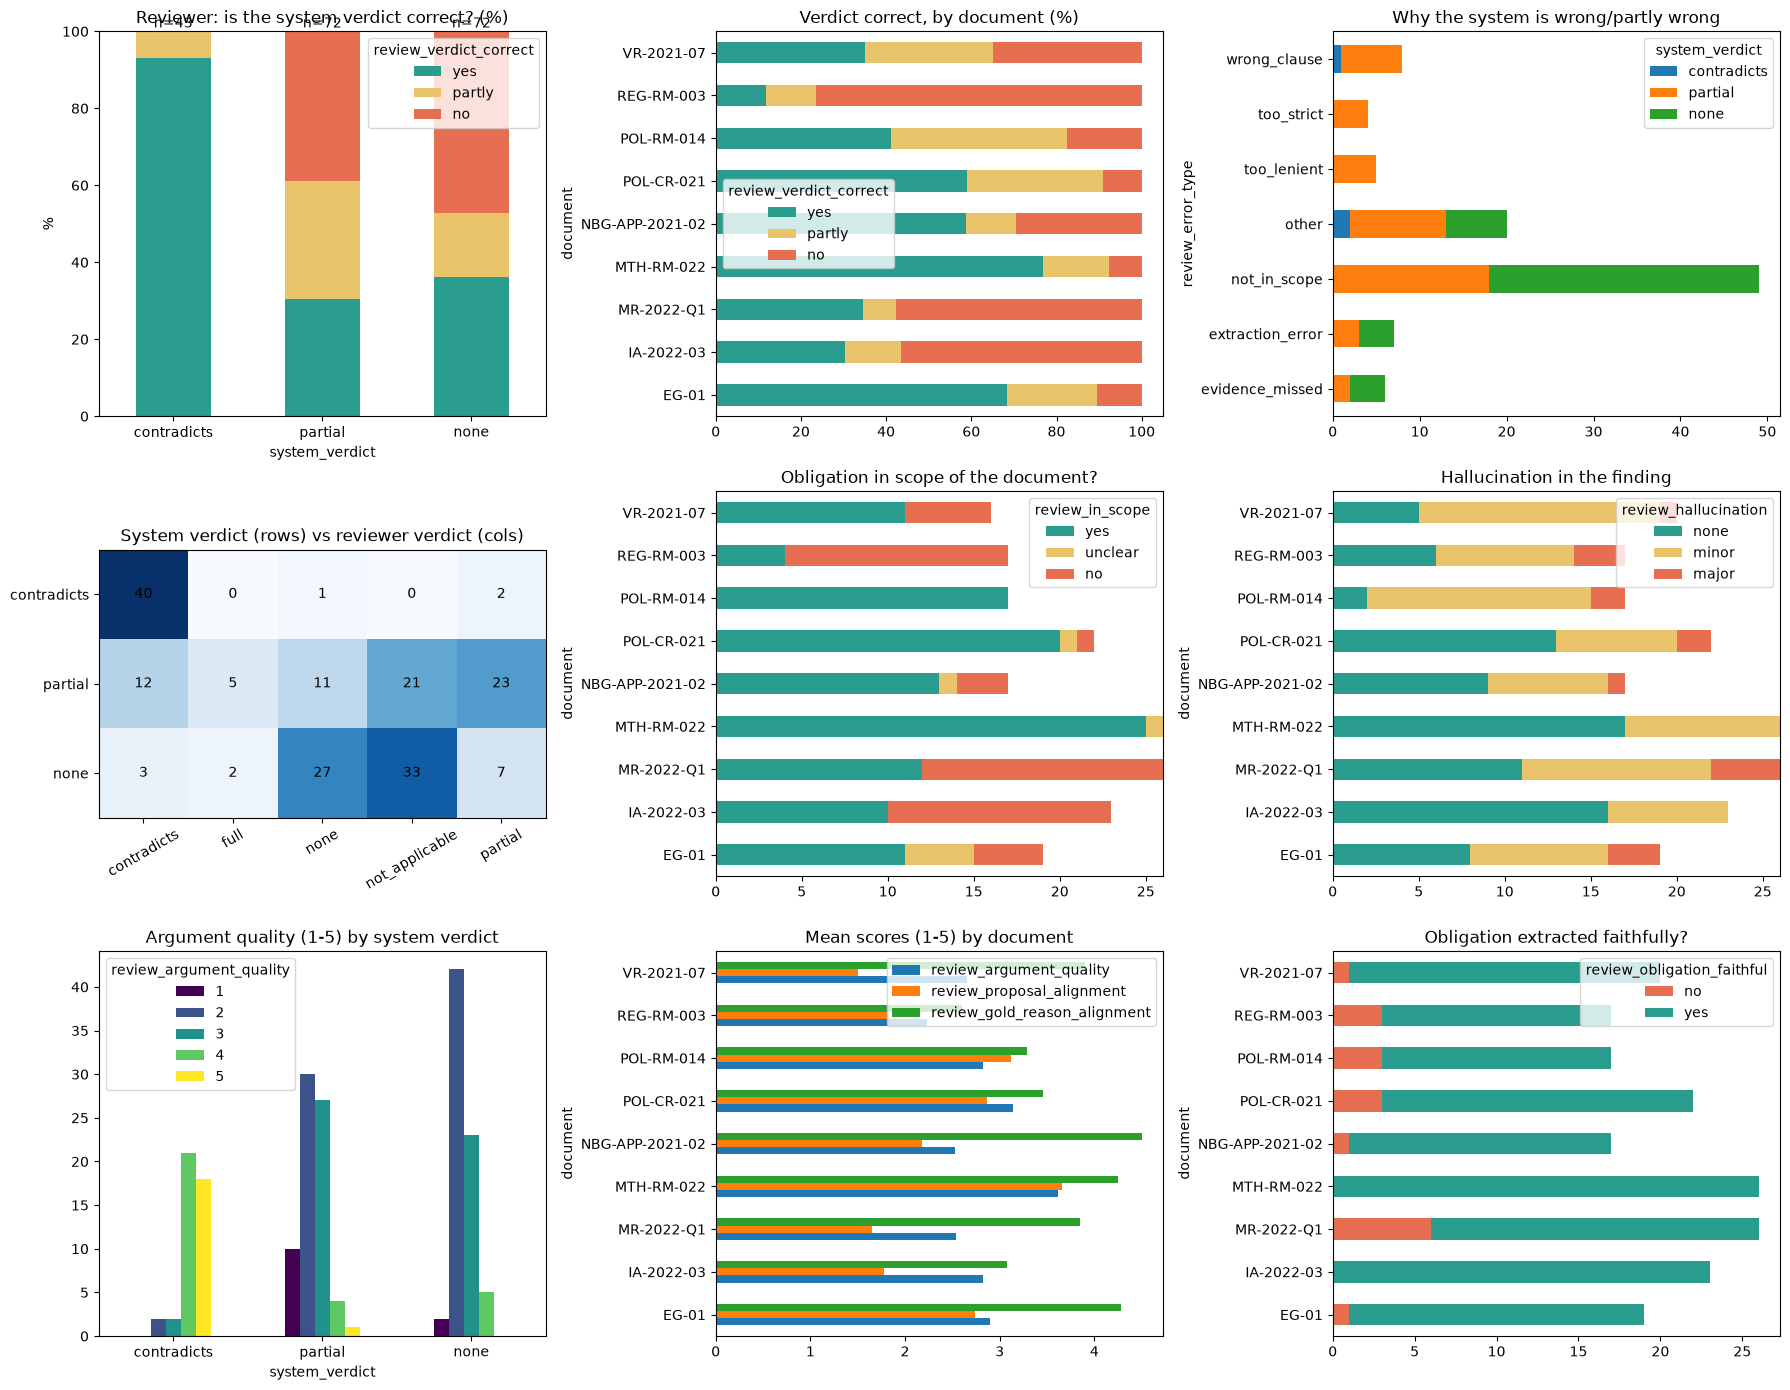

Verdict correct (yes): 47% | yes+partly: 67%
Out of scope (no): 28% | major hallucination: 9% | mean argument quality: 2.84
review_verdict_correct    no  partly   yes
system_verdict                            
contradicts              NaN    0.07  0.93
none                    0.47    0.17  0.36
partial                 0.39    0.31  0.31


In [46]:
import matplotlib.pyplot as plt
import numpy as np

D = M[M["review_verdict_correct"].notna()].copy()
ORDER = ["contradicts", "partial", "none"]
COL = {"yes": "#2a9d8f", "partly": "#e9c46a", "no": "#e76f51"}
fig, ax = plt.subplots(3, 3, figsize=(18, 14))
ax = ax.ravel()

# 1. verdict correctness per system verdict
t = pd.crosstab(D["system_verdict"], D["review_verdict_correct"]).reindex(ORDER).fillna(0)
t = t.reindex(columns=["yes", "partly", "no"], fill_value=0)
(t.div(t.sum(1), axis=0) * 100).plot.bar(stacked=True, ax=ax[0], color=[COL[c] for c in t.columns], rot=0)
for i, v in enumerate(t.sum(1)): ax[0].text(i, 101, f"n={int(v)}", ha="center")
ax[0].set_title("Reviewer: is the system verdict correct? (%)"); ax[0].set_ylabel("%")

# 2. same, per document
t = pd.crosstab(D["document"], D["review_verdict_correct"]).reindex(columns=["yes", "partly", "no"], fill_value=0)
(t.div(t.sum(1), axis=0) * 100).plot.barh(stacked=True, ax=ax[1], color=[COL[c] for c in t.columns])
ax[1].set_title("Verdict correct, by document (%)")

# 3. error types (only where not correct)
E = D[D["review_verdict_correct"] != "yes"]
pd.crosstab(E["review_error_type"], E["system_verdict"]).reindex(columns=ORDER, fill_value=0) \
  .plot.barh(stacked=True, ax=ax[2]); ax[2].set_title("Why the system is wrong/partly wrong")

# 4. system verdict vs reviewer's verdict (heatmap)
ct = pd.crosstab(D["system_verdict"], D["review_correct_verdict"]).reindex(ORDER)
im = ax[3].imshow(ct.values, cmap="Blues")
ax[3].set_xticks(range(ct.shape[1])); ax[3].set_xticklabels(ct.columns, rotation=30)
ax[3].set_yticks(range(ct.shape[0])); ax[3].set_yticklabels(ct.index)
for (i, j), v in np.ndenumerate(ct.values): ax[3].text(j, i, int(v), ha="center", va="center")
ax[3].set_title("System verdict (rows) vs reviewer verdict (cols)")

# 5. in scope
pd.crosstab(D["document"], D["review_in_scope"]).reindex(columns=["yes", "unclear", "no"], fill_value=0) \
  .plot.barh(stacked=True, ax=ax[4], color=["#2a9d8f", "#e9c46a", "#e76f51"]); ax[4].set_title("Obligation in scope of the document?")

# 6. hallucination
pd.crosstab(D["document"], D["review_hallucination"]).reindex(columns=["none", "minor", "major"], fill_value=0) \
  .plot.barh(stacked=True, ax=ax[5], color=["#2a9d8f", "#e9c46a", "#e76f51"]); ax[5].set_title("Hallucination in the finding")

# 7. argument quality distribution by verdict
q = pd.crosstab(D["system_verdict"], D["review_argument_quality"]).reindex(ORDER).fillna(0)
q.plot.bar(ax=ax[6], rot=0, colormap="viridis"); ax[6].set_title("Argument quality (1-5) by system verdict")

# 8. mean scores per document
D.groupby("document")[["review_argument_quality", "review_proposal_alignment", "review_gold_reason_alignment"]].mean() \
  .plot.barh(ax=ax[7]); ax[7].set_title("Mean scores (1-5) by document")

# 9. faithfulness to the obligation
pd.crosstab(D["document"], D["review_obligation_faithful"]).plot.barh(stacked=True, ax=ax[8], color=["#e76f51", "#2a9d8f"]); ax[8].set_title("Obligation extracted faithfully?")

plt.tight_layout(); plt.show()

# headline numbers
print("Verdict correct (yes):", f"{(D.review_verdict_correct=='yes').mean():.0%}",
      "| yes+partly:", f"{D.review_verdict_correct.isin(['yes','partly']).mean():.0%}")
print("Out of scope (no):", f"{(D.review_in_scope=='no').mean():.0%}",
      "| major hallucination:", f"{(D.review_hallucination=='major').mean():.0%}",
      "| mean argument quality:", round(D.review_argument_quality.mean(), 2))
print(D.groupby("system_verdict")["review_verdict_correct"].value_counts(normalize=True).unstack().round(2))